In [1]:
from pathlib import Path
import json
import shutil
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings('ignore')
np.random.seed(1405)

RESULTS_DIR = Path('Results')
RESULTS_DIR.mkdir(exist_ok=True)
NU_VALUES = [0.01, 0.05, 0.10, 0.20]
BASELINE_NU = 0.10
WINDOW_COUNT = 10


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

extract_dir = Path("ECG5000_prepared")

if not extract_dir.exists():
    raise FileNotFoundError("ECG5000_prepared folder not found.")

npz_path = extract_dir / "ecg5000_oneclass.npz"
metadata_path = extract_dir / "metadata.json"

if not npz_path.exists():
    raise FileNotFoundError(f"Cannot find {npz_path}")

data = np.load(npz_path)

X_train = np.asarray(data["X_train"], dtype=float)
X_test = np.asarray(data["X_test"], dtype=float)
y_test = np.asarray(data["y_test"], dtype=int)
original_test_class = np.asarray(data["original_test_class"], dtype=int)

metadata = json.loads(metadata_path.read_text(encoding="utf-8")) if metadata_path.exists() else {}

assert X_train.ndim == 2 and X_test.ndim == 2
assert X_train.shape[1] == X_test.shape[1]
assert len(y_test) == len(X_test)
assert set(np.unique(y_test)).issubset({0, 1})
assert not np.isnan(X_train).any()
assert not np.isnan(X_test).any()
assert np.all(y_test == (original_test_class != 1).astype(int))

summary = pd.DataFrame({
    'Item': [
        'Train sequences', 'Test sequences', 'Sequence length',
        'Train time steps', 'Normal test sequences',
        'Anomalous test sequences', 'Missing values'
    ],
    'Value': [
        len(X_train), len(X_test), X_train.shape[1], X_train.size,
        int((y_test == 0).sum()), int((y_test == 1).sum()),
        int(np.isnan(X_train).sum() + np.isnan(X_test).sum())
    ]
})
print('DATASET CHECK')
display(summary)


DATASET CHECK


,Item,Value
0,Train sequences,292
1,Test sequences,4500
2,Sequence length,140
3,Train time steps,40880
4,Normal test sequences,2627
5,Anomalous test sequences,1873
6,Missing values,0


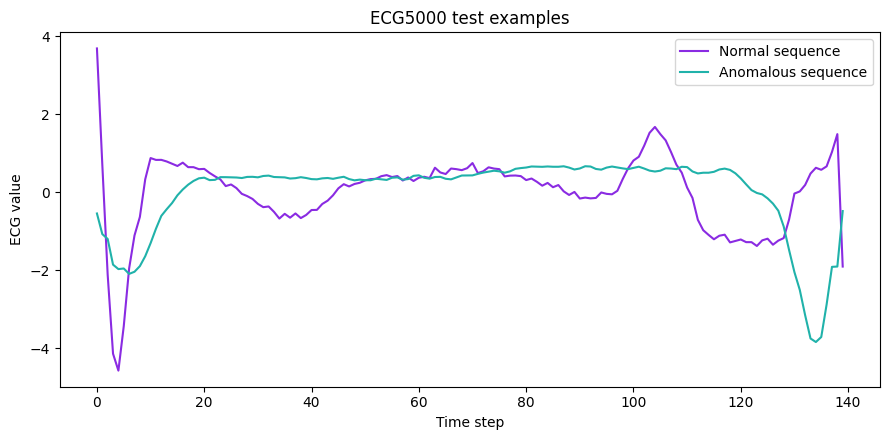

In [3]:
normal_index = int(np.flatnonzero(y_test == 0)[0])
anomaly_index = int(np.flatnonzero(y_test == 1)[0])

plt.figure(figsize=(9, 4.5))
plt.plot(X_test[normal_index], label='Normal sequence', color='blueviolet')
plt.plot(X_test[anomaly_index], label='Anomalous sequence', color='lightseagreen')
plt.xlabel('Time step')
plt.ylabel('ECG value')
plt.title('ECG5000 test examples')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / '01_normal_and_anomalous_sequences.png', dpi=180)
plt.show()


In [4]:
def flattened_features(X):
    return np.asarray(X, dtype=float).copy()


def global_summary_features(X):
    return np.column_stack([
        X.mean(axis=1),
        X.std(axis=1, ddof=1),
        X.min(axis=1),
        X.max(axis=1),
        np.median(X, axis=1),
    ])


def window_summary_features(X, n_windows=10):
    if X.shape[1] % n_windows != 0:
        raise ValueError('Sequence length must be divisible by n_windows.')
    window_size = X.shape[1] // n_windows
    reshaped = X.reshape(X.shape[0], n_windows, window_size)
    means = reshaped.mean(axis=2)
    stds = reshaped.std(axis=2, ddof=1)
    features = np.empty((X.shape[0], 2 * n_windows), dtype=float)
    features[:, 0::2] = means
    features[:, 1::2] = stds
    return features


REPRESENTATIONS = {
    'Flattened': lambda X: flattened_features(X),
    'Global summary': lambda X: global_summary_features(X),
    'Window summary': lambda X: window_summary_features(X, WINDOW_COUNT),
}

feature_cache = {
    name: {'train': function(X_train), 'test': function(X_test)}
    for name, function in REPRESENTATIONS.items()
}

feature_dimensions = pd.DataFrame([
    {'Representation': name, 'Dimension': values['train'].shape[1]}
    for name, values in feature_cache.items()
])
print('FEATURE DIMENSIONS')
display(feature_dimensions)


FEATURE DIMENSIONS


,Representation,Dimension
0,Flattened,140
1,Global summary,5
2,Window summary,20


In [5]:
def fit_and_evaluate(X_train_features, X_test_features, y_true, nu):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_features)
    X_test_scaled = scaler.transform(X_test_features)

    model = OneClassSVM(kernel='rbf', gamma='scale', nu=nu)
    model.fit(X_train_scaled)

    normality_scores = model.decision_function(X_test_scaled).ravel()
    anomaly_scores = -normality_scores
    y_pred = (normality_scores < 0).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    fpr, tpr, thresholds = roc_curve(y_true, anomaly_scores)

    metrics = {
        'nu': float(nu),
        'ROC-AUC': roc_auc_score(y_true, anomaly_scores),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'Predicted anomaly fraction': float(y_pred.mean()),
        'Support vectors': int(model.support_.size),
        'Support vector fraction': float(model.support_.size / len(X_train_scaled)),
    }

    return {
        'scaler': scaler,
        'model': model,
        'normality_scores': normality_scores,
        'anomaly_scores': anomaly_scores,
        'y_pred': y_pred,
        'fpr': fpr,
        'tpr': tpr,
        'thresholds': thresholds,
        'metrics': metrics,
    }


In [6]:
print('SIMULATION QUESTION 1')
baseline_representation = 'Flattened'
sim1 = fit_and_evaluate(
    feature_cache[baseline_representation]['train'],
    feature_cache[baseline_representation]['test'],
    y_test,
    BASELINE_NU,
)

sim1_table = pd.DataFrame([{
    'Representation': baseline_representation,
    'Preprocessing': 'StandardScaler fit on train only',
    'Kernel': 'RBF',
    'gamma': 'scale',
    **sim1['metrics'],
}])
sim1_table.to_csv(RESULTS_DIR / 'simulation_1_results.csv', index=False)
display(sim1_table)


SIMULATION QUESTION 1


,Representation,Preprocessing,Kernel,gamma,nu,ROC-AUC,Precision,Recall,F1,TN,FP,FN,TP,Predicted anomaly fraction,Support vectors,Support vector fraction
0,Flattened,StandardScaler fit on train only,RBF,scale,0.1,0.984025,0.831406,0.997864,0.907061,2248,379,4,1869,0.499556,54,0.184932


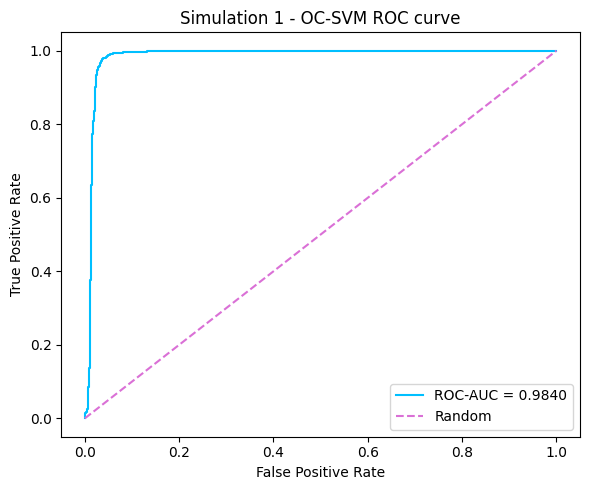

In [7]:
plt.figure(figsize=(6, 5))
plt.plot(sim1['fpr'], sim1['tpr'], label=f"ROC-AUC = {sim1['metrics']['ROC-AUC']:.4f}", color='deepskyblue')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random', color='orchid')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Simulation 1 - OC-SVM ROC curve')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / '02_simulation_1_roc_curve.png', dpi=180)
plt.show()

<Figure size 550x450 with 0 Axes>

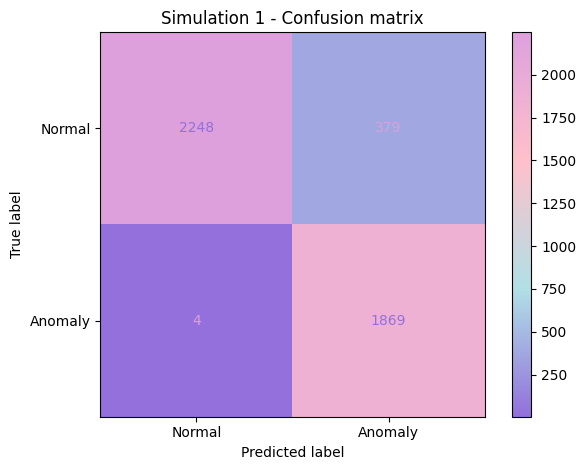

In [8]:
from matplotlib.colors import LinearSegmentedColormap

my_cmap = LinearSegmentedColormap.from_list(
    "my_cmap",
    ["mediumpurple", "powderblue","pink","plum"]   
)

plt.figure(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    sim1['y_pred'],
    labels=[0, 1],
    display_labels=['Normal', 'Anomaly'],
    cmap=my_cmap  
)
plt.title('Simulation 1 - Confusion matrix')
plt.tight_layout()
plt.savefig(RESULTS_DIR / '03_simulation_1_confusion_matrix.png', dpi=180)
plt.show()

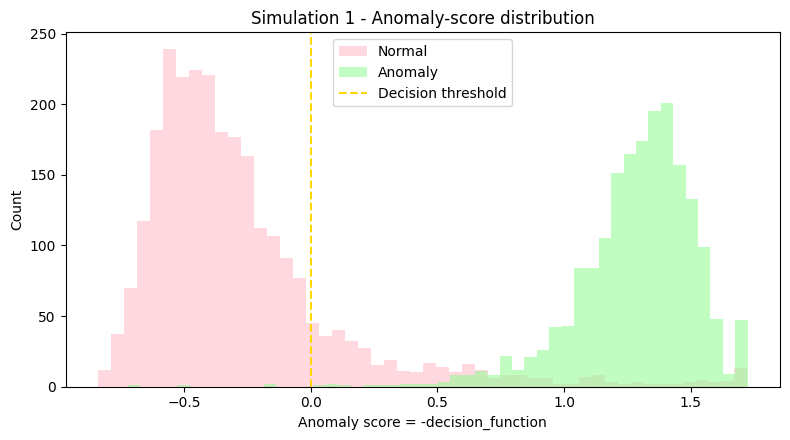

In [9]:
plt.figure(figsize=(8, 4.5))
plt.hist(sim1['anomaly_scores'][y_test == 0], bins=50, alpha=0.6, label='Normal', color='pink')
plt.hist(sim1['anomaly_scores'][y_test == 1], bins=50, alpha=0.6, label='Anomaly', color='palegreen')
plt.axvline(0, linestyle='--', label='Decision threshold', color='gold')
plt.xlabel('Anomaly score = -decision_function')
plt.ylabel('Count')
plt.title('Simulation 1 - Anomaly-score distribution')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / '04_simulation_1_score_distribution.png', dpi=180)
plt.show()


In [10]:
print('SIMULATION QUESTION 2')
sim2_runs = {}
sim2_rows = []

for representation_name in REPRESENTATIONS:
    run = fit_and_evaluate(
        feature_cache[representation_name]['train'],
        feature_cache[representation_name]['test'],
        y_test,
        BASELINE_NU,
    )
    sim2_runs[representation_name] = run
    sim2_rows.append({
        'Representation': representation_name,
        'Dimension': feature_cache[representation_name]['train'].shape[1],
        **run['metrics'],
    })

sim2_table = pd.DataFrame(sim2_rows).sort_values(
    ['ROC-AUC', 'F1'], ascending=False
).reset_index(drop=True)
sim2_table.to_csv(RESULTS_DIR / 'simulation_2_representation_comparison.csv', index=False)
display(sim2_table)


SIMULATION QUESTION 2


,Representation,Dimension,nu,ROC-AUC,Precision,Recall,F1,TN,FP,FN,TP,Predicted anomaly fraction,Support vectors,Support vector fraction
0,Flattened,140,0.1,0.984025,0.831406,0.997864,0.907061,2248,379,4,1869,0.499556,54,0.184932
1,Window summary,20,0.1,0.982276,0.831851,0.998398,0.907547,2249,378,3,1870,0.499556,53,0.181507
2,Global summary,5,0.1,0.951839,0.812442,0.927389,0.866118,2226,401,136,1737,0.475111,48,0.164384


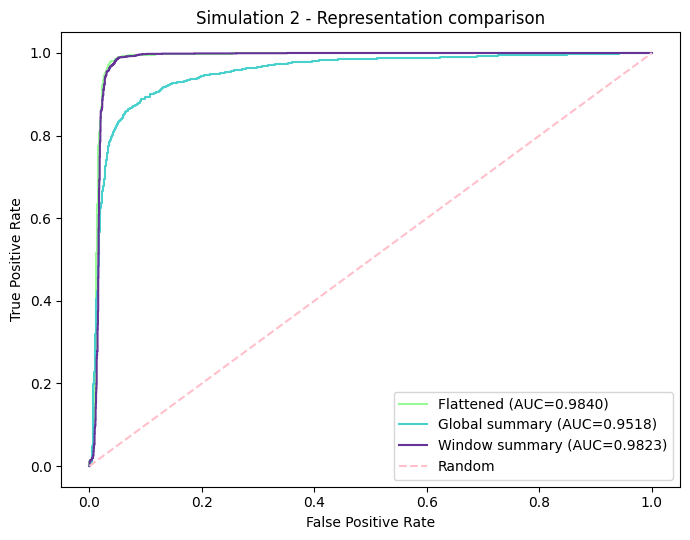

In [11]:
colors = {
    'Flattened': 'palegreen',      
    'Global summary': 'mediumturquoise', 
    'Window summary': 'rebeccapurple' 
}

plt.figure(figsize=(7, 5.5))
for name, run in sim2_runs.items():
    plt.plot(run['fpr'], run['tpr'], label=f"{name} (AUC={run['metrics']['ROC-AUC']:.4f})", color=colors[name])
plt.plot([0, 1], [0, 1], linestyle='--', label='Random', color='pink')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Simulation 2 - Representation comparison')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / '05_simulation_2_roc_curves.png', dpi=180)
plt.show()


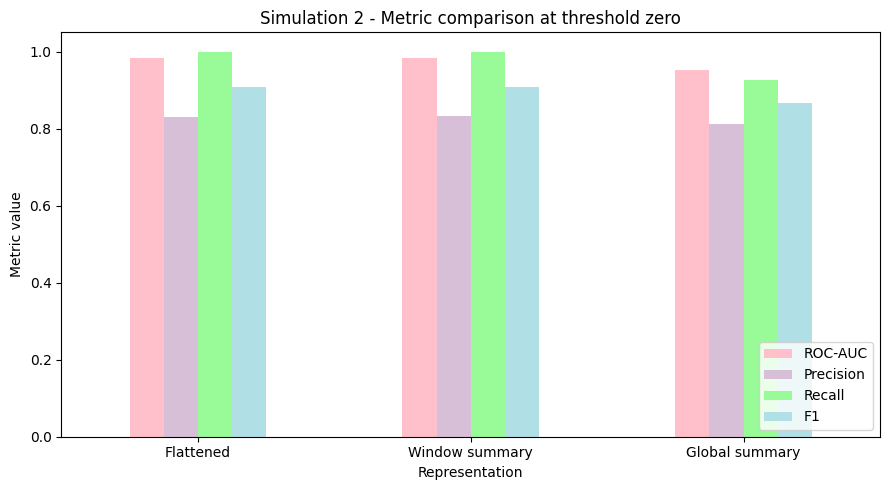

In [12]:
metric_table = sim2_table.set_index('Representation')[['ROC-AUC', 'Precision', 'Recall', 'F1']]
plt.figure(figsize=(9, 5))
metric_table.plot(kind='bar', ax=plt.gca(), color=['pink', 'thistle', 'palegreen', 'powderblue'])
plt.xlabel('Representation')
plt.ylabel('Metric value')
plt.title('Simulation 2 - Metric comparison at threshold zero')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(RESULTS_DIR / '06_simulation_2_metric_comparison.png', dpi=180)
plt.show()


In [13]:
print('SIMULATION QUESTION 3')
sim3_runs = {}
sim3_rows = []

for nu in NU_VALUES:
    run = fit_and_evaluate(
        feature_cache[baseline_representation]['train'],
        feature_cache[baseline_representation]['test'],
        y_test,
        nu,
    )
    sim3_runs[nu] = run
    sim3_rows.append(run['metrics'])

sim3_table = pd.DataFrame(sim3_rows).sort_values('nu').reset_index(drop=True)
sim3_table.to_csv(RESULTS_DIR / 'simulation_3_nu_sensitivity.csv', index=False)
display(sim3_table)


SIMULATION QUESTION 3


,nu,ROC-AUC,Precision,Recall,F1,TN,FP,FN,TP,Predicted anomaly fraction,Support vectors,Support vector fraction
0,0.01,0.984247,0.831776,0.997864,0.907282,2249,378,4,1869,0.499333,54,0.184932
1,0.05,0.984254,0.832146,0.997864,0.907502,2250,377,4,1869,0.499111,54,0.184932
2,0.10,0.984025,0.831406,0.997864,0.907061,2248,379,4,1869,0.499556,54,0.184932
3,0.20,0.980069,0.797695,0.997864,0.886622,2153,474,4,1869,0.520667,68,0.232877


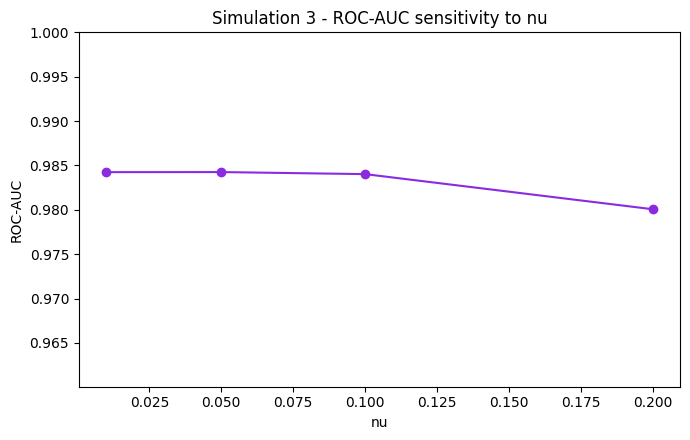

In [14]:
plt.figure(figsize=(7, 4.5))
plt.plot(sim3_table['nu'], sim3_table['ROC-AUC'], marker='o', color='blueviolet')
plt.xlabel('nu')
plt.ylabel('ROC-AUC')
plt.title('Simulation 3 - ROC-AUC sensitivity to nu')
plt.ylim(max(0.0, sim3_table['ROC-AUC'].min() - 0.02), 1.0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / '07_simulation_3_auc_vs_nu.png', dpi=180)
plt.show()


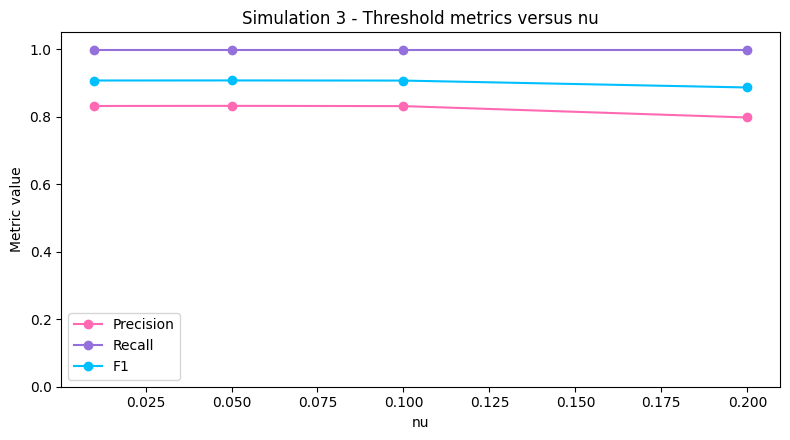

In [15]:
colors = {
    'Precision': 'hotpink', 
    'Recall': 'mediumpurple',    
    'F1': 'deepskyblue'          
}
plt.figure(figsize=(8, 4.5))
for metric in ['Precision', 'Recall', 'F1']:
    plt.plot(sim3_table['nu'], sim3_table[metric], marker='o', label=metric, color=colors[metric])
plt.xlabel('nu')
plt.ylabel('Metric value')
plt.title('Simulation 3 - Threshold metrics versus nu')
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / '08_simulation_3_threshold_metrics.png', dpi=180)
plt.show()

In [16]:
print('SIMULATION QUESTION 4')

def markov_chain_log_probability(z, pi, A):
    z = np.asarray(z, dtype=int)
    pi = np.asarray(pi, dtype=float)
    A = np.asarray(A, dtype=float)

    if z.ndim != 1 or z.size == 0:
        raise ValueError('z must be a non-empty one-dimensional state sequence.')
    if pi.ndim != 1 or pi.size == 0:
        raise ValueError('pi must be a non-empty one-dimensional probability vector.')

    n_states = pi.size

    if A.shape != (n_states, n_states):
        raise ValueError('A must have shape (K, K), where K = len(pi).')
    if not np.all(np.isfinite(pi)) or not np.all(np.isfinite(A)):
        raise ValueError('pi and A must contain only finite values.')
    if np.any(pi < 0) or np.any(A < 0):
        raise ValueError('Probabilities cannot be negative.')
    if not np.isclose(pi.sum(), 1.0):
        raise ValueError('The entries of pi must sum to 1.')
    if not np.allclose(A.sum(axis=1), 1.0):
        raise ValueError('Every row of A must sum to 1.')
    if z.min() < 1 or z.max() > n_states:
        raise ValueError('State labels in z must be integers from 1 to K.')

    state_indices = z - 1
    initial_probability = pi[state_indices[0]]
    transition_probabilities = A[state_indices[:-1], state_indices[1:]]

    if initial_probability == 0 or np.any(transition_probabilities == 0):
        return -np.inf

    return float(
        np.log(initial_probability)
        + np.log(transition_probabilities).sum()
    )


pi_sim4 = np.array([0.8, 0.2], dtype=float)
A_sim4 = np.array([
    [0.9, 0.1],
    [0.3, 0.7],
], dtype=float)
z_sim4 = np.array([1, 1, 2, 2, 1], dtype=int)

sim4_log_probability = markov_chain_log_probability(
    z_sim4,
    pi_sim4,
    A_sim4,
)

z0_sim4 = z_sim4 - 1
sim4_raw_probability = float(
    pi_sim4[z0_sim4[0]]
    * np.prod(A_sim4[z0_sim4[:-1], z0_sim4[1:]])
)
sim4_probability_from_log = float(np.exp(sim4_log_probability))

assert np.isclose(sim4_probability_from_log, sim4_raw_probability)
assert np.isclose(sim4_log_probability, np.log(sim4_raw_probability))

sim4_table = pd.DataFrame([{
    'State sequence z': str(z_sim4.tolist()),
    'Initial distribution pi': str(pi_sim4.tolist()),
    'Transition matrix A': str(A_sim4.tolist()),
    'Raw probability': sim4_raw_probability,
    'Log-probability': sim4_log_probability,
    'exp(Log-probability)': sim4_probability_from_log,
    'Consistency check': bool(
        np.isclose(sim4_probability_from_log, sim4_raw_probability)
    ),
}])

sim4_table.to_csv(
    RESULTS_DIR / 'simulation_4_markov_log_probability.csv',
    index=False,
)
display(sim4_table)


SIMULATION QUESTION 4


,State sequence z,Initial distribution pi,Transition matrix A,Raw probability,Log-probability,exp(Log-probability),Consistency check
0,"[1, 1, 2, 2, 1]","[0.8, 0.2]","[[0.9, 0.1], [0.3, 0.7]]",0.01512,-4.191737,0.01512,True


SIMULATION QUESTION 5


,T,pi,A,emission_means,emission_variances,state_1_count,state_2_count,state_1_empirical_mean,state_2_empirical_mean,state_1_empirical_variance,state_2_empirical_variance,transition_count
0,200,"[0.7, 0.3]","[[0.95, 0.05], [0.1, 0.9]]","[0.0, 4.0]","[1.0, 1.0]",127,73,-0.029133,4.327822,0.943462,1.109157,20


,time_step,hidden_state_z,observation_x
0,1,1,-1.546812
1,2,2,5.157465
2,3,2,4.746686
3,4,1,0.764251
4,5,1,-0.218160
5,6,1,1.838186
6,7,1,0.640754
7,8,1,0.836988
8,9,1,-0.283488
9,10,1,0.406268


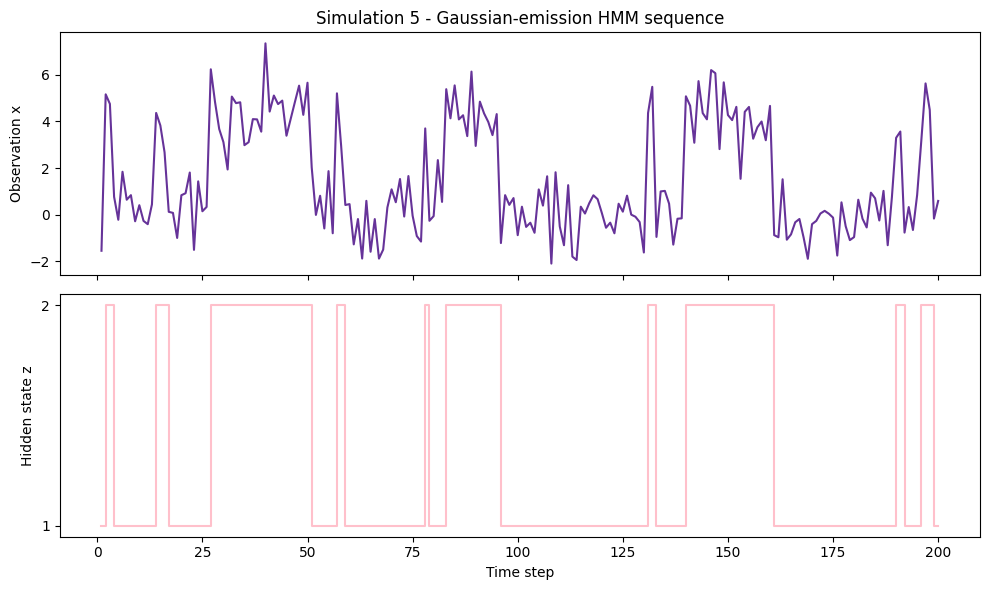

In [17]:
print('SIMULATION QUESTION 5')

def generate_two_state_gaussian_hmm(
    pi,
    A,
    emission_means,
    emission_variances,
    T,
    random_state=None,
):
    pi = np.asarray(pi, dtype=float)
    A = np.asarray(A, dtype=float)
    emission_means = np.asarray(emission_means, dtype=float)
    emission_variances = np.asarray(emission_variances, dtype=float)

    if pi.shape != (2,):
        raise ValueError('pi must have shape (2,).')
    if A.shape != (2, 2):
        raise ValueError('A must have shape (2, 2).')
    if emission_means.shape != (2,) or emission_variances.shape != (2,):
        raise ValueError('Emission means and variances must each have shape (2,).')
    if not isinstance(T, (int, np.integer)) or T <= 0:
        raise ValueError('T must be a positive integer.')
    if not np.all(np.isfinite(pi)) or not np.all(np.isfinite(A)):
        raise ValueError('pi and A must contain only finite values.')
    if np.any(pi < 0) or np.any(A < 0):
        raise ValueError('Probabilities cannot be negative.')
    if not np.isclose(pi.sum(), 1.0):
        raise ValueError('The entries of pi must sum to 1.')
    if not np.allclose(A.sum(axis=1), 1.0):
        raise ValueError('Every row of A must sum to 1.')
    if not np.all(np.isfinite(emission_means)):
        raise ValueError('Emission means must be finite.')
    if not np.all(np.isfinite(emission_variances)):
        raise ValueError('Emission variances must be finite.')
    if np.any(emission_variances <= 0):
        raise ValueError('Emission variances must be strictly positive.')

    rng = np.random.default_rng(random_state)
    z_zero_based = np.empty(T, dtype=int)
    x = np.empty(T, dtype=float)

    z_zero_based[0] = rng.choice(2, p=pi)
    x[0] = rng.normal(
        emission_means[z_zero_based[0]],
        np.sqrt(emission_variances[z_zero_based[0]]),
    )

    for t in range(1, T):
        z_zero_based[t] = rng.choice(
            2,
            p=A[z_zero_based[t - 1]],
        )
        x[t] = rng.normal(
            emission_means[z_zero_based[t]],
            np.sqrt(emission_variances[z_zero_based[t]]),
        )

    z = z_zero_based + 1
    return z, x


pi_sim5 = np.array([0.7, 0.3], dtype=float)
A_sim5 = np.array([
    [0.95, 0.05],
    [0.10, 0.90],
], dtype=float)
means_sim5 = np.array([0.0, 4.0], dtype=float)
variances_sim5 = np.array([1.0, 1.0], dtype=float)
T_sim5 = 200

z_sim5, x_sim5 = generate_two_state_gaussian_hmm(
    pi=pi_sim5,
    A=A_sim5,
    emission_means=means_sim5,
    emission_variances=variances_sim5,
    T=T_sim5,
    random_state=1405,
)

assert z_sim5.shape == (T_sim5,)
assert x_sim5.shape == (T_sim5,)
assert set(np.unique(z_sim5)).issubset({1, 2})
assert np.all(np.isfinite(x_sim5))

sim5_sequence = pd.DataFrame({
    'time_step': np.arange(1, T_sim5 + 1),
    'hidden_state_z': z_sim5,
    'observation_x': x_sim5,
})
sim5_sequence.to_csv(
    RESULTS_DIR / 'simulation_5_gaussian_hmm_sequence.csv',
    index=False,
)

sim5_summary = pd.DataFrame([{
    'T': T_sim5,
    'pi': str(pi_sim5.tolist()),
    'A': str(A_sim5.tolist()),
    'emission_means': str(means_sim5.tolist()),
    'emission_variances': str(variances_sim5.tolist()),

    'state_1_count': int((z_sim5 == 1).sum()),
    'state_2_count': int((z_sim5 == 2).sum()),

    'state_1_empirical_mean': float(
        x_sim5[z_sim5 == 1].mean()
    ),
    'state_2_empirical_mean': float(
        x_sim5[z_sim5 == 2].mean()
    ),

    'state_1_empirical_variance': float(
        x_sim5[z_sim5 == 1].var(ddof=1)
    ),
    'state_2_empirical_variance': float(
        x_sim5[z_sim5 == 2].var(ddof=1)
    ),

    'transition_count': int(
        np.sum(z_sim5[1:] != z_sim5[:-1])
    ),
}])

display(sim5_summary)
display(sim5_sequence.head(10))

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(sim5_sequence['time_step'], sim5_sequence['observation_x'], color='rebeccapurple')
axes[0].set_ylabel('Observation x')
axes[0].set_title('Simulation 5 - Gaussian-emission HMM sequence')

axes[1].step(
    sim5_sequence['time_step'],
    sim5_sequence['hidden_state_z'],
    where='post',
    color='pink'
)
axes[1].set_xlabel('Time step')
axes[1].set_ylabel('Hidden state z')
axes[1].set_yticks([1, 2])

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / '09_simulation_5_gaussian_hmm_sequence.png',
    dpi=180,
)
plt.show()


SIMULATION QUESTION 6


,Sequence length T,Correct time steps,Incorrect time steps,State recovery fraction,State recovery percentage,Best path log-probability
0,200,199,1,0.995,99.5,-352.998828


,time_step,observation_x,true_hidden_state,decoded_hidden_state,correct
0,1,-1.546812,1,1,True
1,2,5.157465,2,2,True
2,3,4.746686,2,2,True
3,4,0.764251,1,1,True
4,5,-0.218160,1,1,True
5,6,1.838186,1,1,True
6,7,0.640754,1,1,True
7,8,0.836988,1,1,True
8,9,-0.283488,1,1,True
9,10,0.406268,1,1,True


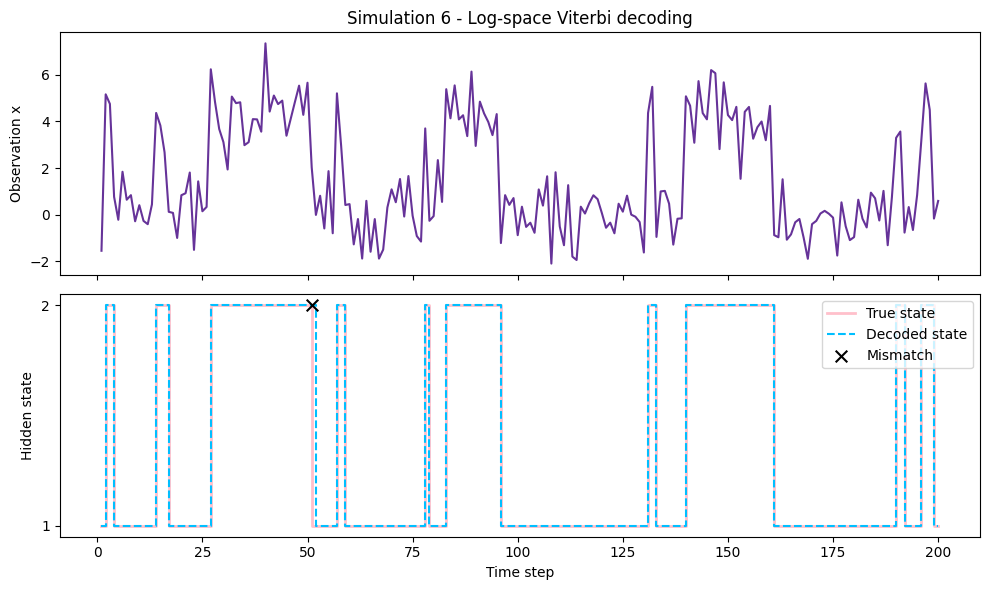

In [18]:
print('SIMULATION QUESTION 6')

def viterbi_log_gaussian_two_state(
    x,
    pi,
    A,
    emission_means,
    emission_variances,
):
    x = np.asarray(x, dtype=float)
    pi = np.asarray(pi, dtype=float)
    A = np.asarray(A, dtype=float)
    emission_means = np.asarray(emission_means, dtype=float)
    emission_variances = np.asarray(emission_variances, dtype=float)

    if x.ndim != 1 or x.size == 0:
        raise ValueError('x must be a non-empty one-dimensional sequence.')
    if pi.shape != (2,):
        raise ValueError('pi must have shape (2,).')
    if A.shape != (2, 2):
        raise ValueError('A must have shape (2, 2).')
    if emission_means.shape != (2,) or emission_variances.shape != (2,):
        raise ValueError('Emission means and variances must each have shape (2,).')
    if not np.all(np.isfinite(x)):
        raise ValueError('x must contain only finite observations.')
    if not np.all(np.isfinite(pi)) or not np.all(np.isfinite(A)):
        raise ValueError('pi and A must contain only finite values.')
    if np.any(pi < 0) or np.any(A < 0):
        raise ValueError('Probabilities cannot be negative.')
    if not np.isclose(pi.sum(), 1.0):
        raise ValueError('The entries of pi must sum to 1.')
    if not np.allclose(A.sum(axis=1), 1.0):
        raise ValueError('Every row of A must sum to 1.')
    if not np.all(np.isfinite(emission_means)):
        raise ValueError('Emission means must be finite.')
    if not np.all(np.isfinite(emission_variances)):
        raise ValueError('Emission variances must be finite.')
    if np.any(emission_variances <= 0):
        raise ValueError('Emission variances must be strictly positive.')

    T = x.size

    with np.errstate(divide='ignore'):
        log_pi = np.log(pi)
        log_A = np.log(A)

    def gaussian_log_emission(value):
        return -0.5 * (
            np.log(2.0 * np.pi * emission_variances)
            + ((value - emission_means) ** 2) / emission_variances
        )

    log_delta = np.empty((T, 2), dtype=float)
    backpointer = np.zeros((T, 2), dtype=int)

    log_delta[0] = log_pi + gaussian_log_emission(x[0])

    for t in range(1, T):
        candidate_scores = log_delta[t - 1][:, None] + log_A
        backpointer[t] = np.argmax(candidate_scores, axis=0)
        log_delta[t] = (
            np.max(candidate_scores, axis=0)
            + gaussian_log_emission(x[t])
        )

    decoded_zero_based = np.empty(T, dtype=int)
    decoded_zero_based[-1] = int(np.argmax(log_delta[-1]))

    for t in range(T - 2, -1, -1):
        decoded_zero_based[t] = backpointer[
            t + 1,
            decoded_zero_based[t + 1],
        ]

    best_path_log_probability = float(
        log_delta[-1, decoded_zero_based[-1]]
    )
    decoded_states = decoded_zero_based + 1

    return decoded_states, best_path_log_probability


z_decoded_sim6, best_log_probability_sim6 = (
    viterbi_log_gaussian_two_state(
        x=x_sim5,
        pi=pi_sim5,
        A=A_sim5,
        emission_means=means_sim5,
        emission_variances=variances_sim5,
    )
)

sim6_correct = z_decoded_sim6 == z_sim5
sim6_accuracy = float(sim6_correct.mean())
sim6_correct_count = int(sim6_correct.sum())
sim6_error_count = int((~sim6_correct).sum())

assert z_decoded_sim6.shape == z_sim5.shape
assert set(np.unique(z_decoded_sim6)).issubset({1, 2})
assert 0.0 <= sim6_accuracy <= 1.0
assert np.isfinite(best_log_probability_sim6)

sim6_sequence = pd.DataFrame({
    'time_step': np.arange(1, T_sim5 + 1),
    'observation_x': x_sim5,
    'true_hidden_state': z_sim5,
    'decoded_hidden_state': z_decoded_sim6,
    'correct': sim6_correct,
})
sim6_sequence.to_csv(
    RESULTS_DIR / 'simulation_6_viterbi_decoding.csv',
    index=False,
)

sim6_summary = pd.DataFrame([{
    'Sequence length T': T_sim5,
    'Correct time steps': sim6_correct_count,
    'Incorrect time steps': sim6_error_count,
    'State recovery fraction': sim6_accuracy,
    'State recovery percentage': 100.0 * sim6_accuracy,
    'Best path log-probability': best_log_probability_sim6,
}])
sim6_summary.to_csv(
    RESULTS_DIR / 'simulation_6_viterbi_summary.csv',
    index=False,
)

display(sim6_summary)
display(sim6_sequence.head(10))

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(
    sim6_sequence['time_step'],
    sim6_sequence['observation_x'],
    color='rebeccapurple',
)
axes[0].set_ylabel('Observation x')
axes[0].set_title('Simulation 6 - Log-space Viterbi decoding')

axes[1].step(
    sim6_sequence['time_step'],
    sim6_sequence['true_hidden_state'],
    where='post',
    label='True state',
    color='pink',
    linewidth=2.0,
)
axes[1].step(
    sim6_sequence['time_step'],
    sim6_sequence['decoded_hidden_state'],
    where='post',
    label='Decoded state',
    color='deepskyblue',
    linestyle='--',
)

mismatch_rows = sim6_sequence.loc[~sim6_sequence['correct']]
if not mismatch_rows.empty:
    axes[1].scatter(
        mismatch_rows['time_step'],
        mismatch_rows['decoded_hidden_state'],
        marker='x',
        s=70,
        color='black',
        label='Mismatch',
        zorder=5,
    )

axes[1].set_xlabel('Time step')
axes[1].set_ylabel('Hidden state')
axes[1].set_yticks([1, 2])
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / '10_simulation_6_viterbi_decoding.png',
    dpi=180,
)
plt.show()


SIMULATION QUESTION 7


,Sequence length T,Initial distribution pi,Transition matrix A,First subnormal time step,First zero time step,Final raw probability,Final log-probability,exp(Final log-probability),Float64 minimum normal,Float64 minimum positive,Log result remains finite
0,5000,"[0.7, 0.3]","[[0.95, 0.05], [0.1, 0.9]]",3010,3206,0.0,-1174.945544,0.0,2.225074e-308,4.940656e-324,True


,time_step,state_z,step_probability,raw_cumulative_probability,log_cumulative_probability,raw_is_zero
3200,3201,1,0.95,2.964394e-323,-742.795852,False
3201,3202,1,0.95,2.964394e-323,-742.847145,False
3202,3203,1,0.95,2.964394e-323,-742.898439,False
3203,3204,1,0.95,2.964394e-323,-742.949732,False
3204,3205,1,0.95,2.964394e-323,-743.001025,False
3205,3206,2,0.05,0.000000e+00,-745.996758,True
3206,3207,2,0.90,0.000000e+00,-746.102118,True
3207,3208,2,0.90,0.000000e+00,-746.207479,True
3208,3209,1,0.10,0.000000e+00,-748.510064,True
3209,3210,1,0.95,0.000000e+00,-748.561357,True


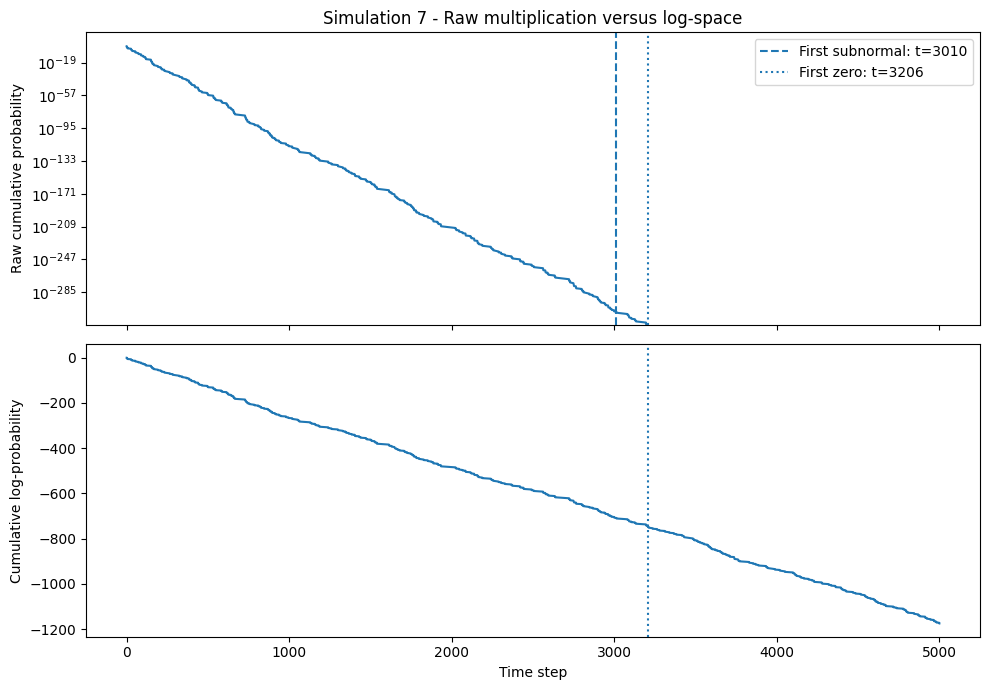

In [19]:
print('SIMULATION QUESTION 7')

def generate_markov_state_sequence(pi, A, T, random_state=None):
    pi = np.asarray(pi, dtype=float)
    A = np.asarray(A, dtype=float)

    if pi.ndim != 1 or pi.size == 0:
        raise ValueError('pi must be a non-empty one-dimensional probability vector.')
    if A.shape != (pi.size, pi.size):
        raise ValueError('A must have shape (K, K), where K = len(pi).')
    if not isinstance(T, (int, np.integer)) or T <= 0:
        raise ValueError('T must be a positive integer.')
    if np.any(pi < 0) or np.any(A < 0):
        raise ValueError('Probabilities cannot be negative.')
    if not np.isclose(pi.sum(), 1.0):
        raise ValueError('The entries of pi must sum to 1.')
    if not np.allclose(A.sum(axis=1), 1.0):
        raise ValueError('Every row of A must sum to 1.')

    rng = np.random.default_rng(random_state)
    states_zero_based = np.empty(T, dtype=int)
    states_zero_based[0] = rng.choice(pi.size, p=pi)

    for t in range(1, T):
        states_zero_based[t] = rng.choice(
            pi.size,
            p=A[states_zero_based[t - 1]],
        )

    return states_zero_based + 1


T_sim7 = 5000
pi_sim7 = np.array([0.7, 0.3], dtype=float)
A_sim7 = np.array([
    [0.95, 0.05],
    [0.10, 0.90],
], dtype=float)

z_sim7 = generate_markov_state_sequence(
    pi=pi_sim7,
    A=A_sim7,
    T=T_sim7,
    random_state=1405,
)

z0_sim7 = z_sim7 - 1
step_probabilities_sim7 = np.empty(T_sim7, dtype=float)
step_probabilities_sim7[0] = pi_sim7[z0_sim7[0]]
step_probabilities_sim7[1:] = A_sim7[
    z0_sim7[:-1],
    z0_sim7[1:],
]

raw_cumulative_probability_sim7 = np.empty(T_sim7, dtype=float)
log_cumulative_probability_sim7 = np.empty(T_sim7, dtype=float)

raw_value_sim7 = 1.0
log_value_sim7 = 0.0

for t, probability in enumerate(step_probabilities_sim7):
    raw_value_sim7 *= probability
    log_value_sim7 += np.log(probability)
    raw_cumulative_probability_sim7[t] = raw_value_sim7
    log_cumulative_probability_sim7[t] = log_value_sim7

float_info_sim7 = np.finfo(np.float64)
smallest_subnormal_sim7 = np.nextafter(np.float64(0), np.float64(1))

subnormal_indices_sim7 = np.flatnonzero(
    (raw_cumulative_probability_sim7 > 0.0)
    & (raw_cumulative_probability_sim7 < float_info_sim7.tiny)
)
zero_indices_sim7 = np.flatnonzero(
    raw_cumulative_probability_sim7 == 0.0
)

first_subnormal_step_sim7 = (
    int(subnormal_indices_sim7[0] + 1)
    if subnormal_indices_sim7.size
    else None
)
first_zero_step_sim7 = (
    int(zero_indices_sim7[0] + 1)
    if zero_indices_sim7.size
    else None
)

with np.errstate(under='ignore'):
    final_probability_from_log_sim7 = float(
        np.exp(log_cumulative_probability_sim7[-1])
    )

sim7_summary = pd.DataFrame([{
    'Sequence length T': T_sim7,
    'Initial distribution pi': str(pi_sim7.tolist()),
    'Transition matrix A': str(A_sim7.tolist()),
    'First subnormal time step': first_subnormal_step_sim7,
    'First zero time step': first_zero_step_sim7,
    'Final raw probability': float(raw_cumulative_probability_sim7[-1]),
    'Final log-probability': float(log_cumulative_probability_sim7[-1]),
    'exp(Final log-probability)': final_probability_from_log_sim7,
    'Float64 minimum normal': float_info_sim7.tiny,
    'Float64 minimum positive': smallest_subnormal_sim7,
    'Log result remains finite': bool(
        np.isfinite(log_cumulative_probability_sim7[-1])
    ),
}])

sim7_steps = pd.DataFrame({
    'time_step': np.arange(1, T_sim7 + 1),
    'state_z': z_sim7,
    'step_probability': step_probabilities_sim7,
    'raw_cumulative_probability': raw_cumulative_probability_sim7,
    'log_cumulative_probability': log_cumulative_probability_sim7,
    'raw_is_zero': raw_cumulative_probability_sim7 == 0.0,
})

if first_zero_step_sim7 is not None:
    detail_start_sim7 = max(0, first_zero_step_sim7 - 6)
    detail_end_sim7 = min(T_sim7, first_zero_step_sim7 + 5)
else:
    detail_start_sim7 = max(0, T_sim7 - 10)
    detail_end_sim7 = T_sim7

sim7_underflow_detail = sim7_steps.iloc[
    detail_start_sim7:detail_end_sim7
].copy()

sim7_summary.to_csv(
    RESULTS_DIR / 'simulation_7_underflow_summary.csv',
    index=False,
)
sim7_steps.to_csv(
    RESULTS_DIR / 'simulation_7_underflow_steps.csv',
    index=False,
)

assert z_sim7.shape == (T_sim7,)
assert np.isfinite(log_cumulative_probability_sim7[-1])
assert first_zero_step_sim7 is not None
assert raw_cumulative_probability_sim7[-1] == 0.0

display(sim7_summary)
display(sim7_underflow_detail)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

positive_raw_sim7 = np.where(
    raw_cumulative_probability_sim7 > 0.0,
    raw_cumulative_probability_sim7,
    np.nan,
)
axes[0].semilogy(
    sim7_steps['time_step'],
    positive_raw_sim7,
)
if first_subnormal_step_sim7 is not None:
    axes[0].axvline(
        first_subnormal_step_sim7,
        linestyle='--',
        label=f'First subnormal: t={first_subnormal_step_sim7}',
    )
if first_zero_step_sim7 is not None:
    axes[0].axvline(
        first_zero_step_sim7,
        linestyle=':',
        label=f'First zero: t={first_zero_step_sim7}',
    )
axes[0].set_ylabel('Raw cumulative probability')
axes[0].set_title('Simulation 7 - Raw multiplication versus log-space')
axes[0].legend()

axes[1].plot(
    sim7_steps['time_step'],
    sim7_steps['log_cumulative_probability'],
)
if first_zero_step_sim7 is not None:
    axes[1].axvline(
        first_zero_step_sim7,
        linestyle=':',
    )
axes[1].set_xlabel('Time step')
axes[1].set_ylabel('Cumulative log-probability')

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / '11_simulation_7_probability_underflow.png',
    dpi=180,
)
plt.show()


SIMULATION QUESTION 8


,Statistic,x1_contiguous,x2_shuffled,Absolute difference
0,Mean,2.224489,2.224489,0.0
1,Variance,5.398221,5.398221,0.0
2,Minimum,-2.667128,-2.667128,0.0
3,Maximum,7.342410,7.342410,0.0


,Sequence,State 1 count,State 2 count,Count 1->1,Count 1->2,Count 2->1,Count 2->2
0,x1_contiguous,51,49,47,4,3,45
1,x2_shuffled,51,49,28,22,22,27


,Feature,"Psi(x1, z1)","Psi(x2, z2)",Signed difference (x2-x1),Absolute difference
0,c11,47.000000,28.000000,-1.900000e+01,1.900000e+01
1,c12,4.000000,22.000000,1.800000e+01,1.800000e+01
2,c21,3.000000,22.000000,1.900000e+01,1.900000e+01
3,c22,45.000000,27.000000,-1.800000e+01,1.800000e+01
4,Emission sum state 1,9.329913,9.329913,1.776357e-15,1.776357e-15
5,Emission sum state 2,213.119005,213.119005,-2.842171e-14,2.842171e-14


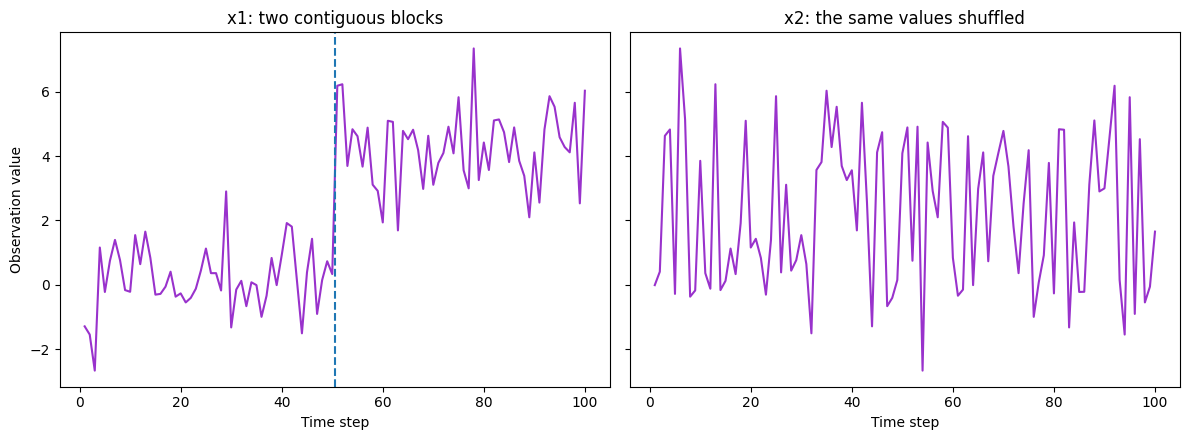

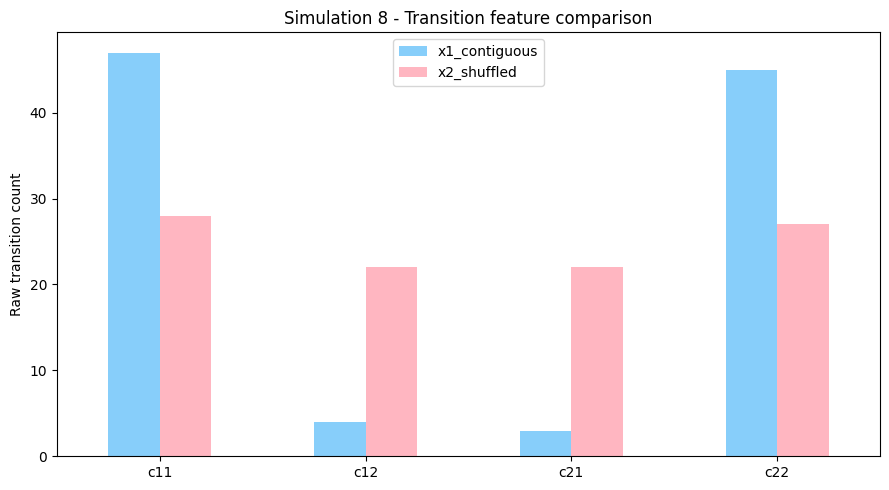

In [20]:
print('SIMULATION QUESTION 8')

def compute_joint_features_sim8(x, z, K=2):
    x = np.asarray(x, dtype=float)
    z = np.asarray(z, dtype=int)

    if x.ndim != 1 or z.ndim != 1 or x.size != z.size:
        raise ValueError('x and z must be one-dimensional arrays with equal length.')

    if x.size < 2:
        raise ValueError('The sequence must contain at least two time steps.')

    if np.any((z < 1) | (z > K)):
        raise ValueError('State labels must be integers from 1 to K.')

    transition_counts = np.zeros((K, K), dtype=int)

    for t in range(x.size - 1):
        transition_counts[z[t] - 1, z[t + 1] - 1] += 1

    emission_sums = np.zeros(K, dtype=float)
    state_counts = np.zeros(K, dtype=int)

    for state in range(1, K + 1):
        mask = z == state
        state_counts[state - 1] = int(mask.sum())
        emission_sums[state - 1] = x[mask].sum()

    joint_vector = np.concatenate([
        transition_counts.ravel().astype(float),
        emission_sums
    ])

    return joint_vector, transition_counts, state_counts


rng_sim8 = np.random.default_rng(1405)

values_normal_sim8 = rng_sim8.normal(
    loc=0.0,
    scale=1.0,
    size=50
)

values_shifted_sim8 = rng_sim8.normal(
    loc=4.0,
    scale=1.0,
    size=50
)

x1_sim8 = np.concatenate([
    values_normal_sim8,
    values_shifted_sim8
])

x2_sim8 = rng_sim8.permutation(x1_sim8)


summary_sim8 = pd.DataFrame({
    'Statistic': [
        'Mean',
        'Variance',
        'Minimum',
        'Maximum'
    ],

    'x1_contiguous': [
        x1_sim8.mean(),
        x1_sim8.var(ddof=0),
        x1_sim8.min(),
        x1_sim8.max()
    ],

    'x2_shuffled': [
        x2_sim8.mean(),
        x2_sim8.var(ddof=0),
        x2_sim8.min(),
        x2_sim8.max()
    ]
})

summary_sim8['Absolute difference'] = np.abs(
    summary_sim8['x1_contiguous']
    - summary_sim8['x2_shuffled']
)


z1_sim8 = np.where(
    x1_sim8 < 2.0,
    1,
    2
)

z2_sim8 = np.where(
    x2_sim8 < 2.0,
    1,
    2
)


(
    psi1_sim8,
    transition_counts_x1_sim8,
    state_counts_x1_sim8
) = compute_joint_features_sim8(
    x1_sim8,
    z1_sim8,
    K=2
)

(
    psi2_sim8,
    transition_counts_x2_sim8,
    state_counts_x2_sim8
) = compute_joint_features_sim8(
    x2_sim8,
    z2_sim8,
    K=2
)


feature_names_sim8 = [
    'c11',
    'c12',
    'c21',
    'c22',
    'Emission sum state 1',
    'Emission sum state 2'
]


joint_features_sim8 = pd.DataFrame({
    'Feature': feature_names_sim8,
    'Psi(x1, z1)': psi1_sim8,
    'Psi(x2, z2)': psi2_sim8
})

joint_features_sim8[
    'Signed difference (x2-x1)'
] = (
    joint_features_sim8['Psi(x2, z2)']
    - joint_features_sim8['Psi(x1, z1)']
)

joint_features_sim8[
    'Absolute difference'
] = np.abs(
    joint_features_sim8[
        'Signed difference (x2-x1)'
    ]
)


transition_table_sim8 = pd.DataFrame({
    'Sequence': [
        'x1_contiguous',
        'x2_shuffled'
    ],

    'State 1 count': [
        state_counts_x1_sim8[0],
        state_counts_x2_sim8[0]
    ],

    'State 2 count': [
        state_counts_x1_sim8[1],
        state_counts_x2_sim8[1]
    ],

    'Count 1->1': [
        transition_counts_x1_sim8[0, 0],
        transition_counts_x2_sim8[0, 0]
    ],

    'Count 1->2': [
        transition_counts_x1_sim8[0, 1],
        transition_counts_x2_sim8[0, 1]
    ],

    'Count 2->1': [
        transition_counts_x1_sim8[1, 0],
        transition_counts_x2_sim8[1, 0]
    ],

    'Count 2->2': [
        transition_counts_x1_sim8[1, 1],
        transition_counts_x2_sim8[1, 1]
    ]
})


assert np.allclose(
    np.sort(x1_sim8),
    np.sort(x2_sim8)
)

assert np.allclose(
    summary_sim8['Absolute difference'],
    0.0,
    atol=1e-12
)

assert np.allclose(
    psi1_sim8[4:],
    psi2_sim8[4:],
    atol=1e-12
)

assert not np.allclose(
    psi1_sim8[:4],
    psi2_sim8[:4]
)


summary_sim8.to_csv(
    RESULTS_DIR / 'simulation_8_summary_statistics.csv',
    index=False
)

joint_features_sim8.to_csv(
    RESULTS_DIR / 'simulation_8_joint_features.csv',
    index=False
)

transition_table_sim8.to_csv(
    RESULTS_DIR

/ 'simulation_8_transition_counts.csv',
    index=False
)


sequence_data_sim8 = pd.DataFrame({
    'time_step': np.arange(1, 101),

    'x1_contiguous': x1_sim8,
    'z1': z1_sim8,

    'x2_shuffled': x2_sim8,
    'z2': z2_sim8
})

sequence_data_sim8.to_csv(
    RESULTS_DIR / 'simulation_8_sequences.csv',
    index=False
)


display(summary_sim8)
display(transition_table_sim8)
display(joint_features_sim8)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5),
    sharey=True
)

axes[0].plot(
    np.arange(1, 101),
    x1_sim8,
    color='darkorchid',
    linewidth=1.5
)

axes[0].axvline(
    50.5,
    linestyle='--'
)

axes[0].set_title(
    'x1: two contiguous blocks'
)

axes[0].set_xlabel(
    'Time step'
)

axes[0].set_ylabel(
    'Observation value'
)


axes[1].plot(
    np.arange(1, 101),
    x2_sim8,
    color='darkorchid',linewidth=1.5
)

axes[1].set_title(
    'x2: the same values shuffled'
)

axes[1].set_xlabel(
    'Time step'
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR
    / '12_simulation_8_sequences_side_by_side.png',
    dpi=180
)

plt.show()


transition_comparison_sim8 = pd.DataFrame({
    'x1_contiguous': psi1_sim8[:4],
    'x2_shuffled': psi2_sim8[:4]
}, index=[
    'c11',
    'c12',
    'c21',
    'c22'
])

ax = transition_comparison_sim8.plot(
    kind='bar',
    figsize=(9, 5),color=['lightskyblue', 'lightpink']
)

ax.set_ylabel(
    'Raw transition count'
)

ax.set_title(
    'Simulation 8 - Transition feature comparison'
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR
    / '13_simulation_8_joint_feature_comparison.png',
    dpi=180
)

plt.show()

SIMULATION QUESTION 9
FEATURE MATRIX SHAPE: (250, 6)


,Feature,Normal mean,Anomalous mean,Anomalous - Normal,Absolute mean difference,Effect size
0,Mean emission: state 2,2.100059,3.905188,1.805129,1.805129,2.524244
1,c11/(T-1),0.956869,0.755960,-0.200909,0.200909,-7.074847
2,c22/(T-1),0.000960,0.181212,0.180253,0.180253,23.920995
3,c21/(T-1),0.021010,0.031717,0.010707,0.010707,0.747471
4,c12/(T-1),0.021162,0.031111,0.009949,0.009949,0.700127
5,Mean emission: state 1,-0.049546,-0.057098,-0.007551,0.007551,-0.074954


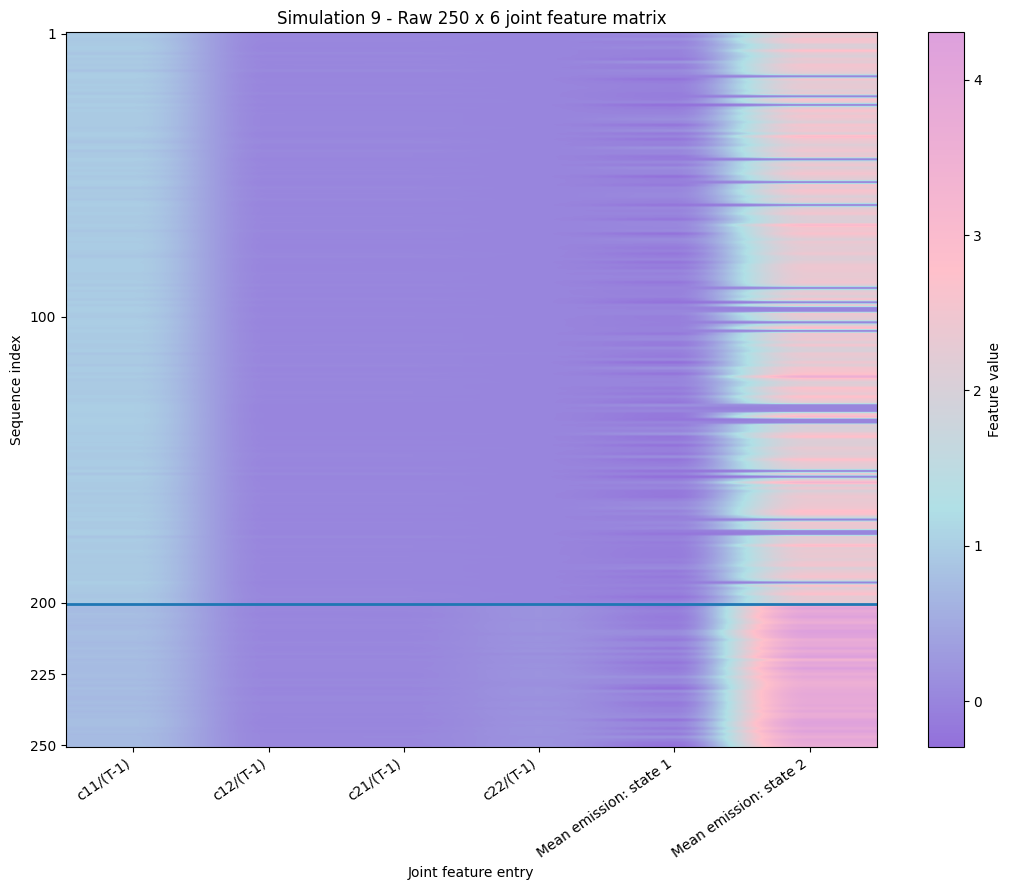

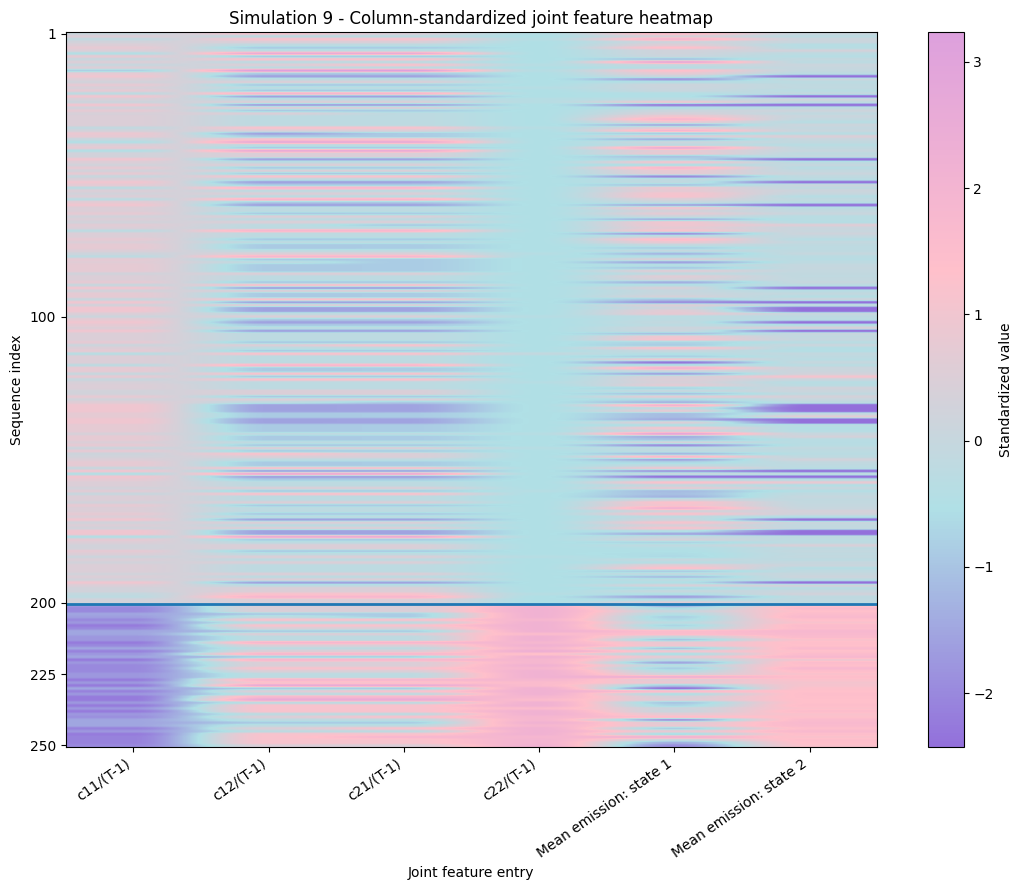

In [21]:
print('SIMULATION QUESTION 9')

def compute_joint_features(x, z, K, epsilon=1e-12):
    x = np.asarray(x, dtype=float)
    z = np.asarray(z, dtype=int)

    if x.ndim != 1 or z.ndim != 1 or x.size != z.size:
        raise ValueError('x and z must be one-dimensional arrays with equal length.')
    if x.size < 2:
        raise ValueError('The sequence must contain at least two time steps.')
    if not isinstance(K, (int, np.integer)) or K <= 0:
        raise ValueError('K must be a positive integer.')
    if np.any((z < 1) | (z > K)):
        raise ValueError('State labels must be integers from 1 to K.')
    if not np.all(np.isfinite(x)):
        raise ValueError('x must contain only finite values.')

    T = x.size
    transition_counts = np.zeros((K, K), dtype=float)
    np.add.at(
        transition_counts,
        (z[:-1] - 1, z[1:] - 1),
        1.0,
    )
    normalized_transitions = transition_counts / (T - 1)

    emission_means = np.zeros(K, dtype=float)
    for state in range(1, K + 1):
        state_mask = z == state
        emission_means[state - 1] = (
            x[state_mask].sum() / (state_mask.sum() + epsilon)
        )

    return np.concatenate([
        normalized_transitions.ravel(),
        emission_means,
    ])


rng_sim9 = np.random.default_rng(1405)
K_sim9 = 2
T_sim9 = 100
n_nominal_sim9 = 200
n_anomalous_sim9 = 50
anomaly_block_length_sim9 = 20

nominal_sequences_sim9 = rng_sim9.normal(
    loc=0.0,
    scale=1.0,
    size=(n_nominal_sim9, T_sim9),
)

anomalous_sequences_sim9 = rng_sim9.normal(
    loc=0.0,
    scale=1.0,
    size=(n_anomalous_sim9, T_sim9),
)
anomaly_starts_sim9 = rng_sim9.integers(
    0,
    T_sim9 - anomaly_block_length_sim9 + 1,
    size=n_anomalous_sim9,
)

for sequence_index, start in enumerate(anomaly_starts_sim9):
    stop = start + anomaly_block_length_sim9
    anomalous_sequences_sim9[sequence_index, start:stop] = rng_sim9.normal(
        loc=4.0,
        scale=1.0,
        size=anomaly_block_length_sim9,
    )

all_sequences_sim9 = np.vstack([
    nominal_sequences_sim9,
    anomalous_sequences_sim9,
])
y_sim9 = np.concatenate([
    np.zeros(n_nominal_sim9, dtype=int),
    np.ones(n_anomalous_sim9, dtype=int),
])
state_assignments_sim9 = np.where(all_sequences_sim9 < 2.0, 1, 2)

joint_feature_matrix_sim9 = np.vstack([
    compute_joint_features(x, z, K_sim9)
    for x, z in zip(all_sequences_sim9, state_assignments_sim9)
])

feature_names_sim9 = [
    'c11/(T-1)',
    'c12/(T-1)',
    'c21/(T-1)',
    'c22/(T-1)',
    'Mean emission: state 1',
    'Mean emission: state 2',
]

assert joint_feature_matrix_sim9.shape == (250, 6)
assert np.allclose(joint_feature_matrix_sim9[:, :4].sum(axis=1), 1.0)
assert np.isfinite(joint_feature_matrix_sim9).all()

feature_table_sim9 = pd.DataFrame(
    joint_feature_matrix_sim9,
    columns=feature_names_sim9,
)
feature_table_sim9.insert(
    0,
    'Group',
    np.where(y_sim9 == 0, 'Normal', 'Anomalous'),
)
feature_table_sim9.insert(
    0,
    'Sequence',
    np.arange(1, len(feature_table_sim9) + 1),
)

comparison_rows_sim9 = []
for feature_index, feature_name in enumerate(feature_names_sim9):
    normal_values = joint_feature_matrix_sim9[y_sim9 == 0, feature_index]
    anomalous_values = joint_feature_matrix_sim9[y_sim9 == 1, feature_index]
    normal_variance = normal_values.var(ddof=1)
    anomalous_variance = anomalous_values.var(ddof=1)
    pooled_standard_deviation = np.sqrt(
        (
            (len(normal_values) - 1) * normal_variance
            + (len(anomalous_values) - 1) * anomalous_variance
        )
        / (len(normal_values) + len(anomalous_values) - 2)
    )
    mean_difference = anomalous_values.mean() - normal_values.mean()
    effect_size = (
        mean_difference / pooled_standard_deviation
        if pooled_standard_deviation > 0
        else np.nan
    )
    comparison_rows_sim9.append({
        'Feature': feature_name,
        'Normal mean': normal_values.mean(),
        'Anomalous mean': anomalous_values.mean(),
        'Anomalous - Normal': mean_difference,
        'Absolute mean difference': abs(mean_difference),
        'Effect size': effect_size,
    })

comparison_sim9 = pd.DataFrame(comparison_rows_sim9)
comparison_sim9 = comparison_sim9.sort_values(
    'Absolute mean difference',
    ascending=False,
).reset_index(drop=True)

block_table_sim9 = pd.DataFrame({
    'Anomalous sequence': np.arange(1, n_anomalous_sim9 + 1),
    'Block start': anomaly_starts_sim9,
    'Block end (exclusive)': anomaly_starts_sim9 + anomaly_block_length_sim9,
})


mycmap = LinearSegmentedColormap.from_list(
    "my_cmap",
    ["mediumpurple", "powderblue","pink","plum"]   
)


print('FEATURE MATRIX SHAPE:', joint_feature_matrix_sim9.shape)
display(comparison_sim9.round(6))

plt.figure(figsize=(11, 9))
image_sim9 = plt.imshow(joint_feature_matrix_sim9, aspect='auto', cmap = mycmap)
plt.axhline(n_nominal_sim9 - 0.5, linewidth=2)
plt.xticks(
    np.arange(len(feature_names_sim9)),
    feature_names_sim9,
    rotation=35,
    ha='right',
)
plt.yticks([0, 99, 199, 224, 249], [1, 100, 200, 225, 250])
plt.xlabel('Joint feature entry')
plt.ylabel('Sequence index')
plt.title('Simulation 9 - Raw 250 x 6 joint feature matrix')
plt.colorbar(image_sim9, label='Feature value')
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / '14_simulation_9_joint_feature_heatmap_raw.png',
    dpi=180,
)
plt.show()

feature_mean_sim9 = joint_feature_matrix_sim9.mean(axis=0, keepdims=True)
feature_std_sim9 = joint_feature_matrix_sim9.std(axis=0, ddof=0, keepdims=True)
standardized_feature_matrix_sim9 = (
    joint_feature_matrix_sim9 - feature_mean_sim9
) / np.where(feature_std_sim9 > 0, feature_std_sim9, 1.0)

plt.figure(figsize=(11, 9))
image_standardized_sim9 = plt.imshow(
    standardized_feature_matrix_sim9,
    aspect='auto',
    cmap = mycmap
)
plt.axhline(n_nominal_sim9 - 0.5, linewidth=2)
plt.xticks(
    np.arange(len(feature_names_sim9)),
    feature_names_sim9,
    rotation=35,
    ha='right',
)
plt.yticks([0, 99, 199, 224, 249], [1, 100, 200, 225, 250])
plt.xlabel('Joint feature entry')
plt.ylabel('Sequence index')
plt.title('Simulation 9 - Column-standardized joint feature heatmap')
plt.colorbar(image_standardized_sim9, label='Standardized value')
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / '15_simulation_9_joint_feature_heatmap_standardized.png',
    dpi=180,
)
plt.show()

feature_table_sim9.to_csv(
    RESULTS_DIR / 'simulation_9_joint_feature_matrix.csv',
    index=False,
)
comparison_sim9.to_csv(
    RESULTS_DIR / 'simulation_9_group_feature_comparison.csv',
    index=False,
)
block_table_sim9.to_csv(
    RESULTS_DIR / 'simulation_9_anomaly_blocks.csv',
    index=False,
)


SIMULATION QUESTION 10 - CONTROLLED SYNTHETIC HMM EXPERIMENT
INITIAL EMISSION MEANS: [-0.03293005  3.96746186]
LEARNED EMISSION MEANS: [0.00626773 3.99721477]
LEARNED EMISSION VARIANCES: [1.00105243 0.98993618]
LEARNED INITIAL DISTRIBUTION:
[0.71499785 0.28500215]
LEARNED TRANSITION MATRIX:
[[0.95088972 0.04911028]
 [0.09587011 0.90412989]]


,Training sequences,Sequence length,Maximum iterations,Executed iterations,Stabilization iteration,Final changed-state fraction,Final mean OC-SVM score,State recovery fraction
0,200,100,10,2,2,0.00155,0.370997,0.9953


,Iteration,Changed-state fraction,Mean OC-SVM decision score,mu_1,mu_2,variance_1,variance_2,A_11,A_12,A_21,A_22
0,1,0.02070,0.380053,0.001203,3.993549,0.988402,0.989819,0.949281,0.050719,0.098246,0.901754
1,2,0.00155,0.370997,0.006268,3.997215,1.001052,0.989936,0.950890,0.049110,0.095870,0.904130


,Parameter,True value,Learned value,Absolute error
0,pi_1,0.70,0.714998,0.014998
1,pi_2,0.30,0.285002,0.014998
2,mu_1,0.00,0.006268,0.006268
3,mu_2,4.00,3.997215,0.002785
4,variance_1,1.00,1.001052,0.001052
5,variance_2,1.00,0.989936,0.010064
6,A_11,0.95,0.950890,0.000890
7,A_12,0.05,0.049110,0.000890
8,A_21,0.10,0.095870,0.004130
9,A_22,0.90,0.904130,0.004130


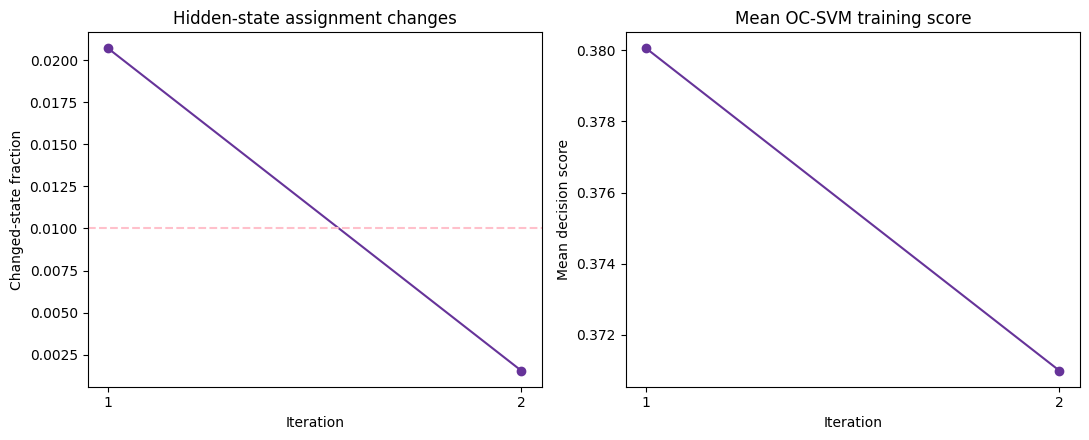

In [22]:
print('SIMULATION QUESTION 10 - CONTROLLED SYNTHETIC HMM EXPERIMENT')

from sklearn.cluster import KMeans

K_sim10 = 2
T_sim10 = 100
n_train_sim10 = 200
M_sim10 = 10
nu_sim10 = 0.10

true_pi_sim10 = np.array([0.70, 0.30], dtype=float)
true_A_sim10 = np.array([
    [0.95, 0.05],
    [0.10, 0.90],
], dtype=float)
true_means_sim10 = np.array([0.0, 4.0], dtype=float)
true_variances_sim10 = np.array([1.0, 1.0], dtype=float)

training_sequences_sim10 = []
true_states_sim10 = []
for sequence_index in range(n_train_sim10):
    z_sequence, x_sequence = generate_two_state_gaussian_hmm(
        pi=true_pi_sim10,
        A=true_A_sim10,
        emission_means=true_means_sim10,
        emission_variances=true_variances_sim10,
        T=T_sim10,
        random_state=1405 + sequence_index,
    )
    true_states_sim10.append(z_sequence)
    training_sequences_sim10.append(x_sequence)

training_sequences_sim10 = np.asarray(training_sequences_sim10, dtype=float)
true_states_sim10 = np.asarray(true_states_sim10, dtype=int)

pooled_observations_sim10 = training_sequences_sim10.reshape(-1, 1)
kmeans_sim10 = KMeans(
    n_clusters=K_sim10,
    n_init=20,
    random_state=1405,
)
kmeans_sim10.fit(pooled_observations_sim10)

cluster_order_sim10 = np.argsort(kmeans_sim10.cluster_centers_.ravel())
initial_means_sim10 = kmeans_sim10.cluster_centers_.ravel()[cluster_order_sim10]

ordered_labels_sim10 = np.empty_like(kmeans_sim10.labels_)
for new_label, old_label in enumerate(cluster_order_sim10):
    ordered_labels_sim10[kmeans_sim10.labels_ == old_label] = new_label

initial_states_sim10 = ordered_labels_sim10.reshape(
    n_train_sim10,
    T_sim10,
) + 1

initial_variances_sim10 = np.array([
    pooled_observations_sim10.ravel()[ordered_labels_sim10 == state].var(ddof=0)
    for state in range(K_sim10)
], dtype=float)

pi_sim10 = np.full(K_sim10, 1.0 / K_sim10, dtype=float)
A_sim10 = np.full(
    (K_sim10, K_sim10),
    (1.0 - 0.9) / (K_sim10 - 1),
    dtype=float,
)
np.fill_diagonal(A_sim10, 0.9)
means_sim10 = initial_means_sim10.copy()
variances_sim10 = np.maximum(initial_variances_sim10.copy(), 1e-6)

previous_states_sim10 = initial_states_sim10.copy()
iteration_rows_sim10 = []

for iteration_sim10 in range(1, M_sim10 + 1):
    decoded_states_sim10 = np.vstack([
        viterbi_log_gaussian_two_state(
            x=sequence,
            pi=pi_sim10,
            A=A_sim10,
            emission_means=means_sim10,
            emission_variances=variances_sim10,
        )[0]
        for sequence in training_sequences_sim10
    ])

    changed_fraction_sim10 = float(
        np.mean(decoded_states_sim10 != previous_states_sim10)
    )

    joint_features_sim10 = np.vstack([
        compute_joint_features(sequence, states, K_sim10)
        for sequence, states in zip(
            training_sequences_sim10,
            decoded_states_sim10,
        )
    ])

    hmad_scaler_sim10 = StandardScaler()
    joint_features_scaled_sim10 = hmad_scaler_sim10.fit_transform(
        joint_features_sim10
    )

    hmad_ocsvm_sim10 = OneClassSVM(
        kernel='rbf',
        gamma='scale',
        nu=nu_sim10,
    )
    hmad_ocsvm_sim10.fit(joint_features_scaled_sim10)
    mean_training_score_sim10 = float(
        hmad_ocsvm_sim10.decision_function(
            joint_features_scaled_sim10
        ).mean()
    )

    smoothing_sim10 = 1e-3

    initial_counts_sim10 = np.bincount(
        decoded_states_sim10[:, 0] - 1,
        minlength=K_sim10,
    ).astype(float) + smoothing_sim10
    pi_sim10 = initial_counts_sim10 / initial_counts_sim10.sum()

    transition_counts_sim10 = np.full(
        (K_sim10, K_sim10),
        smoothing_sim10,
        dtype=float,
    )
    for states in decoded_states_sim10:
        np.add.at(
            transition_counts_sim10,
            (states[:-1] - 1, states[1:] - 1),
            1.0,
        )
    A_sim10 = transition_counts_sim10 / transition_counts_sim10.sum(
        axis=1,
        keepdims=True,
    )

    for state_index_sim10 in range(K_sim10):
        assigned_values_sim10 = training_sequences_sim10[
            decoded_states_sim10 == state_index_sim10 + 1
        ]
        means_sim10[state_index_sim10] = assigned_values_sim10.mean()
        variances_sim10[state_index_sim10] = max(
            assigned_values_sim10.var(ddof=0),
            1e-6,
        )

    iteration_rows_sim10.append({
        'Iteration': iteration_sim10,
        'Changed-state fraction': changed_fraction_sim10,
        'Mean OC-SVM decision score': mean_training_score_sim10,
        'mu_1': means_sim10[0],
        'mu_2': means_sim10[1],
        'variance_1': variances_sim10[0],
        'variance_2': variances_sim10[1],
        'A_11': A_sim10[0, 0],
        'A_12': A_sim10[0, 1],
        'A_21': A_sim10[1, 0],
        'A_22': A_sim10[1, 1],
    })

    previous_states_sim10 = decoded_states_sim10.copy()

    if changed_fraction_sim10 < 0.01:
        break

iteration_history_sim10 = pd.DataFrame(iteration_rows_sim10)
stabilization_iteration_sim10 = int(iteration_history_sim10.iloc[-1]['Iteration'])

learned_pi_sim10 = pi_sim10.copy()
learned_A_sim10 = A_sim10.copy()
learned_means_sim10 = means_sim10.copy()
learned_variances_sim10 = variances_sim10.copy()
final_states_sim10 = decoded_states_sim10.copy()
final_joint_features_sim10 = joint_features_sim10.copy()

state_recovery_fraction_sim10 = float(
    np.mean(final_states_sim10 == true_states_sim10)
)

parameter_comparison_sim10 = pd.DataFrame({
    'Parameter': [
        'pi_1', 'pi_2',
        'mu_1', 'mu_2',
        'variance_1', 'variance_2',
        'A_11', 'A_12', 'A_21', 'A_22',
    ],
    'True value': [
        true_pi_sim10[0], true_pi_sim10[1],
        true_means_sim10[0], true_means_sim10[1],
        true_variances_sim10[0], true_variances_sim10[1],
        true_A_sim10[0, 0], true_A_sim10[0, 1],
        true_A_sim10[1, 0], true_A_sim10[1, 1],
    ],
    'Learned value': [
        learned_pi_sim10[0], learned_pi_sim10[1],
        learned_means_sim10[0], learned_means_sim10[1],
        learned_variances_sim10[0], learned_variances_sim10[1],
        learned_A_sim10[0, 0], learned_A_sim10[0, 1],
        learned_A_sim10[1, 0], learned_A_sim10[1, 1],
    ],
})
parameter_comparison_sim10['Absolute error'] = np.abs(
    parameter_comparison_sim10['Learned value']
    - parameter_comparison_sim10['True value']
)

summary_sim10 = pd.DataFrame([{
    'Training sequences': n_train_sim10,
    'Sequence length': T_sim10,
    'Maximum iterations': M_sim10,
    'Executed iterations': len(iteration_history_sim10),
    'Stabilization iteration': stabilization_iteration_sim10,
    'Final changed-state fraction': float(
        iteration_history_sim10.iloc[-1]['Changed-state fraction']
    ),
    'Final mean OC-SVM score': float(
        iteration_history_sim10.iloc[-1]['Mean OC-SVM decision score']
    ),
    'State recovery fraction': state_recovery_fraction_sim10,
}])

assert training_sequences_sim10.shape == (200, 100)
assert final_states_sim10.shape == (200, 100)
assert final_joint_features_sim10.shape == (200, 6)
assert np.allclose(learned_A_sim10.sum(axis=1), 1.0)
assert np.isfinite(iteration_history_sim10.to_numpy(dtype=float)).all()
assert iteration_history_sim10.iloc[-1]['Changed-state fraction'] < 0.01

print('INITIAL EMISSION MEANS:', initial_means_sim10)
print('LEARNED EMISSION MEANS:', learned_means_sim10)
print('LEARNED EMISSION VARIANCES:', learned_variances_sim10)
print('LEARNED INITIAL DISTRIBUTION:')
print(learned_pi_sim10)
print('LEARNED TRANSITION MATRIX:')
print(learned_A_sim10)

display(summary_sim10.round(6))
display(iteration_history_sim10.round(6))
display(parameter_comparison_sim10.round(6))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(
    iteration_history_sim10['Iteration'],
    iteration_history_sim10['Changed-state fraction'],
    marker='o',
    color = 'rebeccapurple'
)
axes[0].axhline(0.01, linestyle='--', color = 'pink')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Changed-state fraction')
axes[0].set_title('Hidden-state assignment changes')
axes[0].set_xticks(iteration_history_sim10['Iteration'])

axes[1].plot(
    iteration_history_sim10['Iteration'],
    iteration_history_sim10['Mean OC-SVM decision score'],
    marker='o',
    color = 'rebeccapurple'
)
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Mean decision score')
axes[1].set_title('Mean OC-SVM training score')
axes[1].set_xticks(iteration_history_sim10['Iteration'])

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / '16_simulation_10_training_diagnostics.png',
    dpi=180,
)
plt.show()

iteration_history_sim10.to_csv(
    RESULTS_DIR / 'simulation_10_iteration_history.csv',
    index=False,
)
parameter_comparison_sim10.to_csv(
    RESULTS_DIR / 'simulation_10_parameter_comparison.csv',
    index=False,
)
summary_sim10.to_csv(
    RESULTS_DIR / 'simulation_10_summary.csv',
    index=False,
)
np.savez_compressed(
    RESULTS_DIR / 'simulation_10_trained_hmad.npz',
    training_sequences=training_sequences_sim10,
    true_states=true_states_sim10,
    final_states=final_states_sim10,
    joint_features=final_joint_features_sim10,
    learned_pi=learned_pi_sim10,
    learned_A=learned_A_sim10,
    learned_means=learned_means_sim10,
    learned_variances=learned_variances_sim10,
    true_pi=true_pi_sim10,
    true_A=true_A_sim10,
    true_means=true_means_sim10,
    true_variances=true_variances_sim10,
)


SIMULATION QUESTION 10 - ECG5000 MAIN DATASET
INITIAL ECG5000 EMISSION MEANS: [-2.83163194  0.17528064]
LEARNED ECG5000 EMISSION MEANS: [-2.45557574  0.19070296]
LEARNED ECG5000 EMISSION VARIANCES: [1.55631228 0.44444536]
LEARNED ECG5000 INITIAL DISTRIBUTION: [0.7910939 0.2089061]
LEARNED ECG5000 TRANSITION MATRIX:
[[0.89213302 0.10786698]
 [0.00313191 0.99686809]]


,Dataset,Training sequences,Sequence length,K,nu,Maximum iterations,Executed iterations,Final changed-state fraction,Final mean OC-SVM score,mu_1,...,variance_1,variance_2,pi_1,pi_2,A_11,A_12,A_21,A_22,State-1 occupancy,State-2 occupancy
0,ECG5000,292,140,2,0.1,10,2,0.006849,0.3501,-2.455576,...,1.556312,0.444445,0.791094,0.208906,0.892133,0.107867,0.003132,0.996868,0.072065,0.927935


,Iteration,Changed-state fraction,Mean OC-SVM decision score,mu_1,mu_2,variance_1,variance_2,pi_1,pi_2,A_11,A_12,A_21,A_22,State-1 occupancy,State-2 occupancy
0,1,0.010616,0.657256,-2.609894,0.187496,1.309957,0.445576,0.448630,0.551370,0.882923,0.117077,0.006358,0.993642,0.067025,0.932975
1,2,0.006849,0.350100,-2.455576,0.190703,1.556312,0.444445,0.791094,0.208906,0.892133,0.107867,0.003132,0.996868,0.072065,0.927935


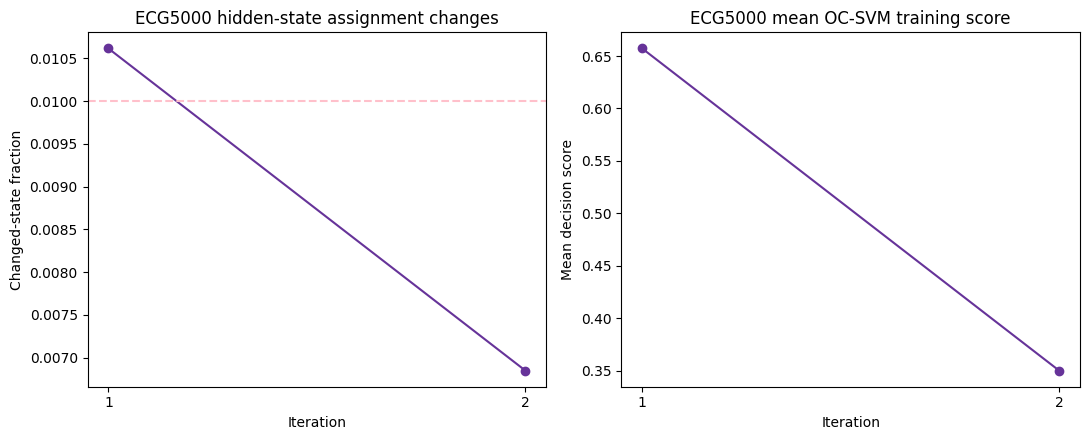

In [23]:
print('SIMULATION QUESTION 10 - ECG5000 MAIN DATASET')

from sklearn.cluster import KMeans

K_sim10_ecg = 2
M_sim10_ecg = 10
nu_sim10_ecg = 0.10
tol_sim10_ecg = 0.01
smoothing_sim10_ecg = 1e-3
variance_floor_sim10_ecg = 1e-6

training_sequences_sim10_ecg = np.asarray(X_train, dtype=float)
n_train_sim10_ecg, T_sim10_ecg = training_sequences_sim10_ecg.shape

pooled_observations_sim10_ecg = training_sequences_sim10_ecg.reshape(-1, 1)

kmeans_sim10_ecg = KMeans(
    n_clusters=K_sim10_ecg,
    n_init=20,
    random_state=1405,
)
kmeans_sim10_ecg.fit(pooled_observations_sim10_ecg)

cluster_order_sim10_ecg = np.argsort(
    kmeans_sim10_ecg.cluster_centers_.ravel()
)

initial_means_sim10_ecg = (
    kmeans_sim10_ecg.cluster_centers_.ravel()[cluster_order_sim10_ecg]
)

ordered_labels_sim10_ecg = np.empty_like(kmeans_sim10_ecg.labels_)
for new_label, old_label in enumerate(cluster_order_sim10_ecg):
    ordered_labels_sim10_ecg[
        kmeans_sim10_ecg.labels_ == old_label
    ] = new_label

initial_states_sim10_ecg = ordered_labels_sim10_ecg.reshape(
    n_train_sim10_ecg,
    T_sim10_ecg,
) + 1

initial_variances_sim10_ecg = np.array([
    pooled_observations_sim10_ecg.ravel()[
        ordered_labels_sim10_ecg == state
    ].var(ddof=0)
    for state in range(K_sim10_ecg)
], dtype=float)

pi_sim10_ecg = np.full(
    K_sim10_ecg,
    1.0 / K_sim10_ecg,
    dtype=float,
)

A_sim10_ecg = np.full(
    (K_sim10_ecg, K_sim10_ecg),
    (1.0 - 0.9) / (K_sim10_ecg - 1),
    dtype=float,
)
np.fill_diagonal(A_sim10_ecg, 0.9)

means_sim10_ecg = initial_means_sim10_ecg.copy()
variances_sim10_ecg = np.maximum(
    initial_variances_sim10_ecg.copy(),
    variance_floor_sim10_ecg,
)

previous_states_sim10_ecg = initial_states_sim10_ecg.copy()
iteration_rows_sim10_ecg = []

for iteration_sim10_ecg in range(1, M_sim10_ecg + 1):
    decoded_states_sim10_ecg = np.vstack([
        viterbi_log_gaussian_two_state(
            x=sequence,
            pi=pi_sim10_ecg,
            A=A_sim10_ecg,
            emission_means=means_sim10_ecg,
            emission_variances=variances_sim10_ecg,
        )[0]
        for sequence in training_sequences_sim10_ecg
    ])

    changed_fraction_sim10_ecg = float(
        np.mean(
            decoded_states_sim10_ecg
            != previous_states_sim10_ecg
        )
    )

    joint_features_sim10_ecg = np.vstack([
        compute_joint_features(
            sequence,
            states,
            K_sim10_ecg,
        )
        for sequence, states in zip(
            training_sequences_sim10_ecg,
            decoded_states_sim10_ecg,
        )
    ])

    hmad_scaler_sim10_ecg = StandardScaler()
    joint_features_scaled_sim10_ecg = (
        hmad_scaler_sim10_ecg.fit_transform(
            joint_features_sim10_ecg
        )
    )

    hmad_ocsvm_sim10_ecg = OneClassSVM(
        kernel='rbf',
        gamma='scale',
        nu=nu_sim10_ecg,
    )
    hmad_ocsvm_sim10_ecg.fit(
        joint_features_scaled_sim10_ecg
    )

    mean_training_score_sim10_ecg = float(
        hmad_ocsvm_sim10_ecg.decision_function(
            joint_features_scaled_sim10_ecg
        ).mean()
    )

    initial_counts_sim10_ecg = np.bincount(
        decoded_states_sim10_ecg[:, 0] - 1,
        minlength=K_sim10_ecg,
    ).astype(float) + smoothing_sim10_ecg

    pi_sim10_ecg = (
        initial_counts_sim10_ecg
        / initial_counts_sim10_ecg.sum()
    )

    transition_counts_sim10_ecg = np.full(
        (K_sim10_ecg, K_sim10_ecg),
        smoothing_sim10_ecg,
        dtype=float,
    )

    for states in decoded_states_sim10_ecg:
        np.add.at(
            transition_counts_sim10_ecg,
            (states[:-1] - 1, states[1:] - 1),
            1.0,
        )

    A_sim10_ecg = (
        transition_counts_sim10_ecg
        / transition_counts_sim10_ecg.sum(
            axis=1,
            keepdims=True,
        )
    )

    for state_index_sim10_ecg in range(K_sim10_ecg):
        assigned_values_sim10_ecg = training_sequences_sim10_ecg[
            decoded_states_sim10_ecg
            == state_index_sim10_ecg + 1
        ]

        means_sim10_ecg[state_index_sim10_ecg] = (
            assigned_values_sim10_ecg.mean()
        )

        variances_sim10_ecg[state_index_sim10_ecg] = max(
            assigned_values_sim10_ecg.var(ddof=0),
            variance_floor_sim10_ecg,
        )

    state_1_fraction_sim10_ecg = float(
        np.mean(decoded_states_sim10_ecg == 1)
    )
    state_2_fraction_sim10_ecg = float(
        np.mean(decoded_states_sim10_ecg == 2)
    )

    iteration_rows_sim10_ecg.append({
        'Iteration': iteration_sim10_ecg,
        'Changed-state fraction': changed_fraction_sim10_ecg,
        'Mean OC-SVM decision score': mean_training_score_sim10_ecg,
        'mu_1': means_sim10_ecg[0],
        'mu_2': means_sim10_ecg[1],
        'variance_1': variances_sim10_ecg[0],
        'variance_2': variances_sim10_ecg[1],
        'pi_1': pi_sim10_ecg[0],
        'pi_2': pi_sim10_ecg[1],
        'A_11': A_sim10_ecg[0, 0],
        'A_12': A_sim10_ecg[0, 1],
        'A_21': A_sim10_ecg[1, 0],
        'A_22': A_sim10_ecg[1, 1],
        'State-1 occupancy': state_1_fraction_sim10_ecg,
        'State-2 occupancy': state_2_fraction_sim10_ecg,
    })

    previous_states_sim10_ecg = (
        decoded_states_sim10_ecg.copy()
    )

    if changed_fraction_sim10_ecg < tol_sim10_ecg:
        break

iteration_history_sim10_ecg = pd.DataFrame(
    iteration_rows_sim10_ecg
)

learned_pi_sim10_ecg = pi_sim10_ecg.copy()
learned_A_sim10_ecg = A_sim10_ecg.copy()
learned_means_sim10_ecg = means_sim10_ecg.copy()
learned_variances_sim10_ecg = variances_sim10_ecg.copy()
final_states_sim10_ecg = decoded_states_sim10_ecg.copy()
final_joint_features_sim10_ecg = (
    joint_features_sim10_ecg.copy()
)

summary_sim10_ecg = pd.DataFrame([{
    'Dataset': 'ECG5000',
    'Training sequences': n_train_sim10_ecg,
    'Sequence length': T_sim10_ecg,
    'K': K_sim10_ecg,
    'nu': nu_sim10_ecg,
    'Maximum iterations': M_sim10_ecg,
    'Executed iterations': len(
        iteration_history_sim10_ecg
    ),
    'Final changed-state fraction': float(
        iteration_history_sim10_ecg.iloc[-1][
            'Changed-state fraction'
        ]
    ),
    'Final mean OC-SVM score': float(
        iteration_history_sim10_ecg.iloc[-1][
            'Mean OC-SVM decision score'
        ]
    ),
    'mu_1': learned_means_sim10_ecg[0],
    'mu_2': learned_means_sim10_ecg[1],
    'variance_1': learned_variances_sim10_ecg[0],
    'variance_2': learned_variances_sim10_ecg[1],
    'pi_1': learned_pi_sim10_ecg[0],
    'pi_2': learned_pi_sim10_ecg[1],
    'A_11': learned_A_sim10_ecg[0, 0],
    'A_12': learned_A_sim10_ecg[0, 1],
    'A_21': learned_A_sim10_ecg[1, 0],
    'A_22': learned_A_sim10_ecg[1, 1],
    'State-1 occupancy': float(
        np.mean(final_states_sim10_ecg == 1)
    ),
    'State-2 occupancy': float(
        np.mean(final_states_sim10_ecg == 2)
    ),
}])

assert training_sequences_sim10_ecg.shape == (292, 140)
assert final_states_sim10_ecg.shape == (292, 140)
assert final_joint_features_sim10_ecg.shape == (292, 6)
assert np.allclose(
    learned_A_sim10_ecg.sum(axis=1),
    1.0,
)
assert (
    iteration_history_sim10_ecg.iloc[-1][
        'Changed-state fraction'
    ] < tol_sim10_ecg
)

print('INITIAL ECG5000 EMISSION MEANS:', initial_means_sim10_ecg)
print('LEARNED ECG5000 EMISSION MEANS:', learned_means_sim10_ecg)
print('LEARNED ECG5000 EMISSION VARIANCES:', learned_variances_sim10_ecg)
print('LEARNED ECG5000 INITIAL DISTRIBUTION:', learned_pi_sim10_ecg)
print('LEARNED ECG5000 TRANSITION MATRIX:')
print(learned_A_sim10_ecg)

display(summary_sim10_ecg.round(6))
display(iteration_history_sim10_ecg.round(6))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(
    iteration_history_sim10_ecg['Iteration'],
    iteration_history_sim10_ecg[
        'Changed-state fraction'
    ],
    marker='o',
    color = 'rebeccapurple'
)
axes[0].axhline(
    tol_sim10_ecg,
    linestyle='--',
    color='pink'
)
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Changed-state fraction')
axes[0].set_title(
    'ECG5000 hidden-state assignment changes'
)
axes[0].set_xticks(
    iteration_history_sim10_ecg['Iteration']
)

axes[1].plot(
    iteration_history_sim10_ecg['Iteration'],
    iteration_history_sim10_ecg[
        'Mean OC-SVM decision score'
    ],
    marker='o',
    color = 'rebeccapurple'
)
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Mean decision score')
axes[1].set_title(
    'ECG5000 mean OC-SVM training score'
)
axes[1].set_xticks(
    iteration_history_sim10_ecg['Iteration']
)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR
    / '18_simulation_10_ecg5000_training_diagnostics.png',
    dpi=180,
)
plt.show()

iteration_history_sim10_ecg.to_csv(
    RESULTS_DIR
    / 'simulation_10_ecg5000_iteration_history.csv',
    index=False,
)

summary_sim10_ecg.to_csv(
    RESULTS_DIR
    / 'simulation_10_ecg5000_summary.csv',
    index=False,
)

np.savez_compressed(
    RESULTS_DIR
    / 'simulation_10_ecg5000_trained_hmad.npz',
    final_states=final_states_sim10_ecg,
    joint_features=final_joint_features_sim10_ecg,
    learned_pi=learned_pi_sim10_ecg,
    learned_A=learned_A_sim10_ecg,
    learned_means=learned_means_sim10_ecg,
    learned_variances=learned_variances_sim10_ecg,
)


SIMULATION QUESTION 11 - CONTROLLED SYNTHETIC HMM EXPERIMENT
HMAD VITERBI ROC-AUC: 0.9646
TRIVIAL-STATE ROC-AUC: 0.5471
SAME-DATA FLATTENED OC-SVM ROC-AUC: 0.6286
SECTION 3 ECG5000 ROC-AUC REFERENCE: 0.984025


,Normal test sequences,Anomalous test sequences,Sequence length,Anomaly block length,HMAD Viterbi ROC-AUC,Trivial-state ROC-AUC,AUC decrease without Viterbi,Same-data flattened OC-SVM ROC-AUC,Section 3 ECG5000 ROC-AUC reference,Normal transition rate,True anomaly-block transition rate,Decoded anomaly-block transition rate
0,100,50,100,20,0.9646,0.5471,0.4175,0.6286,0.984025,0.07202,0.684211,0.534737


,Method,ROC-AUC,Precision,Recall,F1,TN,FP,FN,TP
0,HMAD with Viterbi,0.9646,0.707692,0.92,0.800000,81,19,4,46
1,HMAD with all-one states,0.5471,0.333333,1.00,0.500000,0,100,0,50
2,"Flattened OC-SVM, same synthetic data",0.6286,0.467742,0.58,0.517857,67,33,21,29


,Sequence type,Test index,True label,Prediction,Anomaly score,State recovery fraction,Anomaly block start,Anomaly block stop
0,Correctly classified normal,2,0,0,-0.142752,1.00,NaN,NaN
1,Correctly classified anomalous,100,1,1,1.115601,0.98,59.0,78.0


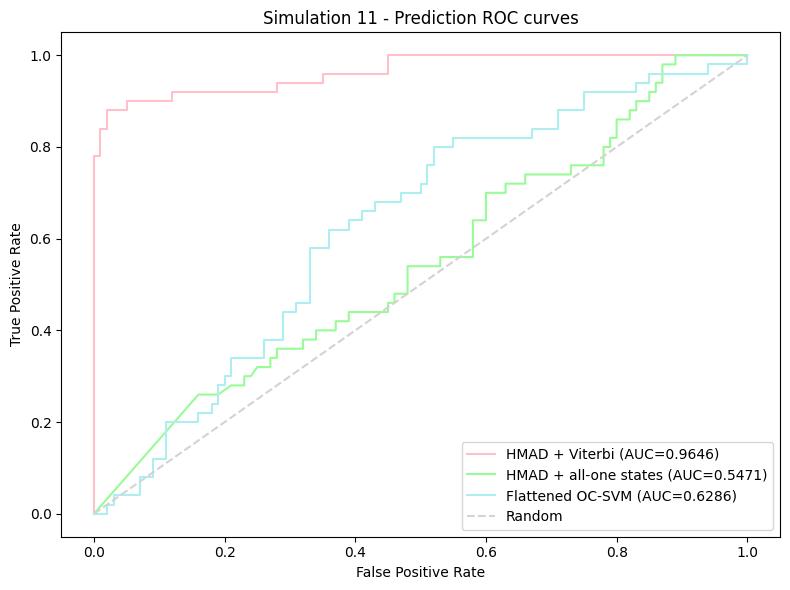

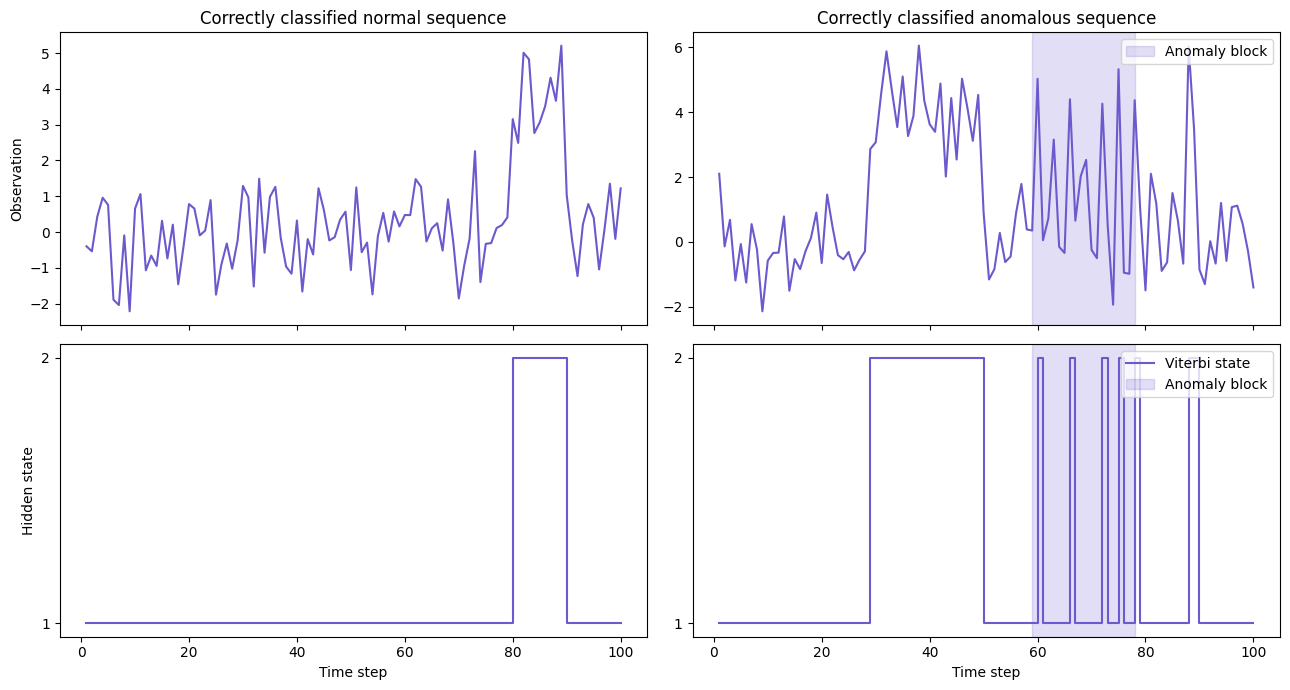

In [24]:
print('SIMULATION QUESTION 11 - CONTROLLED SYNTHETIC HMM EXPERIMENT')

n_normal_test_sim11 = 100
n_anomalous_test_sim11 = 50
T_sim11 = T_sim10
anomaly_block_length_sim11 = 20

normal_test_sequences_sim11 = []
normal_true_states_sim11 = []
for sequence_index_sim11 in range(n_normal_test_sim11):
    states_sim11, sequence_sim11 = generate_two_state_gaussian_hmm(
        pi=true_pi_sim10,
        A=true_A_sim10,
        emission_means=true_means_sim10,
        emission_variances=true_variances_sim10,
        T=T_sim11,
        random_state=5000 + sequence_index_sim11,
    )
    normal_true_states_sim11.append(states_sim11)
    normal_test_sequences_sim11.append(sequence_sim11)

normal_test_sequences_sim11 = np.asarray(normal_test_sequences_sim11, dtype=float)
normal_true_states_sim11 = np.asarray(normal_true_states_sim11, dtype=int)

anomalous_test_sequences_sim11 = []
anomalous_true_states_sim11 = []
anomaly_starts_sim11 = []
anomaly_pattern_sim11 = np.array(
    [1, 2, 1, 1, 2, 1] * 3 + [1, 2],
    dtype=int,
)
assert anomaly_pattern_sim11.size == anomaly_block_length_sim11
assert np.sum(anomaly_pattern_sim11 == 1) == 13
assert np.sum(anomaly_pattern_sim11 == 2) == 7

for sequence_index_sim11 in range(n_anomalous_test_sim11):
    states_sim11, sequence_sim11 = generate_two_state_gaussian_hmm(
        pi=true_pi_sim10,
        A=true_A_sim10,
        emission_means=true_means_sim10,
        emission_variances=true_variances_sim10,
        T=T_sim11,
        random_state=6000 + sequence_index_sim11,
    )
    rng_sequence_sim11 = np.random.default_rng(7000 + sequence_index_sim11)
    start_sim11 = int(rng_sequence_sim11.integers(
        5,
        T_sim11 - anomaly_block_length_sim11 - 4,
    ))
    stop_sim11 = start_sim11 + anomaly_block_length_sim11
    states_sim11[start_sim11:stop_sim11] = anomaly_pattern_sim11
    sequence_sim11[start_sim11:stop_sim11] = rng_sequence_sim11.normal(
        loc=true_means_sim10[anomaly_pattern_sim11 - 1],
        scale=np.sqrt(true_variances_sim10[anomaly_pattern_sim11 - 1]),
    )
    anomalous_true_states_sim11.append(states_sim11)
    anomalous_test_sequences_sim11.append(sequence_sim11)
    anomaly_starts_sim11.append(start_sim11)

anomalous_test_sequences_sim11 = np.asarray(anomalous_test_sequences_sim11, dtype=float)
anomalous_true_states_sim11 = np.asarray(anomalous_true_states_sim11, dtype=int)
anomaly_starts_sim11 = np.asarray(anomaly_starts_sim11, dtype=int)

X_test_sim11 = np.vstack([
    normal_test_sequences_sim11,
    anomalous_test_sequences_sim11,
])
y_test_sim11 = np.concatenate([
    np.zeros(n_normal_test_sim11, dtype=int),
    np.ones(n_anomalous_test_sim11, dtype=int),
])
true_states_test_sim11 = np.vstack([
    normal_true_states_sim11,
    anomalous_true_states_sim11,
])

viterbi_states_sim11 = np.vstack([
    viterbi_log_gaussian_two_state(
        x=sequence_sim11,
        pi=learned_pi_sim10,
        A=learned_A_sim10,
        emission_means=learned_means_sim10,
        emission_variances=learned_variances_sim10,
    )[0]
    for sequence_sim11 in X_test_sim11
])

joint_features_viterbi_sim11 = np.vstack([
    compute_joint_features(sequence_sim11, states_sim11, K_sim10)
    for sequence_sim11, states_sim11 in zip(
        X_test_sim11,
        viterbi_states_sim11,
    )
])
joint_features_viterbi_scaled_sim11 = hmad_scaler_sim10.transform(
    joint_features_viterbi_sim11
)
hmad_normality_scores_sim11 = hmad_ocsvm_sim10.decision_function(
    joint_features_viterbi_scaled_sim11
).ravel()
hmad_anomaly_scores_sim11 = -hmad_normality_scores_sim11
hmad_predictions_sim11 = (hmad_normality_scores_sim11 < 0).astype(int)
hmad_auc_sim11 = float(roc_auc_score(y_test_sim11, hmad_anomaly_scores_sim11))
hmad_fpr_sim11, hmad_tpr_sim11, _ = roc_curve(
    y_test_sim11,
    hmad_anomaly_scores_sim11,
)

trivial_states_sim11 = np.ones_like(viterbi_states_sim11, dtype=int)
joint_features_trivial_sim11 = np.vstack([
    compute_joint_features(sequence_sim11, states_sim11, K_sim10)
    for sequence_sim11, states_sim11 in zip(
        X_test_sim11,
        trivial_states_sim11,
    )
])
joint_features_trivial_scaled_sim11 = hmad_scaler_sim10.transform(
    joint_features_trivial_sim11
)
trivial_normality_scores_sim11 = hmad_ocsvm_sim10.decision_function(
    joint_features_trivial_scaled_sim11
).ravel()
trivial_anomaly_scores_sim11 = -trivial_normality_scores_sim11
trivial_predictions_sim11 = (trivial_normality_scores_sim11 < 0).astype(int)
trivial_auc_sim11 = float(roc_auc_score(y_test_sim11, trivial_anomaly_scores_sim11))
trivial_fpr_sim11, trivial_tpr_sim11, _ = roc_curve(
    y_test_sim11,
    trivial_anomaly_scores_sim11,
)

synthetic_baseline_sim11 = fit_and_evaluate(
    flattened_features(training_sequences_sim10),
    flattened_features(X_test_sim11),
    y_test_sim11,
    nu_sim10,
)
synthetic_baseline_auc_sim11 = float(
    synthetic_baseline_sim11['metrics']['ROC-AUC']
)

section3_ecg5000_auc_sim11 = float(sim1['metrics']['ROC-AUC'])

hmad_tn_sim11, hmad_fp_sim11, hmad_fn_sim11, hmad_tp_sim11 = confusion_matrix(
    y_test_sim11,
    hmad_predictions_sim11,
    labels=[0, 1],
).ravel()
trivial_tn_sim11, trivial_fp_sim11, trivial_fn_sim11, trivial_tp_sim11 = confusion_matrix(
    y_test_sim11,
    trivial_predictions_sim11,
    labels=[0, 1],
).ravel()

metrics_sim11 = pd.DataFrame([
    {
        'Method': 'HMAD with Viterbi',
        'ROC-AUC': hmad_auc_sim11,
        'Precision': precision_score(y_test_sim11, hmad_predictions_sim11, zero_division=0),
        'Recall': recall_score(y_test_sim11, hmad_predictions_sim11, zero_division=0),
        'F1': f1_score(y_test_sim11, hmad_predictions_sim11, zero_division=0),
        'TN': int(hmad_tn_sim11),
        'FP': int(hmad_fp_sim11),
        'FN': int(hmad_fn_sim11),
        'TP': int(hmad_tp_sim11),
    },
    {
        'Method': 'HMAD with all-one states',
        'ROC-AUC': trivial_auc_sim11,
        'Precision': precision_score(y_test_sim11, trivial_predictions_sim11, zero_division=0),
        'Recall': recall_score(y_test_sim11, trivial_predictions_sim11, zero_division=0),
        'F1': f1_score(y_test_sim11, trivial_predictions_sim11, zero_division=0),
        'TN': int(trivial_tn_sim11),
        'FP': int(trivial_fp_sim11),
        'FN': int(trivial_fn_sim11),
        'TP': int(trivial_tp_sim11),
    },
    {
        'Method': 'Flattened OC-SVM, same synthetic data',
        'ROC-AUC': synthetic_baseline_auc_sim11,
        'Precision': synthetic_baseline_sim11['metrics']['Precision'],
        'Recall': synthetic_baseline_sim11['metrics']['Recall'],
        'F1': synthetic_baseline_sim11['metrics']['F1'],
        'TN': synthetic_baseline_sim11['metrics']['TN'],
        'FP': synthetic_baseline_sim11['metrics']['FP'],
        'FN': synthetic_baseline_sim11['metrics']['FN'],
        'TP': synthetic_baseline_sim11['metrics']['TP'],
    },
])

normal_correct_candidates_sim11 = np.flatnonzero(
    (y_test_sim11 == 0) & (hmad_predictions_sim11 == 0)
)
anomaly_correct_candidates_sim11 = np.flatnonzero(
    (y_test_sim11 == 1) & (hmad_predictions_sim11 == 1)
)
if normal_correct_candidates_sim11.size == 0:
    normal_plot_index_sim11 = int(np.argmin(hmad_anomaly_scores_sim11[:n_normal_test_sim11]))
else:
    normal_plot_index_sim11 = int(normal_correct_candidates_sim11[0])
if anomaly_correct_candidates_sim11.size == 0:
    anomaly_plot_index_sim11 = int(
        n_normal_test_sim11
        + np.argmax(hmad_anomaly_scores_sim11[n_normal_test_sim11:])
    )
else:
    anomaly_plot_index_sim11 = int(anomaly_correct_candidates_sim11[0])

anomaly_local_index_sim11 = anomaly_plot_index_sim11 - n_normal_test_sim11
anomaly_start_plot_sim11 = int(anomaly_starts_sim11[anomaly_local_index_sim11])
anomaly_stop_plot_sim11 = anomaly_start_plot_sim11 + anomaly_block_length_sim11

selected_path_summary_sim11 = pd.DataFrame([
    {
        'Sequence type': 'Correctly classified normal',
        'Test index': normal_plot_index_sim11,
        'True label': int(y_test_sim11[normal_plot_index_sim11]),
        'Prediction': int(hmad_predictions_sim11[normal_plot_index_sim11]),
        'Anomaly score': float(hmad_anomaly_scores_sim11[normal_plot_index_sim11]),
        'State recovery fraction': float(np.mean(
            viterbi_states_sim11[normal_plot_index_sim11]
            == true_states_test_sim11[normal_plot_index_sim11]
        )),
        'Anomaly block start': np.nan,
        'Anomaly block stop': np.nan,
    },
    {
        'Sequence type': 'Correctly classified anomalous',
        'Test index': anomaly_plot_index_sim11,
        'True label': int(y_test_sim11[anomaly_plot_index_sim11]),
        'Prediction': int(hmad_predictions_sim11[anomaly_plot_index_sim11]),
        'Anomaly score': float(hmad_anomaly_scores_sim11[anomaly_plot_index_sim11]),
        'State recovery fraction': float(np.mean(
            viterbi_states_sim11[anomaly_plot_index_sim11]
            == true_states_test_sim11[anomaly_plot_index_sim11]
        )),
        'Anomaly block start': anomaly_start_plot_sim11 + 1,
        'Anomaly block stop': anomaly_stop_plot_sim11,
    },
])

block_true_switch_rate_sim11 = float(np.mean([
    np.mean(states[start:start + anomaly_block_length_sim11 - 1]
            != states[start + 1:start + anomaly_block_length_sim11])
    for states, start in zip(anomalous_true_states_sim11, anomaly_starts_sim11)
]))
block_decoded_switch_rate_sim11 = float(np.mean([
    np.mean(states[start:start + anomaly_block_length_sim11 - 1]
            != states[start + 1:start + anomaly_block_length_sim11])
    for states, start in zip(
        viterbi_states_sim11[n_normal_test_sim11:],
        anomaly_starts_sim11,
    )
]))
normal_switch_rate_sim11 = float(np.mean(
    normal_true_states_sim11[:, 1:] != normal_true_states_sim11[:, :-1]
))

summary_sim11 = pd.DataFrame([{
    'Normal test sequences': n_normal_test_sim11,
    'Anomalous test sequences': n_anomalous_test_sim11,
    'Sequence length': T_sim11,
    'Anomaly block length': anomaly_block_length_sim11,
    'HMAD Viterbi ROC-AUC': hmad_auc_sim11,
    'Trivial-state ROC-AUC': trivial_auc_sim11,
    'AUC decrease without Viterbi': hmad_auc_sim11 - trivial_auc_sim11,
    'Same-data flattened OC-SVM ROC-AUC': synthetic_baseline_auc_sim11,
    'Section 3 ECG5000 ROC-AUC reference': section3_ecg5000_auc_sim11,
    'Normal transition rate': normal_switch_rate_sim11,
    'True anomaly-block transition rate': block_true_switch_rate_sim11,
    'Decoded anomaly-block transition rate': block_decoded_switch_rate_sim11,
}])

assert X_test_sim11.shape == (150, 100)
assert viterbi_states_sim11.shape == X_test_sim11.shape
assert joint_features_viterbi_sim11.shape == (150, 6)
assert np.isfinite(hmad_anomaly_scores_sim11).all()
assert np.isfinite(trivial_anomaly_scores_sim11).all()
assert 0.0 <= hmad_auc_sim11 <= 1.0
assert 0.0 <= trivial_auc_sim11 <= 1.0

print('HMAD VITERBI ROC-AUC:', round(hmad_auc_sim11, 6))
print('TRIVIAL-STATE ROC-AUC:', round(trivial_auc_sim11, 6))
print('SAME-DATA FLATTENED OC-SVM ROC-AUC:', round(synthetic_baseline_auc_sim11, 6))
print('SECTION 3 ECG5000 ROC-AUC REFERENCE:', round(section3_ecg5000_auc_sim11, 6))
display(summary_sim11.round(6))
display(metrics_sim11.round(6))
display(selected_path_summary_sim11.round(6))

plt.figure(figsize=(8, 6))
plt.plot(hmad_fpr_sim11, hmad_tpr_sim11, label=f'HMAD + Viterbi (AUC={hmad_auc_sim11:.4f})', color = 'pink')
plt.plot(trivial_fpr_sim11, trivial_tpr_sim11, label=f'HMAD + all-one states (AUC={trivial_auc_sim11:.4f})', color = 'palegreen')
plt.plot(
    synthetic_baseline_sim11['fpr'],
    synthetic_baseline_sim11['tpr'],
    label=f'Flattened OC-SVM (AUC={synthetic_baseline_auc_sim11:.4f})',
    color = 'paleturquoise'
)
plt.plot([0, 1], [0, 1], linestyle='--', label='Random', color = 'lightgray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Simulation 11 - Prediction ROC curves')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(RESULTS_DIR / '17_simulation_11_roc_comparison.png', dpi=180)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex='col')
time_steps_sim11 = np.arange(1, T_sim11 + 1)

axes[0, 0].plot(time_steps_sim11, X_test_sim11[normal_plot_index_sim11], color = 'slateblue')
axes[0, 0].set_title('Correctly classified normal sequence')
axes[0, 0].set_ylabel('Observation')
axes[1, 0].step(
    time_steps_sim11,
    viterbi_states_sim11[normal_plot_index_sim11],
    where='post',
    label='Viterbi state',
    color = 'slateblue'
)
axes[1, 0].set_xlabel('Time step')
axes[1, 0].set_ylabel('Hidden state')
axes[1, 0].set_yticks([1, 2])

axes[0, 1].plot(time_steps_sim11, X_test_sim11[anomaly_plot_index_sim11], color = 'slateblue')
axes[0, 1].axvspan(
    anomaly_start_plot_sim11 + 1,
    anomaly_stop_plot_sim11,
    alpha=0.2,
    label='Anomaly block',
    color = 'slateblue'
)
axes[0, 1].set_title('Correctly classified anomalous sequence')
axes[0, 1].legend(loc='upper right')
axes[1, 1].step(
    time_steps_sim11,
    viterbi_states_sim11[anomaly_plot_index_sim11],
    where='post',
    label='Viterbi state',
    color = 'slateblue'
)
axes[1, 1].axvspan(
    anomaly_start_plot_sim11 + 1,
    anomaly_stop_plot_sim11,
    alpha=0.2,
    label='Anomaly block',
    color = 'slateblue'
)
axes[1, 1].set_xlabel('Time step')
axes[1, 1].set_yticks([1, 2])
axes[1, 1].legend(loc='upper right')

plt.tight_layout()
plt.savefig(RESULTS_DIR / '18_simulation_11_viterbi_paths.png', dpi=180)
plt.show()

summary_sim11.to_csv(RESULTS_DIR / 'simulation_11_summary.csv', index=False)
metrics_sim11.to_csv(RESULTS_DIR / 'simulation_11_metrics.csv', index=False)
selected_path_summary_sim11.to_csv(
    RESULTS_DIR / 'simulation_11_selected_paths.csv',
    index=False,
)
pd.DataFrame({
    'Anomalous sequence': np.arange(1, n_anomalous_test_sim11 + 1),
    'Block start': anomaly_starts_sim11 + 1,
    'Block stop': anomaly_starts_sim11 + anomaly_block_length_sim11,
}).to_csv(RESULTS_DIR / 'simulation_11_anomaly_blocks.csv', index=False)
np.savez_compressed(
    RESULTS_DIR / 'simulation_11_predictions.npz',
    X_test=X_test_sim11,
    y_test=y_test_sim11,
    true_states=true_states_test_sim11,
    viterbi_states=viterbi_states_sim11,
    hmad_normality_scores=hmad_normality_scores_sim11,
    hmad_anomaly_scores=hmad_anomaly_scores_sim11,
    trivial_normality_scores=trivial_normality_scores_sim11,
    trivial_anomaly_scores=trivial_anomaly_scores_sim11,
    anomaly_starts=anomaly_starts_sim11,
)


SIMULATION QUESTION 11 - ECG5000 MAIN DATASET
ECG5000 HMAD VITERBI ROC-AUC: 0.95771
ECG5000 ALL-ONE ROC-AUC: 0.5
ECG5000 FLATTENED OC-SVM ROC-AUC: 0.984025
AUC DECREASE WITHOUT VITERBI: 0.45771


,Method,ROC-AUC,Precision,Recall,F1,TN,FP,FN,TP
0,HMAD with Viterbi - ECG5000,0.957710,0.841880,0.946610,0.891179,2294,333,100,1773
1,HMAD all-one states - ECG5000,0.500000,0.416222,1.000000,0.587792,0,2627,0,1873
2,Flattened OC-SVM baseline - ECG5000,0.984025,0.831406,0.997864,0.907061,2248,379,4,1869


,c11/(T-1),c12/(T-1),c21/(T-1),c22/(T-1),Mean emission: state 1,Mean emission: state 2
Label,,,,,,
0,0.066643,0.007561,0.001766,0.924029,-2.479407,0.192279
1,0.115142,0.008758,0.007590,0.868510,-2.202826,0.318226


,Type,Test index,True label,Prediction,Anomaly score
0,Correctly classified normal,1,0,0,-0.548202
1,Correctly classified anomaly,2627,1,1,2.972335


,Experiment,HMAD Viterbi ROC-AUC,All-one ROC-AUC,Comparable flattened ROC-AUC
0,Controlled synthetic HMM,0.96460,0.5471,0.628600
1,ECG5000 main dataset,0.95771,0.5000,0.984025


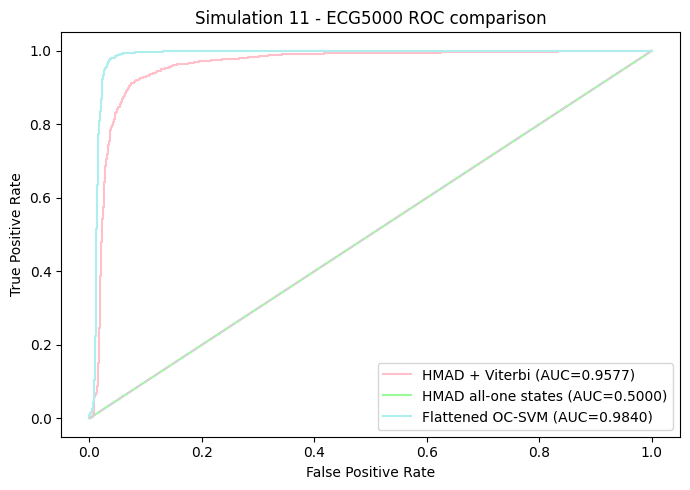

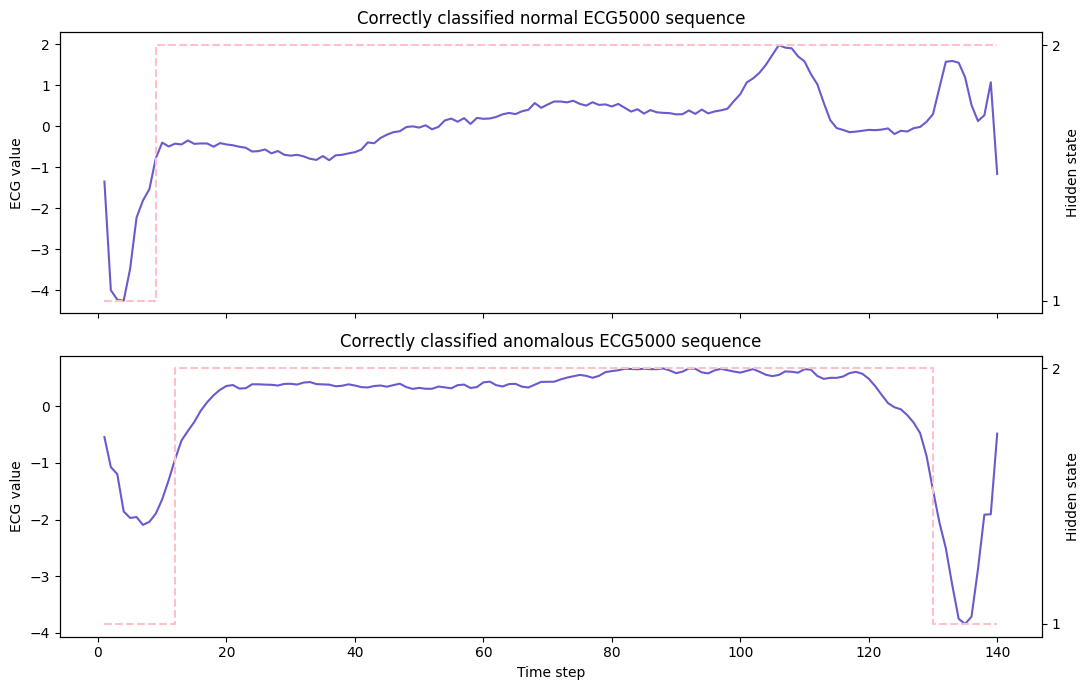

In [25]:
print('SIMULATION QUESTION 11 - ECG5000 MAIN DATASET')

X_test_sim11_ecg = np.asarray(X_test, dtype=float)
y_test_sim11_ecg = np.asarray(y_test, dtype=int)

viterbi_states_sim11_ecg = np.vstack([
    viterbi_log_gaussian_two_state(
        x=sequence,
        pi=learned_pi_sim10_ecg,
        A=learned_A_sim10_ecg,
        emission_means=learned_means_sim10_ecg,
        emission_variances=learned_variances_sim10_ecg,
    )[0]
    for sequence in X_test_sim11_ecg
])

joint_features_viterbi_sim11_ecg = np.vstack([
    compute_joint_features(
        sequence,
        states,
        K_sim10_ecg,
    )
    for sequence, states in zip(
        X_test_sim11_ecg,
        viterbi_states_sim11_ecg,
    )
])

joint_features_viterbi_scaled_sim11_ecg = (
    hmad_scaler_sim10_ecg.transform(
        joint_features_viterbi_sim11_ecg
    )
)

hmad_normality_scores_sim11_ecg = (
    hmad_ocsvm_sim10_ecg.decision_function(
        joint_features_viterbi_scaled_sim11_ecg
    ).ravel()
)

hmad_anomaly_scores_sim11_ecg = (
    -hmad_normality_scores_sim11_ecg
)

hmad_predictions_sim11_ecg = (
    hmad_normality_scores_sim11_ecg < 0
).astype(int)

hmad_auc_sim11_ecg = float(
    roc_auc_score(
        y_test_sim11_ecg,
        hmad_anomaly_scores_sim11_ecg,
    )
)

hmad_fpr_sim11_ecg, hmad_tpr_sim11_ecg, _ = roc_curve(
    y_test_sim11_ecg,
    hmad_anomaly_scores_sim11_ecg,
)

trivial_states_sim11_ecg = np.ones_like(
    viterbi_states_sim11_ecg,
    dtype=int,
)

joint_features_trivial_sim11_ecg = np.vstack([
    compute_joint_features(
        sequence,
        states,
        K_sim10_ecg,
    )
    for sequence, states in zip(
        X_test_sim11_ecg,
        trivial_states_sim11_ecg,
    )
])

joint_features_trivial_scaled_sim11_ecg = (
    hmad_scaler_sim10_ecg.transform(
        joint_features_trivial_sim11_ecg
    )
)

trivial_normality_scores_sim11_ecg = (
    hmad_ocsvm_sim10_ecg.decision_function(
        joint_features_trivial_scaled_sim11_ecg
    ).ravel()
)

trivial_anomaly_scores_sim11_ecg = (
    -trivial_normality_scores_sim11_ecg
)

trivial_predictions_sim11_ecg = (
    trivial_normality_scores_sim11_ecg < 0
).astype(int)

trivial_auc_sim11_ecg = float(
    roc_auc_score(
        y_test_sim11_ecg,
        trivial_anomaly_scores_sim11_ecg,
    )
)

trivial_fpr_sim11_ecg, trivial_tpr_sim11_ecg, _ = (
    roc_curve(
        y_test_sim11_ecg,
        trivial_anomaly_scores_sim11_ecg,
    )
)

baseline_auc_sim11_ecg = float(
    sim1['metrics']['ROC-AUC']
)

baseline_fpr_sim11_ecg = sim1['fpr']
baseline_tpr_sim11_ecg = sim1['tpr']

hmad_tn_sim11_ecg, hmad_fp_sim11_ecg, hmad_fn_sim11_ecg, hmad_tp_sim11_ecg = (
    confusion_matrix(
        y_test_sim11_ecg,
        hmad_predictions_sim11_ecg,
        labels=[0, 1],
    ).ravel()
)

trivial_tn_sim11_ecg, trivial_fp_sim11_ecg, trivial_fn_sim11_ecg, trivial_tp_sim11_ecg = (
    confusion_matrix(
        y_test_sim11_ecg,
        trivial_predictions_sim11_ecg,
        labels=[0, 1],
    ).ravel()
)

metrics_sim11_ecg = pd.DataFrame([
    {
        'Method': 'HMAD with Viterbi - ECG5000',
        'ROC-AUC': hmad_auc_sim11_ecg,
        'Precision': precision_score(
            y_test_sim11_ecg,
            hmad_predictions_sim11_ecg,
            zero_division=0,
        ),
        'Recall': recall_score(
            y_test_sim11_ecg,
            hmad_predictions_sim11_ecg,
            zero_division=0,
        ),
        'F1': f1_score(
            y_test_sim11_ecg,
            hmad_predictions_sim11_ecg,
            zero_division=0,
        ),
        'TN': int(hmad_tn_sim11_ecg),
        'FP': int(hmad_fp_sim11_ecg),
        'FN': int(hmad_fn_sim11_ecg),
        'TP': int(hmad_tp_sim11_ecg),
    },
    {
        'Method': 'HMAD all-one states - ECG5000',
        'ROC-AUC': trivial_auc_sim11_ecg,
        'Precision': precision_score(
            y_test_sim11_ecg,
            trivial_predictions_sim11_ecg,
            zero_division=0,
        ),
        'Recall': recall_score(
            y_test_sim11_ecg,
            trivial_predictions_sim11_ecg,
            zero_division=0,
        ),
        'F1': f1_score(
            y_test_sim11_ecg,
            trivial_predictions_sim11_ecg,
            zero_division=0,
        ),
        'TN': int(trivial_tn_sim11_ecg),
        'FP': int(trivial_fp_sim11_ecg),
        'FN': int(trivial_fn_sim11_ecg),
        'TP': int(trivial_tp_sim11_ecg),
    },
    {
        'Method': 'Flattened OC-SVM baseline - ECG5000',
        'ROC-AUC': float(
            sim1['metrics']['ROC-AUC']
        ),
        'Precision': float(
            sim1['metrics']['Precision']
        ),
        'Recall': float(
            sim1['metrics']['Recall']
        ),
        'F1': float(
            sim1['metrics']['F1']
        ),
        'TN': int(sim1['metrics']['TN']),
        'FP': int(sim1['metrics']['FP']),
        'FN': int(sim1['metrics']['FN']),
        'TP': int(sim1['metrics']['TP']),
    },
])

feature_names_sim11_ecg = [
    'c11/(T-1)',
    'c12/(T-1)',
    'c21/(T-1)',
    'c22/(T-1)',
    'Mean emission: state 1',
    'Mean emission: state 2',
]

feature_table_sim11_ecg = pd.DataFrame(
    joint_features_viterbi_sim11_ecg,
    columns=feature_names_sim11_ecg,
)
feature_table_sim11_ecg['Label'] = y_test_sim11_ecg

feature_means_by_class_sim11_ecg = (
    feature_table_sim11_ecg.groupby('Label')[
        feature_names_sim11_ecg
    ].mean()
)

normal_correct_candidates_sim11_ecg = np.flatnonzero(
    (y_test_sim11_ecg == 0)
    & (hmad_predictions_sim11_ecg == 0)
)

anomaly_correct_candidates_sim11_ecg = np.flatnonzero(
    (y_test_sim11_ecg == 1)
    & (hmad_predictions_sim11_ecg == 1)
)

if normal_correct_candidates_sim11_ecg.size:
    normal_plot_index_sim11_ecg = int(
        normal_correct_candidates_sim11_ecg[0]
    )
else:
    normal_plot_index_sim11_ecg = int(
        np.argmin(
            hmad_anomaly_scores_sim11_ecg[
                y_test_sim11_ecg == 0
            ]
        )
    )

if anomaly_correct_candidates_sim11_ecg.size:
    anomaly_plot_index_sim11_ecg = int(
        anomaly_correct_candidates_sim11_ecg[0]
    )
else:
    anomaly_plot_index_sim11_ecg = int(
        np.flatnonzero(y_test_sim11_ecg == 1)[
            np.argmax(
                hmad_anomaly_scores_sim11_ecg[
                    y_test_sim11_ecg == 1
                ]
            )
        ]
    )

selected_examples_sim11_ecg = pd.DataFrame([
    {
        'Type': 'Correctly classified normal',
        'Test index': normal_plot_index_sim11_ecg,
        'True label': int(
            y_test_sim11_ecg[
                normal_plot_index_sim11_ecg
            ]
        ),
        'Prediction': int(
            hmad_predictions_sim11_ecg[
                normal_plot_index_sim11_ecg
            ]
        ),
        'Anomaly score': float(
            hmad_anomaly_scores_sim11_ecg[
                normal_plot_index_sim11_ecg
            ]
        ),
    },
    {
        'Type': 'Correctly classified anomaly',
        'Test index': anomaly_plot_index_sim11_ecg,
        'True label': int(
            y_test_sim11_ecg[
                anomaly_plot_index_sim11_ecg
            ]
        ),
        'Prediction': int(
            hmad_predictions_sim11_ecg[
                anomaly_plot_index_sim11_ecg
            ]
        ),
        'Anomaly score': float(
            hmad_anomaly_scores_sim11_ecg[
                anomaly_plot_index_sim11_ecg
            ]
        ),
    },
])

synthetic_vs_ecg_sim11 = pd.DataFrame([
    {
        'Experiment': 'Controlled synthetic HMM',
        'HMAD Viterbi ROC-AUC': hmad_auc_sim11,
        'All-one ROC-AUC': trivial_auc_sim11,
        'Comparable flattened ROC-AUC': synthetic_baseline_auc_sim11,
    },
    {
        'Experiment': 'ECG5000 main dataset',
        'HMAD Viterbi ROC-AUC': hmad_auc_sim11_ecg,
        'All-one ROC-AUC': trivial_auc_sim11_ecg,
        'Comparable flattened ROC-AUC': baseline_auc_sim11_ecg,
    },
])

assert X_test_sim11_ecg.shape == (4500, 140)
assert viterbi_states_sim11_ecg.shape == X_test_sim11_ecg.shape
assert joint_features_viterbi_sim11_ecg.shape == (4500, 6)
assert np.isfinite(
    hmad_anomaly_scores_sim11_ecg
).all()
assert np.isfinite(
    trivial_anomaly_scores_sim11_ecg
).all()

print(
    'ECG5000 HMAD VITERBI ROC-AUC:',
    round(hmad_auc_sim11_ecg, 6),
)
print(
    'ECG5000 ALL-ONE ROC-AUC:',
    round(trivial_auc_sim11_ecg, 6),
)
print(
    'ECG5000 FLATTENED OC-SVM ROC-AUC:',
    round(baseline_auc_sim11_ecg, 6),
)
print(
    'AUC DECREASE WITHOUT VITERBI:',
    round(
        hmad_auc_sim11_ecg
        - trivial_auc_sim11_ecg,
        6,
    ),
)

display(metrics_sim11_ecg.round(6))
display(feature_means_by_class_sim11_ecg.round(6))
display(selected_examples_sim11_ecg.round(6))
display(synthetic_vs_ecg_sim11.round(6))

plt.figure(figsize=(7, 5))

plt.plot(
    hmad_fpr_sim11_ecg,
    hmad_tpr_sim11_ecg,
    label=(
        'HMAD + Viterbi '
        f'(AUC={hmad_auc_sim11_ecg:.4f})'
    ),
    color = 'pink'
)

plt.plot(
    trivial_fpr_sim11_ecg,
    trivial_tpr_sim11_ecg,
    label=(
        'HMAD all-one states '
        f'(AUC={trivial_auc_sim11_ecg:.4f})'
    ),
    color = 'palegreen'
)

plt.plot(
    baseline_fpr_sim11_ecg,
    baseline_tpr_sim11_ecg,
    label=(
        'Flattened OC-SVM '
        f'(AUC={baseline_auc_sim11_ecg:.4f})'
    ),
    color = 'paleturquoise'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color = 'lightgray'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Simulation 11 - ECG5000 ROC comparison')
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR
    / '19_simulation_11_ecg5000_roc_comparison.png',
    dpi=180,
)
plt.show()

fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 7),
    sharex=True,
)

for ax, index, title in [
    (
        axes[0],
        normal_plot_index_sim11_ecg,
        'Correctly classified normal ECG5000 sequence',
        
    ),
    (
        axes[1],
        anomaly_plot_index_sim11_ecg,
        'Correctly classified anomalous ECG5000 sequence',
    ),
]:
    time_steps = np.arange(
        1,
        X_test_sim11_ecg.shape[1] + 1,
    )

    ax.plot(
        time_steps,
        X_test_sim11_ecg[index],
        label='ECG observation',
        color = 'slateblue'
    )

    state_axis = ax.twinx()

    state_axis.step(
        time_steps,
        viterbi_states_sim11_ecg[index],
        where='post',
        linestyle='--',
        label='Viterbi state',
        color='pink'

    )

    ax.set_ylabel('ECG value')
    state_axis.set_ylabel('Hidden state')
    state_axis.set_yticks([1, 2])
    ax.set_title(title)

axes[1].set_xlabel('Time step')

plt.tight_layout()

plt.savefig(
    RESULTS_DIR
    / '20_simulation_11_ecg5000_decoded_examples.png',
    dpi=180,
)
plt.show()

metrics_sim11_ecg.to_csv(
    RESULTS_DIR
    / 'simulation_11_ecg5000_metrics.csv',
    index=False,
)

feature_means_by_class_sim11_ecg.to_csv(
    RESULTS_DIR
    / 'simulation_11_ecg5000_feature_means_by_class.csv',
)

selected_examples_sim11_ecg.to_csv(
    RESULTS_DIR
    / 'simulation_11_ecg5000_selected_examples.csv',
    index=False,
)

synthetic_vs_ecg_sim11.to_csv(
    RESULTS_DIR
    / 'simulation_11_synthetic_vs_ecg5000.csv',
    index=False,
)


# Section 6

In [50]:

print('SECTION 6 - REQUIRED SYNTHETIC GAUSSIAN DATA')

from pathlib import Path
import importlib.util
from sklearn.cluster import KMeans

SECTION6_DIR = RESULTS_DIR / 'Section_6'
SECTION6_DIR.mkdir(parents=True, exist_ok=True)

SECTION6_RANDOM_STATE = 1405
SECTION6_TRAIN_RANDOM_STATE = SECTION6_RANDOM_STATE
SECTION6_TEST_RANDOM_STATE = SECTION6_RANDOM_STATE + 1
SECTION6_N_TRAIN = 200
SECTION6_N_TEST = 100
SECTION6_T = 100
SECTION6_BLOCK_LENGTH = 20
SECTION6_MU = 4.0
SECTION6_NU = 0.10
SECTION6_K = 2
SECTION6_MAX_ITER = 10
SECTION6_RTEST_VALUES = [0.01, 0.05, 0.10, 0.20]
SECTION6_WINDOW_COUNT = 10

_generator_candidates = [
    Path('generate_data.py'),
    Path('generate_data(1).py'),
    Path('/mnt/data/generate_data.py'),
    Path('/mnt/data/generate_data(1).py'),
]
_generator_path = next((p for p in _generator_candidates if p.exists()), None)
if _generator_path is None:
    raise FileNotFoundError('generate_data.py was not found.')

_spec = importlib.util.spec_from_file_location('course_generate_data', _generator_path)
_course_generate_data = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(_course_generate_data)
generate_synthetic_data = _course_generate_data.generate_synthetic_data


def section6_generate_with_metadata(
    num_sequences=100,
    sequence_length=100,
    anomaly_fraction=0.1,
    block_length=20,
    mu=4.0,
    random_state=1405,
):
    np.random.seed(random_state)
    num_anomalies = int(np.round(num_sequences * anomaly_fraction))
    num_normals = num_sequences - num_anomalies

    X = np.zeros((num_sequences, sequence_length), dtype=float)
    y = np.zeros(num_sequences, dtype=int)
    block_starts = np.full(num_sequences, -1, dtype=int)

    X[:num_normals] = np.random.normal(
        0, 1, size=(num_normals, sequence_length)
    )

    if num_anomalies > 0:
        anomaly_base = np.random.normal(
            0, 1, size=(num_anomalies, sequence_length)
        )
        for i in range(num_anomalies):
            max_start = sequence_length - block_length
            start_idx = np.random.randint(0, max_start + 1)
            end_idx = start_idx + block_length
            anomaly_base[i, start_idx:end_idx] = np.random.normal(
                mu, 1, size=block_length
            )
            block_starts[num_normals + i] = start_idx

        X[num_normals:] = anomaly_base
        y[num_normals:] = 1

    shuffle_idx = np.random.permutation(num_sequences)
    return X[shuffle_idx], y[shuffle_idx], block_starts[shuffle_idx]


def section6_generate_multiblock_data(
    num_sequences=100,
    sequence_length=100,
    anomaly_fraction=0.1,
    block_length=20,
    num_blocks=1,
    mu=4.0,
    random_state=1405,
):
    rng = np.random.RandomState(random_state)
    num_anomalies = int(np.round(num_sequences * anomaly_fraction))
    num_normals = num_sequences - num_anomalies

    X = rng.normal(0, 1, size=(num_sequences, sequence_length))
    y = np.zeros(num_sequences, dtype=int)
    block_windows = [[] for _ in range(num_sequences)]

    for row in range(num_normals, num_sequences):
        selected = []
        candidate_starts = rng.permutation(
            np.arange(0, sequence_length - block_length + 1)
        )
        for start in candidate_starts:
            if all(
                start + block_length <= old_start
                or old_start + block_length <= start
                for old_start in selected
            ):
                selected.append(int(start))
                if len(selected) == num_blocks:
                    break
        if len(selected) != num_blocks:
            raise ValueError('Could not place the requested non-overlapping blocks.')

        for start in selected:
            stop = start + block_length
            X[row, start:stop] = rng.normal(mu, 1, size=block_length)
        y[row] = 1
        block_windows[row] = sorted(selected)

    shuffle_idx = rng.permutation(num_sequences)
    X = X[shuffle_idx]
    y = y[shuffle_idx]
    block_windows = [block_windows[i] for i in shuffle_idx]
    return X, y, block_windows


X_train_s6, y_train_s6 = generate_synthetic_data(
    num_sequences=SECTION6_N_TRAIN,
    sequence_length=SECTION6_T,
    anomaly_fraction=0.0,
    block_length=SECTION6_BLOCK_LENGTH,
    mu=SECTION6_MU,
    random_state=SECTION6_TRAIN_RANDOM_STATE,
)

X_test_s6, y_test_s6, block_starts_s6 = section6_generate_with_metadata(
    num_sequences=SECTION6_N_TEST,
    sequence_length=SECTION6_T,
    anomaly_fraction=0.10,
    block_length=SECTION6_BLOCK_LENGTH,
    mu=SECTION6_MU,
    random_state=SECTION6_TEST_RANDOM_STATE,
)

X_test_s6_course, y_test_s6_course = generate_synthetic_data(
    num_sequences=SECTION6_N_TEST,
    sequence_length=SECTION6_T,
    anomaly_fraction=0.10,
    block_length=SECTION6_BLOCK_LENGTH,
    mu=SECTION6_MU,
    random_state=SECTION6_TEST_RANDOM_STATE,
)

assert np.array_equal(y_test_s6, y_test_s6_course)
assert np.allclose(X_test_s6, X_test_s6_course)
assert X_train_s6.shape == (200, 100)
assert np.sum(y_train_s6) == 0
assert X_test_s6.shape == (100, 100)
assert np.sum(y_test_s6) == 10

SECTION6_REPRESENTATIONS = {
    'Flattened': lambda X: flattened_features(X),
    'Global summary': lambda X: global_summary_features(X),
    'Window summary': lambda X: window_summary_features(
        X, n_windows=SECTION6_WINDOW_COUNT
    ),
}

print('Training shape:', X_train_s6.shape)
print('Training anomalies:', int(y_train_s6.sum()))
print('Test shape (r_test=0.1):', X_test_s6.shape)
print('Test anomalies:', int(y_test_s6.sum()))


SECTION 6 - REQUIRED SYNTHETIC GAUSSIAN DATA
Training shape: (200, 100)
Training anomalies: 0
Test shape (r_test=0.1): (100, 100)
Test anomalies: 10


In [51]:

def section6_fit_ocsvm(train_features, nu=0.10):
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(np.asarray(train_features, dtype=float))
    model = OneClassSVM(kernel='rbf', gamma='scale', nu=nu)
    model.fit(train_scaled)
    return {'scaler': scaler, 'model': model}


def section6_score_ocsvm(bundle, test_features, y_true):
    test_scaled = bundle['scaler'].transform(
        np.asarray(test_features, dtype=float)
    )
    normality_scores = bundle['model'].decision_function(test_scaled).ravel()
    anomaly_scores = -normality_scores
    y_pred = (normality_scores < 0).astype(int)
    fpr, tpr, _ = roc_curve(y_true, anomaly_scores)
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    return {
        'normality_scores': normality_scores,
        'anomaly_scores': anomaly_scores,
        'y_pred': y_pred,
        'fpr': fpr,
        'tpr': tpr,
        'ROC-AUC': float(roc_auc_score(y_true, anomaly_scores)),
        'Precision': float(precision_score(y_true, y_pred, zero_division=0)),
        'Recall': float(recall_score(y_true, y_pred, zero_division=0)),
        'F1': float(f1_score(y_true, y_pred, zero_division=0)),
        'TN': int(tn),
        'FP': int(fp),
        'FN': int(fn),
        'TP': int(tp),
    }


def section6_fit_hmad(
    X_train,
    nu=0.10,
    max_iter=10,
    tol=0.01,
    random_state=1405,
    smoothing=1e-3,
    variance_floor=1e-6,
):
    X_train = np.asarray(X_train, dtype=float)
    n_sequences, T = X_train.shape
    K = 2

    pooled = X_train.reshape(-1, 1)
    kmeans = KMeans(n_clusters=K, n_init=20, random_state=random_state)
    kmeans.fit(pooled)

    cluster_order = np.argsort(kmeans.cluster_centers_.ravel())
    ordered_labels = np.empty_like(kmeans.labels_)
    for new_label, old_label in enumerate(cluster_order):
        ordered_labels[kmeans.labels_ == old_label] = new_label

    means = kmeans.cluster_centers_.ravel()[cluster_order].astype(float)
    variances = np.array([
        pooled.ravel()[ordered_labels == state].var(ddof=0)
        for state in range(K)
    ], dtype=float)
    variances = np.maximum(variances, variance_floor)

    pi = np.full(K, 1.0 / K, dtype=float)
    A = np.full((K, K), 0.1, dtype=float)
    np.fill_diagonal(A, 0.9)

    previous_states = ordered_labels.reshape(n_sequences, T) + 1
    history_rows = []
    scaler = None
    model = None
    joint_features = None
    decoded_states = previous_states.copy()

    for iteration in range(1, max_iter + 1):
        decoded_states = np.vstack([
            viterbi_log_gaussian_two_state(
                x=sequence,
                pi=pi,
                A=A,
                emission_means=means,
                emission_variances=variances,
            )[0]
            for sequence in X_train
        ])

        changed_fraction = float(np.mean(decoded_states != previous_states))

        joint_features = np.vstack([
            compute_joint_features(sequence, states, K)
            for sequence, states in zip(X_train, decoded_states)
        ])

        initial_counts = np.bincount(
            decoded_states[:, 0] - 1, minlength=K
        ).astype(float) + smoothing
        pi = initial_counts / initial_counts.sum()

        transition_counts = np.full((K, K), smoothing, dtype=float)
        for states in decoded_states:
            np.add.at(
                transition_counts,
                (states[:-1] - 1, states[1:] - 1),
                1.0,
            )
        A = transition_counts / transition_counts.sum(axis=1, keepdims=True)

        for state_index in range(K):
            assigned_values = X_train[
                decoded_states == state_index + 1
            ]
            if assigned_values.size > 0:
                means[state_index] = assigned_values.mean()
                variances[state_index] = max(
                    assigned_values.var(ddof=0), variance_floor
                )

        scaler = StandardScaler()
        joint_scaled = scaler.fit_transform(joint_features)
        model = OneClassSVM(kernel='rbf', gamma='scale', nu=nu)
        model.fit(joint_scaled)
        mean_training_score = float(
            model.decision_function(joint_scaled).mean()
        )

        history_rows.append({
            'Iteration': iteration,
            'Changed-state fraction': changed_fraction,
            'Mean OC-SVM decision score': mean_training_score,
            'mu_1': means[0],
            'mu_2': means[1],
            'variance_1': variances[0],
            'variance_2': variances[1],
            'A_11': A[0, 0],
            'A_12': A[0, 1],
            'A_21': A[1, 0],
            'A_22': A[1, 1],
        })

        previous_states = decoded_states.copy()
        if changed_fraction < tol:
            break

    return {
        'pi': pi,
        'A': A,
        'means': means,
        'variances': variances,
        'scaler': scaler,
        'model': model,
        'states': decoded_states,
        'joint_features': joint_features,
        'history': pd.DataFrame(history_rows),
    }


def section6_score_hmad(bundle, X_test, y_true):
    X_test = np.asarray(X_test, dtype=float)
    states = np.vstack([
        viterbi_log_gaussian_two_state(
            x=sequence,
            pi=bundle['pi'],
            A=bundle['A'],
            emission_means=bundle['means'],
            emission_variances=bundle['variances'],
        )[0]
        for sequence in X_test
    ])
    joint_features = np.vstack([
        compute_joint_features(sequence, z, 2)
        for sequence, z in zip(X_test, states)
    ])
    joint_scaled = bundle['scaler'].transform(joint_features)
    normality_scores = bundle['model'].decision_function(joint_scaled).ravel()
    anomaly_scores = -normality_scores
    y_pred = (normality_scores < 0).astype(int)
    fpr, tpr, _ = roc_curve(y_true, anomaly_scores)
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    return {
        'states': states,
        'joint_features': joint_features,
        'normality_scores': normality_scores,
        'anomaly_scores': anomaly_scores,
        'y_pred': y_pred,
        'fpr': fpr,
        'tpr': tpr,
        'ROC-AUC': float(roc_auc_score(y_true, anomaly_scores)),
        'Precision': float(precision_score(y_true, y_pred, zero_division=0)),
        'Recall': float(recall_score(y_true, y_pred, zero_division=0)),
        'F1': float(f1_score(y_true, y_pred, zero_division=0)),
        'TN': int(tn),
        'FP': int(fp),
        'FN': int(fn),
        'TP': int(tp),
    }


In [28]:

print('SECTION 6 - MODEL TRAINING')

ocsvm_models_s6 = {}
for name, feature_fn in SECTION6_REPRESENTATIONS.items():
    train_features = feature_fn(X_train_s6)
    ocsvm_models_s6[name] = section6_fit_ocsvm(
        train_features,
        nu=SECTION6_NU,
    )

hmad_model_s6 = section6_fit_hmad(
    X_train_s6,
    nu=SECTION6_NU,
    max_iter=SECTION6_MAX_ITER,
    tol=0.01,
    random_state=SECTION6_RANDOM_STATE,
)

hmad_history_s6 = hmad_model_s6['history']
hmad_parameters_s6 = pd.DataFrame([{
    'mu_1': hmad_model_s6['means'][0],
    'mu_2': hmad_model_s6['means'][1],
    'variance_1': hmad_model_s6['variances'][0],
    'variance_2': hmad_model_s6['variances'][1],
    'pi_1': hmad_model_s6['pi'][0],
    'pi_2': hmad_model_s6['pi'][1],
    'A_11': hmad_model_s6['A'][0, 0],
    'A_12': hmad_model_s6['A'][0, 1],
    'A_21': hmad_model_s6['A'][1, 0],
    'A_22': hmad_model_s6['A'][1, 1],
}])

hmad_history_s6.to_csv(
    SECTION6_DIR / 'hmad_training_history.csv', index=False
)
hmad_parameters_s6.to_csv(
    SECTION6_DIR / 'hmad_learned_parameters.csv', index=False
)

display(hmad_history_s6.round(6))
display(hmad_parameters_s6.round(6))


SECTION 6 - MODEL TRAINING


,Iteration,Changed-state fraction,Mean OC-SVM decision score,mu_1,mu_2,variance_1,variance_2,A_11,A_12,A_21,A_22
0,1,0.17070,0.301259,-0.661529,0.670724,0.541672,0.542145,0.793238,0.206762,0.209622,0.790378
1,2,0.01360,0.311631,-0.652466,0.651581,0.559962,0.561001,0.805581,0.194419,0.194672,0.805328
2,3,0.02445,0.316014,-0.630742,0.621301,0.593992,0.593495,0.827463,0.172537,0.171111,0.828889
3,4,0.03570,0.304096,-0.590385,0.578379,0.644768,0.643559,0.858659,0.141341,0.139986,0.860014
4,5,0.06095,0.272853,-0.525997,0.496325,0.722051,0.726938,0.900042,0.099958,0.095425,0.904575
5,6,0.10045,0.258023,-0.429644,0.373576,0.826190,0.824239,0.943956,0.056044,0.049656,0.950344
6,7,0.17185,0.241028,-0.299927,0.220918,0.915354,0.922373,0.979472,0.020528,0.016461,0.983539
7,8,0.22335,0.149526,-0.177482,0.081604,0.948575,0.981477,0.996446,0.003554,0.001764,0.998236
8,9,0.16245,0.090010,-0.130409,0.032336,0.918407,0.996731,1.000000,0.000000,0.000000,1.000000
9,10,0.10000,0.045392,-0.145426,0.017732,0.860796,0.997464,1.000000,0.000000,0.000000,1.000000


,mu_1,mu_2,variance_1,variance_2,pi_1,pi_2,A_11,A_12,A_21,A_22
0,-0.145426,0.017732,0.860796,0.997464,0.105004,0.894996,1.0,0.0,0.0,1.0


SECTION 6 - FIXED TEST FRACTION r_test = 0.10


,Method,ROC-AUC,Precision,Recall,F1,TN,FP,FN,TP
0,OC-SVM - Flattened,1.0,0.204082,1.0,0.338983,51,39,0,10
1,OC-SVM - Global summary,1.0,0.357143,1.0,0.526316,72,18,0,10
2,OC-SVM - Window summary,1.0,0.232558,1.0,0.377358,57,33,0,10
3,Simplified HMAD,1.0,0.370370,1.0,0.540541,73,17,0,10


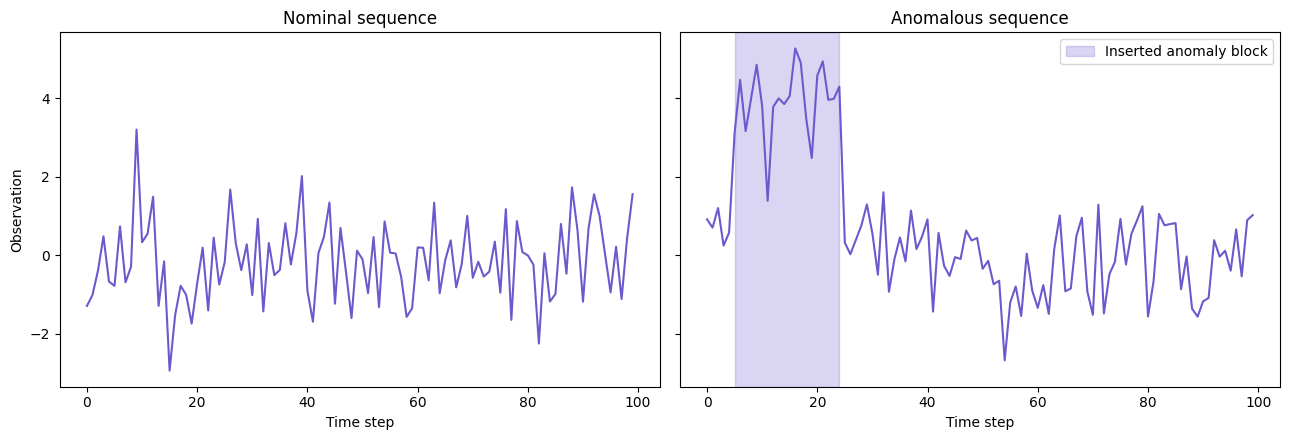

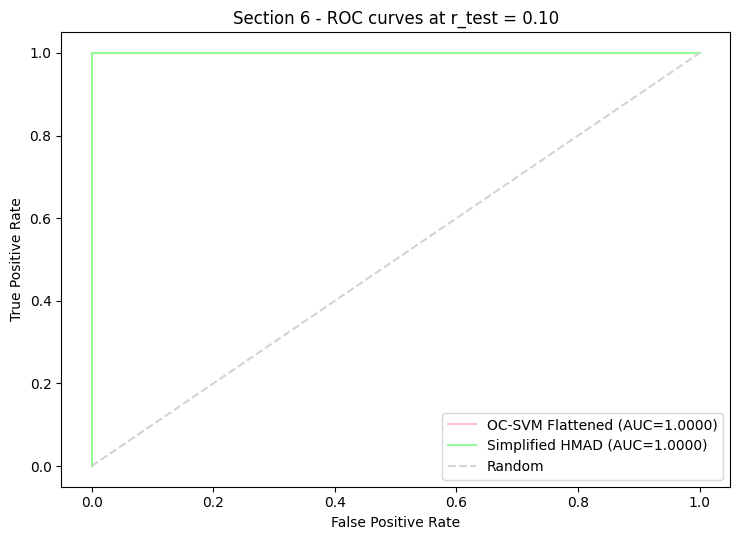

In [29]:

print('SECTION 6 - FIXED TEST FRACTION r_test = 0.10')

fixed_runs_s6 = {}
fixed_rows_s6 = []

for name, feature_fn in SECTION6_REPRESENTATIONS.items():
    run = section6_score_ocsvm(
        ocsvm_models_s6[name],
        feature_fn(X_test_s6),
        y_test_s6,
    )
    fixed_runs_s6[name] = run
    fixed_rows_s6.append({
        'Method': f'OC-SVM - {name}',
        'ROC-AUC': run['ROC-AUC'],
        'Precision': run['Precision'],
        'Recall': run['Recall'],
        'F1': run['F1'],
        'TN': run['TN'],
        'FP': run['FP'],
        'FN': run['FN'],
        'TP': run['TP'],
    })

hmad_fixed_s6 = section6_score_hmad(
    hmad_model_s6,
    X_test_s6,
    y_test_s6,
)
fixed_runs_s6['HMAD'] = hmad_fixed_s6
fixed_rows_s6.append({
    'Method': 'Simplified HMAD',
    'ROC-AUC': hmad_fixed_s6['ROC-AUC'],
    'Precision': hmad_fixed_s6['Precision'],
    'Recall': hmad_fixed_s6['Recall'],
    'F1': hmad_fixed_s6['F1'],
    'TN': hmad_fixed_s6['TN'],
    'FP': hmad_fixed_s6['FP'],
    'FN': hmad_fixed_s6['FN'],
    'TP': hmad_fixed_s6['TP'],
})

fixed_metrics_s6 = pd.DataFrame(fixed_rows_s6)
fixed_metrics_s6.to_csv(
    SECTION6_DIR / 'fixed_rtest_0_10_metrics.csv', index=False
)
display(fixed_metrics_s6.round(6))

normal_index_s6 = int(np.flatnonzero(y_test_s6 == 0)[0])
anomaly_index_s6 = int(np.flatnonzero(y_test_s6 == 1)[0])
anomaly_start_s6 = int(block_starts_s6[anomaly_index_s6])
anomaly_stop_s6 = anomaly_start_s6 + SECTION6_BLOCK_LENGTH

time_axis_s6 = np.arange(SECTION6_T)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].plot(time_axis_s6, X_test_s6[normal_index_s6], color='slateblue')
axes[0].set_title('Nominal sequence')
axes[0].set_xlabel('Time step')
axes[0].set_ylabel('Observation')

axes[1].plot(time_axis_s6, X_test_s6[anomaly_index_s6], color='slateblue')
axes[1].axvspan(
    anomaly_start_s6,
    anomaly_stop_s6 - 1,
    alpha=0.25,
    label='Inserted anomaly block',
    color='slateblue'
)
axes[1].set_title('Anomalous sequence')
axes[1].set_xlabel('Time step')
axes[1].legend()
plt.tight_layout()
plt.savefig(
    SECTION6_DIR / '01_required_sequence_visualization.png',
    dpi=180,
)
plt.show()

plt.figure(figsize=(7.5, 5.5))
flattened_fixed_s6 = fixed_runs_s6['Flattened']
plt.plot(
    flattened_fixed_s6['fpr'],
    flattened_fixed_s6['tpr'],
    label=f"OC-SVM Flattened (AUC={flattened_fixed_s6['ROC-AUC']:.4f})",
    color='pink'
)
plt.plot(
    hmad_fixed_s6['fpr'],
    hmad_fixed_s6['tpr'],
    label=f"Simplified HMAD (AUC={hmad_fixed_s6['ROC-AUC']:.4f})",
    color='palegreen'
)
plt.plot([0, 1], [0, 1], linestyle='--', label='Random', color='lightgray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Section 6 - ROC curves at r_test = 0.10')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(
    SECTION6_DIR / '02_required_roc_curves_rtest_0_10.png',
    dpi=180,
)
plt.show()


SECTION 6 - ANOMALY FRACTION SENSITIVITY


,r_test,Method,ROC-AUC,Precision,Recall,F1,Normal test sequences,Anomalous test sequences
0,0.01,OC-SVM - Flattened,1.0,0.022222,1.0,0.043478,99,1
1,0.01,OC-SVM - Global summary,1.0,0.045455,1.0,0.086957,99,1
2,0.01,OC-SVM - Window summary,1.0,0.027778,1.0,0.054054,99,1
3,0.01,Simplified HMAD,1.0,0.055556,1.0,0.105263,99,1
4,0.05,OC-SVM - Flattened,1.0,0.106383,1.0,0.192308,95,5
5,0.05,OC-SVM - Global summary,1.0,0.200000,1.0,0.333333,95,5
6,0.05,OC-SVM - Window summary,1.0,0.131579,1.0,0.232558,95,5
7,0.05,Simplified HMAD,1.0,0.227273,1.0,0.370370,95,5
8,0.10,OC-SVM - Flattened,1.0,0.204082,1.0,0.338983,90,10
9,0.10,OC-SVM - Global summary,1.0,0.357143,1.0,0.526316,90,10


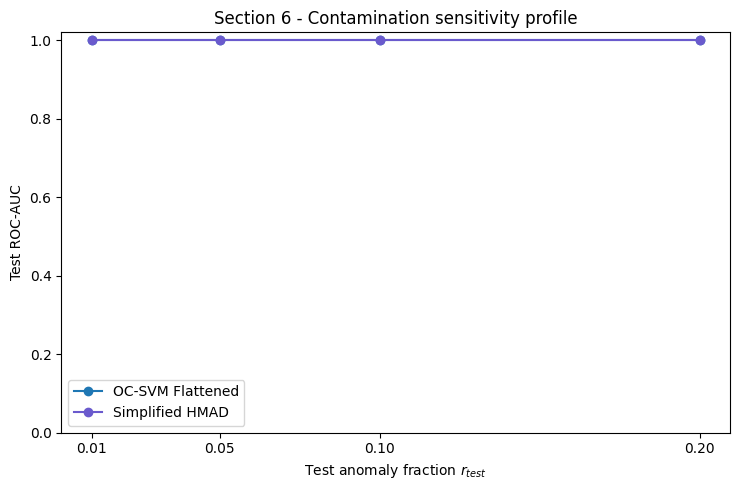

In [30]:

print('SECTION 6 - ANOMALY FRACTION SENSITIVITY')

contamination_rows_s6 = []
score_rows_s6 = []
contamination_runs_s6 = {}

for r_test in SECTION6_RTEST_VALUES:
    X_r, y_r = generate_synthetic_data(
        num_sequences=SECTION6_N_TEST,
        sequence_length=SECTION6_T,
        anomaly_fraction=r_test,
        block_length=SECTION6_BLOCK_LENGTH,
        mu=SECTION6_MU,
        random_state=SECTION6_TEST_RANDOM_STATE,
    )

    contamination_runs_s6[r_test] = {}

    for name, feature_fn in SECTION6_REPRESENTATIONS.items():
        run = section6_score_ocsvm(
            ocsvm_models_s6[name],
            feature_fn(X_r),
            y_r,
        )
        contamination_runs_s6[r_test][name] = run
        contamination_rows_s6.append({
            'r_test': r_test,
            'Method': f'OC-SVM - {name}',
            'ROC-AUC': run['ROC-AUC'],
            'Precision': run['Precision'],
            'Recall': run['Recall'],
            'F1': run['F1'],
            'Normal test sequences': int(np.sum(y_r == 0)),
            'Anomalous test sequences': int(np.sum(y_r == 1)),
        })
        for i in range(len(y_r)):
            score_rows_s6.append({
                'r_test': r_test,
                'Method': f'OC-SVM - {name}',
                'Sequence index': i,
                'True label': int(y_r[i]),
                'Normality score': float(run['normality_scores'][i]),
                'Anomaly score': float(run['anomaly_scores'][i]),
                'Hard prediction': int(run['y_pred'][i]),
            })

    hmad_run = section6_score_hmad(hmad_model_s6, X_r, y_r)
    contamination_runs_s6[r_test]['HMAD'] = hmad_run
    contamination_rows_s6.append({
        'r_test': r_test,
        'Method': 'Simplified HMAD',
        'ROC-AUC': hmad_run['ROC-AUC'],
        'Precision': hmad_run['Precision'],
        'Recall': hmad_run['Recall'],
        'F1': hmad_run['F1'],
        'Normal test sequences': int(np.sum(y_r == 0)),
        'Anomalous test sequences': int(np.sum(y_r == 1)),
    })
    for i in range(len(y_r)):
        score_rows_s6.append({
            'r_test': r_test,
            'Method': 'Simplified HMAD',
            'Sequence index': i,
            'True label': int(y_r[i]),
            'Normality score': float(hmad_run['normality_scores'][i]),
            'Anomaly score': float(hmad_run['anomaly_scores'][i]),
            'Hard prediction': int(hmad_run['y_pred'][i]),
        })

contamination_metrics_s6 = pd.DataFrame(contamination_rows_s6)
contamination_scores_s6 = pd.DataFrame(score_rows_s6)

contamination_metrics_s6.to_csv(
    SECTION6_DIR / 'contamination_sensitivity_metrics.csv', index=False
)
contamination_scores_s6.to_csv(
    SECTION6_DIR / 'contamination_continuous_scores_and_predictions.csv',
    index=False,
)

display(contamination_metrics_s6.round(6))

flattened_profile_s6 = contamination_metrics_s6[
    contamination_metrics_s6['Method'] == 'OC-SVM - Flattened'
].sort_values('r_test')
hmad_profile_s6 = contamination_metrics_s6[
    contamination_metrics_s6['Method'] == 'Simplified HMAD'
].sort_values('r_test')

plt.figure(figsize=(7.5, 5))
plt.plot(
    flattened_profile_s6['r_test'],
    flattened_profile_s6['ROC-AUC'],
    marker='o',
    label='OC-SVM Flattened',
)
plt.plot(
    hmad_profile_s6['r_test'],
    hmad_profile_s6['ROC-AUC'],
    marker='o',
    label='Simplified HMAD',
    color='slateblue'
)
plt.xlabel('Test anomaly fraction $r_{test}$')
plt.ylabel('Test ROC-AUC')
plt.title('Section 6 - Contamination sensitivity profile')
plt.xticks(SECTION6_RTEST_VALUES)
plt.ylim(0.0, 1.02)
plt.legend()
plt.tight_layout()
plt.savefig(
    SECTION6_DIR / '03_required_contamination_sensitivity.png',
    dpi=180,
)
plt.show()


SECTION 6 - ANOMALY BLOCK LENGTH SENSITIVITY


,Block length,Method,ROC-AUC,Precision,Recall,F1
0,5,OC-SVM - Flattened,1.000000,0.200000,1.0,0.333333
1,5,Simplified HMAD,0.763333,0.294118,0.5,0.370370
2,10,OC-SVM - Flattened,1.000000,0.200000,1.0,0.333333
3,10,Simplified HMAD,0.995556,0.454545,1.0,0.625000
4,20,OC-SVM - Flattened,1.000000,0.200000,1.0,0.333333
5,20,Simplified HMAD,1.000000,0.454545,1.0,0.625000
6,40,OC-SVM - Flattened,1.000000,0.200000,1.0,0.333333
7,40,Simplified HMAD,1.000000,0.454545,1.0,0.625000


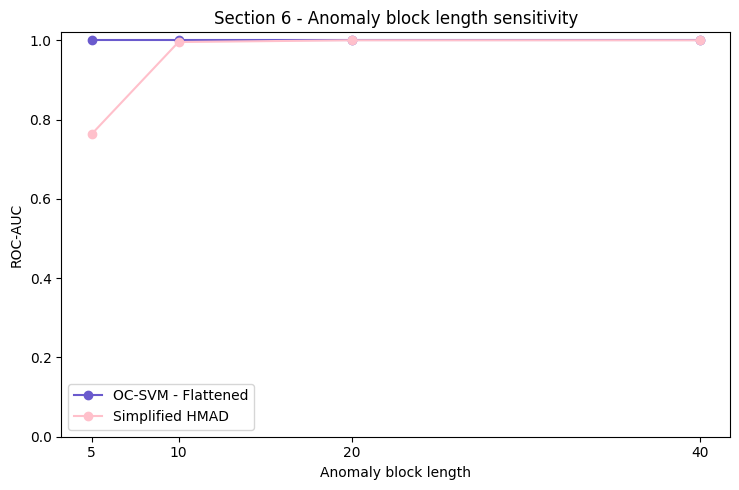

SECTION 6 - NUMBER OF ANOMALOUS BLOCKS SENSITIVITY


,Number of anomalous blocks,Block length,Method,ROC-AUC,Precision,Recall,F1
0,1,20,OC-SVM - Flattened,1.0,0.169492,1.0,0.289855
1,1,20,Simplified HMAD,1.0,0.500000,1.0,0.666667
2,2,20,OC-SVM - Flattened,1.0,0.169492,1.0,0.289855
3,2,20,Simplified HMAD,1.0,0.500000,1.0,0.666667
4,3,20,OC-SVM - Flattened,1.0,0.169492,1.0,0.289855
5,3,20,Simplified HMAD,1.0,0.500000,1.0,0.666667


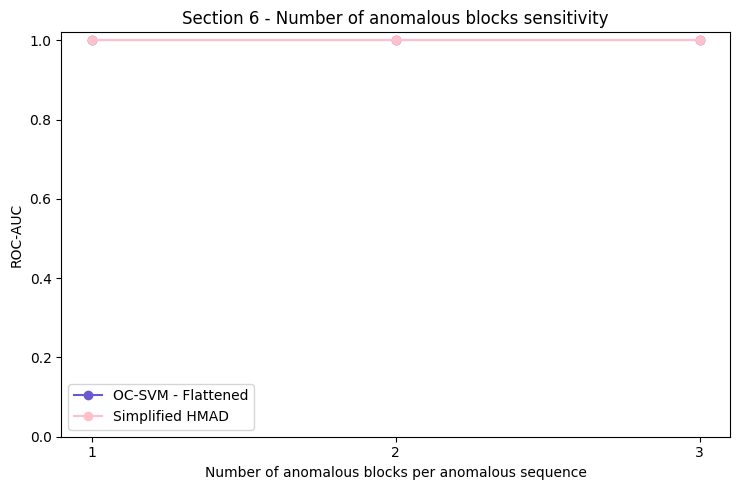

In [31]:

print('SECTION 6 - ANOMALY BLOCK LENGTH SENSITIVITY')

SECTION6_BLOCK_LENGTH_VALUES = [5, 10, 20, 40]
block_length_rows_s6 = []

for block_length in SECTION6_BLOCK_LENGTH_VALUES:
    X_b, y_b = generate_synthetic_data(
        num_sequences=SECTION6_N_TEST,
        sequence_length=SECTION6_T,
        anomaly_fraction=0.10,
        block_length=block_length,
        mu=SECTION6_MU,
        random_state=SECTION6_TEST_RANDOM_STATE + 1,
    )

    oc_run = section6_score_ocsvm(
        ocsvm_models_s6['Flattened'],
        flattened_features(X_b),
        y_b,
    )
    hmad_run = section6_score_hmad(hmad_model_s6, X_b, y_b)

    for method, run in [
        ('OC-SVM - Flattened', oc_run),
        ('Simplified HMAD', hmad_run),
    ]:
        block_length_rows_s6.append({
            'Block length': block_length,
            'Method': method,
            'ROC-AUC': run['ROC-AUC'],
            'Precision': run['Precision'],
            'Recall': run['Recall'],
            'F1': run['F1'],
        })

block_length_metrics_s6 = pd.DataFrame(block_length_rows_s6)
block_length_metrics_s6.to_csv(
    SECTION6_DIR / 'block_length_sensitivity_metrics.csv', index=False
)
display(block_length_metrics_s6.round(6))

plt.figure(figsize=(7.5, 5))
for method in ['OC-SVM - Flattened', 'Simplified HMAD']:
    subset = block_length_metrics_s6[
        block_length_metrics_s6['Method'] == method
    ].sort_values('Block length')
    plt.plot(
        subset['Block length'],
        subset['ROC-AUC'],
        marker='o',
        label=method,
        color='slateblue' if method == 'OC-SVM - Flattened' else 'pink',
    )
plt.xlabel('Anomaly block length')
plt.ylabel('ROC-AUC')
plt.title('Section 6 - Anomaly block length sensitivity')
plt.xticks(SECTION6_BLOCK_LENGTH_VALUES)
plt.ylim(0.0, 1.02)
plt.legend()
plt.tight_layout()
plt.savefig(
    SECTION6_DIR / '04_block_length_sensitivity.png',
    dpi=180,
)
plt.show()


print('SECTION 6 - NUMBER OF ANOMALOUS BLOCKS SENSITIVITY')

SECTION6_BLOCK_COUNT_VALUES = [1, 2, 3]
block_count_rows_s6 = []

for num_blocks in SECTION6_BLOCK_COUNT_VALUES:
    X_c, y_c, _ = section6_generate_multiblock_data(
        num_sequences=SECTION6_N_TEST,
        sequence_length=SECTION6_T,
        anomaly_fraction=0.10,
        block_length=SECTION6_BLOCK_LENGTH,
        num_blocks=num_blocks,
        mu=SECTION6_MU,
        random_state=SECTION6_TEST_RANDOM_STATE + 2,
    )

    oc_run = section6_score_ocsvm(
        ocsvm_models_s6['Flattened'],
        flattened_features(X_c),
        y_c,
    )
    hmad_run = section6_score_hmad(hmad_model_s6, X_c, y_c)

    for method, run in [
        ('OC-SVM - Flattened', oc_run),
        ('Simplified HMAD', hmad_run),
    ]:
        block_count_rows_s6.append({
            'Number of anomalous blocks': num_blocks,
            'Block length': SECTION6_BLOCK_LENGTH,
            'Method': method,
            'ROC-AUC': run['ROC-AUC'],
            'Precision': run['Precision'],
            'Recall': run['Recall'],
            'F1': run['F1'],
        })

block_count_metrics_s6 = pd.DataFrame(block_count_rows_s6)
block_count_metrics_s6.to_csv(
    SECTION6_DIR / 'block_count_sensitivity_metrics.csv', index=False
)
display(block_count_metrics_s6.round(6))

plt.figure(figsize=(7.5, 5))
for method in ['OC-SVM - Flattened', 'Simplified HMAD']:
    subset = block_count_metrics_s6[
        block_count_metrics_s6['Method'] == method
    ].sort_values('Number of anomalous blocks')
    plt.plot(
        subset['Number of anomalous blocks'],
        subset['ROC-AUC'],
        marker='o',
        label=method,
        color='slateblue' if method == 'OC-SVM - Flattened' else 'pink',
    )
plt.xlabel('Number of anomalous blocks per anomalous sequence')
plt.ylabel('ROC-AUC')
plt.title('Section 6 - Number of anomalous blocks sensitivity')
plt.xticks(SECTION6_BLOCK_COUNT_VALUES)
plt.ylim(0.0, 1.02)
plt.legend()
plt.tight_layout()
plt.savefig(
    SECTION6_DIR / '05_block_count_sensitivity.png',
    dpi=180,
)
plt.show()


In [32]:

print('SECTION 6 - FINAL CHECKS')

assert hmad_model_s6['joint_features'].shape == (SECTION6_N_TRAIN, 6)
assert hmad_fixed_s6['joint_features'].shape == (SECTION6_N_TEST, 6)
assert np.allclose(hmad_model_s6['A'].sum(axis=1), 1.0)
assert np.isfinite(hmad_model_s6['means']).all()
assert np.isfinite(hmad_model_s6['variances']).all()
assert (hmad_model_s6['variances'] > 0).all()
assert set(np.round(contamination_metrics_s6['r_test'], 2)) == set(SECTION6_RTEST_VALUES)
assert set(block_length_metrics_s6['Block length']) == set(SECTION6_BLOCK_LENGTH_VALUES)
assert set(block_count_metrics_s6['Number of anomalous blocks']) == set(SECTION6_BLOCK_COUNT_VALUES)
assert len(contamination_scores_s6) == (
    len(SECTION6_RTEST_VALUES)
    * SECTION6_N_TEST
    * (len(SECTION6_REPRESENTATIONS) + 1)
)

section6_summary_s6 = pd.DataFrame([
    {
        'Item': 'Training sequences',
        'Value': SECTION6_N_TRAIN,
    },
    {
        'Item': 'Sequence length',
        'Value': SECTION6_T,
    },
    {
        'Item': 'Required anomaly block length',
        'Value': SECTION6_BLOCK_LENGTH,
    },
    {
        'Item': 'Anomaly mean shift',
        'Value': SECTION6_MU,
    },
    {
        'Item': 'HMAD joint feature dimension',
        'Value': hmad_model_s6['joint_features'].shape[1],
    },
    {
        'Item': 'HMAD iterations',
        'Value': len(hmad_history_s6),
    },
    {
        'Item': 'Fixed r_test=0.1 OC-SVM Flattened ROC-AUC',
        'Value': fixed_runs_s6['Flattened']['ROC-AUC'],
    },
    {
        'Item': 'Fixed r_test=0.1 HMAD ROC-AUC',
        'Value': hmad_fixed_s6['ROC-AUC'],
    },
])

section6_summary_s6.to_csv(
    SECTION6_DIR / 'section6_summary.csv', index=False
)
display(section6_summary_s6)
print('SECTION 6 REQUIRED IMPLEMENTATION COMPLETED')


SECTION 6 - FINAL CHECKS


,Item,Value
0,Training sequences,200.0
1,Sequence length,100.0
2,Required anomaly block length,20.0
3,Anomaly mean shift,4.0
4,HMAD joint feature dimension,6.0
5,HMAD iterations,10.0
6,Fixed r_test=0.1 OC-SVM Flattened ROC-AUC,1.0
7,Fixed r_test=0.1 HMAD ROC-AUC,1.0


SECTION 6 REQUIRED IMPLEMENTATION COMPLETED


In [33]:

print('SECTION 6 - CANDIDATE B BONUS: BIOINFORMATICS-INSPIRED CATEGORICAL SEQUENCES')

from pathlib import Path

CANDIDATE_B_DIR = RESULTS_DIR / 'Section_6_Candidate_B_Bonus'
CANDIDATE_B_DIR.mkdir(parents=True, exist_ok=True)

CANDIDATE_B_RANDOM_STATE = 1405
CANDIDATE_B_TEST_RANDOM_STATE = 2405
CANDIDATE_B_N_TRAIN = 200
CANDIDATE_B_N_TEST = 200
CANDIDATE_B_TEST_ANOMALY_FRACTION = 0.50
CANDIDATE_B_T = 120
CANDIDATE_B_NU = 0.10
CANDIDATE_B_MAX_ITER = 10
CANDIDATE_B_K = 4
CANDIDATE_B_V = 4
CANDIDATE_B_SHUFFLE_CHUNK = 10

CANDIDATE_B_STATE_NAMES = ['Intergenic', 'Start', 'Exon', 'Stop']
CANDIDATE_B_TOKEN_NAMES = ['I-like', 'Start-like', 'Exon-like', 'Stop-like']

CANDIDATE_B_REGION_LENGTHS = [30, 3, 54, 3, 30]
CANDIDATE_B_REGION_STATES = [0, 1, 2, 3, 0]

CANDIDATE_B_EMISSION_TEMPLATE = np.full(
    (CANDIDATE_B_K, CANDIDATE_B_V),
    0.04 / (CANDIDATE_B_V - 1),
    dtype=float,
)
np.fill_diagonal(CANDIDATE_B_EMISSION_TEMPLATE, 0.96)


def candidate_b_generate_nominal_sequence(rng):
    sequence_parts = []
    state_parts = []

    for state, length in zip(
        CANDIDATE_B_REGION_STATES,
        CANDIDATE_B_REGION_LENGTHS,
    ):
        observations = rng.choice(
            CANDIDATE_B_V,
            size=length,
            p=CANDIDATE_B_EMISSION_TEMPLATE[state],
        )
        sequence_parts.append(observations)
        state_parts.append(np.full(length, state, dtype=int))

    return np.concatenate(sequence_parts), np.concatenate(state_parts)


def candidate_b_shuffle_chunks(sequence, states, rng, chunk_size=10):
    starts = list(range(0, len(sequence), chunk_size))
    sequence_chunks = [
        sequence[start:min(start + chunk_size, len(sequence))]
        for start in starts
    ]
    state_chunks = [
        states[start:min(start + chunk_size, len(states))]
        for start in starts
    ]

    permutation = rng.permutation(len(sequence_chunks))
    while np.array_equal(permutation, np.arange(len(sequence_chunks))):
        permutation = rng.permutation(len(sequence_chunks))

    shuffled_sequence = np.concatenate([
        sequence_chunks[index] for index in permutation
    ])
    shuffled_states = np.concatenate([
        state_chunks[index] for index in permutation
    ])

    return shuffled_sequence, shuffled_states, permutation


def candidate_b_generate_dataset(
    num_sequences,
    anomaly_fraction,
    random_state,
    chunk_size=CANDIDATE_B_SHUFFLE_CHUNK,
):
    rng = np.random.default_rng(random_state)

    num_anomalies = int(np.round(num_sequences * anomaly_fraction))
    labels = np.array(
        [0] * (num_sequences - num_anomalies)
        + [1] * num_anomalies,
        dtype=int,
    )
    rng.shuffle(labels)

    sequences = []
    true_states = []
    permutations = []

    for label in labels:
        sequence, states = candidate_b_generate_nominal_sequence(rng)

        if label == 1:
            sequence, states, permutation = candidate_b_shuffle_chunks(
                sequence,
                states,
                rng,
                chunk_size=chunk_size,
            )
        else:
            permutation = np.arange(
                int(np.ceil(len(sequence) / chunk_size))
            )

        sequences.append(sequence)
        true_states.append(states)
        permutations.append(permutation)

    return (
        np.vstack(sequences),
        labels,
        np.vstack(true_states),
        permutations,
    )


X_train_candidate_b, y_train_candidate_b, z_train_true_candidate_b, _ = (
    candidate_b_generate_dataset(
        num_sequences=CANDIDATE_B_N_TRAIN,
        anomaly_fraction=0.0,
        random_state=CANDIDATE_B_RANDOM_STATE,
    )
)

X_test_candidate_b, y_test_candidate_b, z_test_true_candidate_b, permutation_candidate_b = (
    candidate_b_generate_dataset(
        num_sequences=CANDIDATE_B_N_TEST,
        anomaly_fraction=CANDIDATE_B_TEST_ANOMALY_FRACTION,
        random_state=CANDIDATE_B_TEST_RANDOM_STATE,
    )
)

candidate_b_dataset_summary = pd.DataFrame([
    {'Item': 'Training sequences', 'Value': len(X_train_candidate_b)},
    {'Item': 'Training anomalies', 'Value': int(y_train_candidate_b.sum())},
    {'Item': 'Test sequences', 'Value': len(X_test_candidate_b)},
    {'Item': 'Test normal sequences', 'Value': int(np.sum(y_test_candidate_b == 0))},
    {'Item': 'Test anomalous sequences', 'Value': int(np.sum(y_test_candidate_b == 1))},
    {'Item': 'Sequence length', 'Value': CANDIDATE_B_T},
    {'Item': 'Functional states', 'Value': CANDIDATE_B_K},
    {'Item': 'Categorical observation symbols', 'Value': CANDIDATE_B_V},
    {'Item': 'Structural anomaly chunk size', 'Value': CANDIDATE_B_SHUFFLE_CHUNK},
])

display(candidate_b_dataset_summary)


SECTION 6 - CANDIDATE B BONUS: BIOINFORMATICS-INSPIRED CATEGORICAL SEQUENCES


,Item,Value
0,Training sequences,200
1,Training anomalies,0
2,Test sequences,200
3,Test normal sequences,100
4,Test anomalous sequences,100
5,Sequence length,120
6,Functional states,4
7,Categorical observation symbols,4
8,Structural anomaly chunk size,10


In [52]:

def candidate_b_composition_features(X):
    X = np.asarray(X, dtype=int)
    features = np.zeros((len(X), CANDIDATE_B_V), dtype=float)
    for row, sequence in enumerate(X):
        features[row] = (
            np.bincount(sequence, minlength=CANDIDATE_B_V)
            / len(sequence)
        )
    return features


def candidate_b_bigram_features(X):
    X = np.asarray(X, dtype=int)
    features = np.zeros(
        (len(X), CANDIDATE_B_V * CANDIDATE_B_V),
        dtype=float,
    )
    for row, sequence in enumerate(X):
        bigram_ids = sequence[:-1] * CANDIDATE_B_V + sequence[1:]
        features[row] = (
            np.bincount(
                bigram_ids,
                minlength=CANDIDATE_B_V * CANDIDATE_B_V,
            )
            / max(len(sequence) - 1, 1)
        )
    return features


def candidate_b_flattened_onehot_features(X):
    X = np.asarray(X, dtype=int)
    identity = np.eye(CANDIDATE_B_V, dtype=float)
    return identity[X].reshape(len(X), -1)


def candidate_b_fit_ocsvm(train_features, nu=CANDIDATE_B_NU):
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(
        np.asarray(train_features, dtype=float)
    )
    model = OneClassSVM(kernel='rbf', gamma='scale', nu=nu)
    model.fit(train_scaled)
    return {'scaler': scaler, 'model': model}


def candidate_b_score_ocsvm(bundle, test_features, y_true):
    test_scaled = bundle['scaler'].transform(
        np.asarray(test_features, dtype=float)
    )
    normality_scores = bundle['model'].decision_function(test_scaled).ravel()
    anomaly_scores = -normality_scores
    y_pred = (normality_scores < 0).astype(int)

    fpr, tpr, _ = roc_curve(y_true, anomaly_scores)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    return {
        'normality_scores': normality_scores,
        'anomaly_scores': anomaly_scores,
        'y_pred': y_pred,
        'fpr': fpr,
        'tpr': tpr,
        'ROC-AUC': float(roc_auc_score(y_true, anomaly_scores)),
        'Precision': float(precision_score(y_true, y_pred, zero_division=0)),
        'Recall': float(recall_score(y_true, y_pred, zero_division=0)),
        'F1': float(f1_score(y_true, y_pred, zero_division=0)),
        'TN': int(tn),
        'FP': int(fp),
        'FN': int(fn),
        'TP': int(tp),
    }


def candidate_b_viterbi_categorical(sequence, pi, A, emission_probabilities):
    sequence = np.asarray(sequence, dtype=int)
    K = len(pi)
    T = len(sequence)
    tiny = 1e-300

    log_pi = np.log(np.clip(pi, tiny, None))
    log_A = np.log(np.clip(A, tiny, None))
    log_emission = np.log(np.clip(emission_probabilities, tiny, None))

    delta = np.full((T, K), -np.inf, dtype=float)
    backpointer = np.zeros((T, K), dtype=int)
    delta[0] = log_pi + log_emission[:, sequence[0]]

    for t in range(1, T):
        scores = delta[t - 1][:, None] + log_A
        backpointer[t] = np.argmax(scores, axis=0)
        delta[t] = scores[backpointer[t], np.arange(K)] + log_emission[:, sequence[t]]

    path = np.zeros(T, dtype=int)
    path[-1] = int(np.argmax(delta[-1]))
    for t in range(T - 2, -1, -1):
        path[t] = backpointer[t + 1, path[t + 1]]

    return path, float(delta[-1, path[-1]])


def candidate_b_joint_features(sequence, states, K=CANDIDATE_B_K, V=CANDIDATE_B_V):
    sequence = np.asarray(sequence, dtype=int)
    states = np.asarray(states, dtype=int)

    transition_features = np.zeros((K, K), dtype=float)
    np.add.at(transition_features, (states[:-1], states[1:]), 1.0)
    transition_features /= max(len(states) - 1, 1)

    emission_features = np.zeros((K, V), dtype=float)
    for state in range(K):
        observations = sequence[states == state]
        if len(observations) > 0:
            emission_features[state] = (
                np.bincount(observations, minlength=V) / len(observations)
            )

    return np.concatenate([
        transition_features.ravel(),
        emission_features.ravel(),
    ])


def candidate_b_initial_hmm():
    pi = np.array([0.997, 0.001, 0.001, 0.001], dtype=float)
    pi /= pi.sum()

    A = np.full((CANDIDATE_B_K, CANDIDATE_B_K), 1e-4, dtype=float)
    A[0, 0] = 0.97
    A[0, 1] = 0.03
    A[1, 1] = 0.67
    A[1, 2] = 0.33
    A[2, 2] = 0.982
    A[2, 3] = 0.018
    A[3, 3] = 0.67
    A[3, 0] = 0.33
    A /= A.sum(axis=1, keepdims=True)

    emissions = CANDIDATE_B_EMISSION_TEMPLATE.copy()
    return pi, A, emissions


def candidate_b_fit_hmad(
    X_train,
    nu=CANDIDATE_B_NU,
    max_iter=CANDIDATE_B_MAX_ITER,
    tol=0.005,
    smoothing=0.5,
):
    X_train = np.asarray(X_train, dtype=int)
    pi, A, emissions = candidate_b_initial_hmm()

    previous_states = None
    history = []
    joint_features = None
    scaler = None
    model = None
    decoded_states = None

    for iteration in range(1, max_iter + 1):
        decoded_states = np.vstack([
            candidate_b_viterbi_categorical(sequence, pi, A, emissions)[0]
            for sequence in X_train
        ])

        if previous_states is None:
            changed_fraction = 1.0
        else:
            changed_fraction = float(np.mean(decoded_states != previous_states))

        initial_counts = (
            np.bincount(decoded_states[:, 0], minlength=CANDIDATE_B_K).astype(float)
            + smoothing
        )
        pi = initial_counts / initial_counts.sum()

        transition_counts = np.full(
            (CANDIDATE_B_K, CANDIDATE_B_K),
            smoothing,
            dtype=float,
        )
        for states in decoded_states:
            np.add.at(transition_counts, (states[:-1], states[1:]), 1.0)
        A = transition_counts / transition_counts.sum(axis=1, keepdims=True)

        emission_counts = np.full(
            (CANDIDATE_B_K, CANDIDATE_B_V),
            smoothing,
            dtype=float,
        )
        for sequence, states in zip(X_train, decoded_states):
            for state in range(CANDIDATE_B_K):
                observations = sequence[states == state]
                if len(observations) > 0:
                    emission_counts[state] += np.bincount(
                        observations,
                        minlength=CANDIDATE_B_V,
                    )

        emissions = emission_counts / emission_counts.sum(axis=1, keepdims=True)

        joint_features = np.vstack([
            candidate_b_joint_features(sequence, states)
            for sequence, states in zip(X_train, decoded_states)
        ])

        scaler = StandardScaler()
        joint_scaled = scaler.fit_transform(joint_features)
        model = OneClassSVM(kernel='rbf', gamma='scale', nu=nu)
        model.fit(joint_scaled)
        mean_training_score = float(model.decision_function(joint_scaled).mean())

        history.append({
            'Iteration': iteration,
            'Changed-state fraction': changed_fraction,
            'Mean OC-SVM decision score': mean_training_score,
        })

        if previous_states is not None and changed_fraction < tol:
            break
        previous_states = decoded_states.copy()

    return {
        'pi': pi,
        'A': A,
        'emissions': emissions,
        'states': decoded_states,
        'joint_features': joint_features,
        'scaler': scaler,
        'model': model,
        'history': pd.DataFrame(history),
    }


def candidate_b_score_hmad(bundle, X_test, y_true):
    X_test = np.asarray(X_test, dtype=int)

    states = np.vstack([
        candidate_b_viterbi_categorical(
            sequence,
            bundle['pi'],
            bundle['A'],
            bundle['emissions'],
        )[0]
        for sequence in X_test
    ])

    joint_features = np.vstack([
        candidate_b_joint_features(sequence, state_path)
        for sequence, state_path in zip(X_test, states)
    ])

    joint_scaled = bundle['scaler'].transform(joint_features)
    normality_scores = bundle['model'].decision_function(joint_scaled).ravel()
    anomaly_scores = -normality_scores
    y_pred = (normality_scores < 0).astype(int)

    fpr, tpr, _ = roc_curve(y_true, anomaly_scores)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    return {
        'states': states,
        'joint_features': joint_features,
        'normality_scores': normality_scores,
        'anomaly_scores': anomaly_scores,
        'y_pred': y_pred,
        'fpr': fpr,
        'tpr': tpr,
        'ROC-AUC': float(roc_auc_score(y_true, anomaly_scores)),
        'Precision': float(precision_score(y_true, y_pred, zero_division=0)),
        'Recall': float(recall_score(y_true, y_pred, zero_division=0)),
        'F1': float(f1_score(y_true, y_pred, zero_division=0)),
        'TN': int(tn),
        'FP': int(fp),
        'FN': int(fn),
        'TP': int(tp),
    }


CANDIDATE B - DATA EXAMPLES


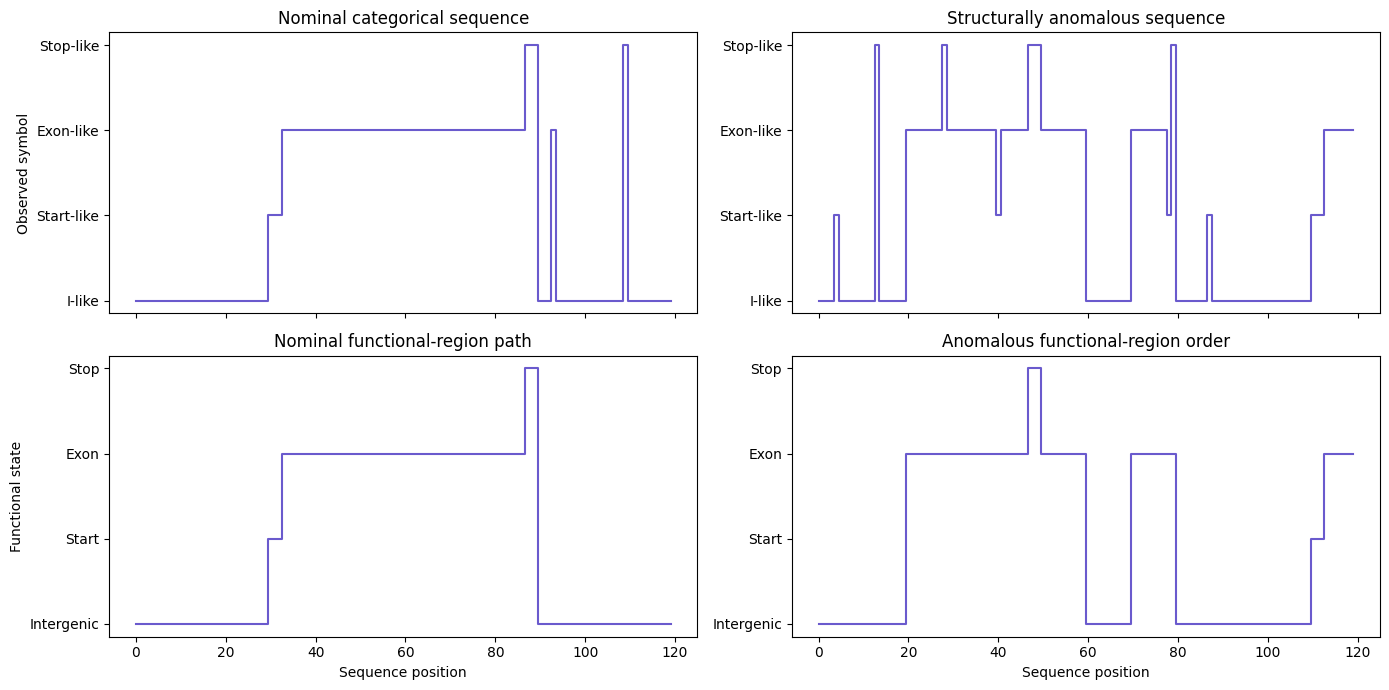

Anomalous chunk permutation: [10  0  4  6  8  5 11  7  2  1  9  3]


In [35]:

print('CANDIDATE B - DATA EXAMPLES')

normal_index_candidate_b = int(np.flatnonzero(y_test_candidate_b == 0)[0])
anomaly_index_candidate_b = int(np.flatnonzero(y_test_candidate_b == 1)[0])

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)

axes[0, 0].step(
    np.arange(CANDIDATE_B_T),
    X_test_candidate_b[normal_index_candidate_b],
    where='mid',
    color='slateblue'
)
axes[0, 0].set_title('Nominal categorical sequence')
axes[0, 0].set_ylabel('Observed symbol')
axes[0, 0].set_yticks(range(CANDIDATE_B_V), CANDIDATE_B_TOKEN_NAMES)

axes[1, 0].step(
    np.arange(CANDIDATE_B_T),
    z_test_true_candidate_b[normal_index_candidate_b],
    where='mid',
    color='slateblue'
)
axes[1, 0].set_title('Nominal functional-region path')
axes[1, 0].set_xlabel('Sequence position')
axes[1, 0].set_ylabel('Functional state')
axes[1, 0].set_yticks(range(CANDIDATE_B_K), CANDIDATE_B_STATE_NAMES)

axes[0, 1].step(
    np.arange(CANDIDATE_B_T),
    X_test_candidate_b[anomaly_index_candidate_b],
    where='mid',
    color='slateblue'
)
axes[0, 1].set_title('Structurally anomalous sequence')
axes[0, 1].set_yticks(range(CANDIDATE_B_V), CANDIDATE_B_TOKEN_NAMES)

axes[1, 1].step(
    np.arange(CANDIDATE_B_T),
    z_test_true_candidate_b[anomaly_index_candidate_b],
    where='mid',
    color='slateblue'
)
axes[1, 1].set_title('Anomalous functional-region order')
axes[1, 1].set_xlabel('Sequence position')
axes[1, 1].set_yticks(range(CANDIDATE_B_K), CANDIDATE_B_STATE_NAMES)

plt.tight_layout()
plt.savefig(CANDIDATE_B_DIR / '01_candidate_b_sequence_examples.png', dpi=180)
plt.show()

print('Anomalous chunk permutation:', permutation_candidate_b[anomaly_index_candidate_b])


CANDIDATE B - MODEL TRAINING


,Iteration,Changed-state fraction,Mean OC-SVM decision score
0,1,1.0,0.350887
1,2,0.0,0.350887


,Intergenic,Start,Exon,Stop
Intergenic,0.982865,0.017050,0.000042,0.000042
Start,0.000868,0.650174,0.348090,0.000868
Exon,0.000046,0.000046,0.981396,0.018512
Stop,0.343911,0.000858,0.000858,0.654374


,I-like,Start-like,Exon-like,Stop-like
Intergenic,0.958767,0.013689,0.013190,0.014355
Start,0.000867,0.992201,0.000867,0.006066
Exon,0.015742,0.014819,0.954067,0.015373
Stop,0.002573,0.006003,0.000858,0.990566


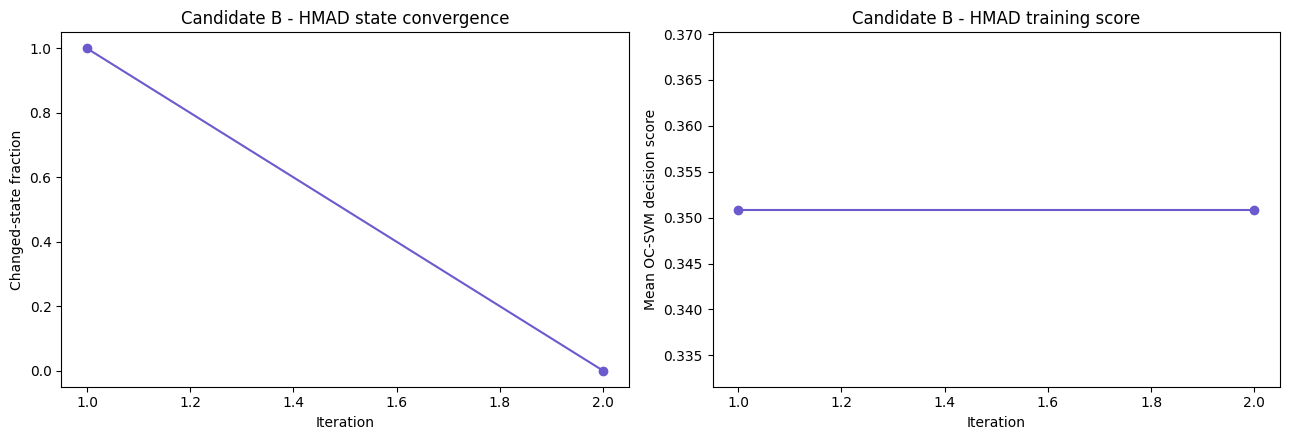

In [36]:

print('CANDIDATE B - MODEL TRAINING')

CANDIDATE_B_REPRESENTATIONS = {
    'Global composition': candidate_b_composition_features,
    'Bigram frequencies': candidate_b_bigram_features,
    'Flattened one-hot': candidate_b_flattened_onehot_features,
}

candidate_b_ocsvm_models = {}
for name, feature_fn in CANDIDATE_B_REPRESENTATIONS.items():
    candidate_b_ocsvm_models[name] = candidate_b_fit_ocsvm(
        feature_fn(X_train_candidate_b),
        nu=CANDIDATE_B_NU,
    )

candidate_b_hmad_model = candidate_b_fit_hmad(
    X_train_candidate_b,
    nu=CANDIDATE_B_NU,
    max_iter=CANDIDATE_B_MAX_ITER,
    tol=0.005,
)

candidate_b_hmad_history = candidate_b_hmad_model['history']

candidate_b_transition_table = pd.DataFrame(
    candidate_b_hmad_model['A'],
    index=CANDIDATE_B_STATE_NAMES,
    columns=CANDIDATE_B_STATE_NAMES,
)

candidate_b_emission_table = pd.DataFrame(
    candidate_b_hmad_model['emissions'],
    index=CANDIDATE_B_STATE_NAMES,
    columns=CANDIDATE_B_TOKEN_NAMES,
)

candidate_b_hmad_history.to_csv(
    CANDIDATE_B_DIR / 'hmad_training_history.csv',
    index=False,
)
candidate_b_transition_table.to_csv(
    CANDIDATE_B_DIR / 'learned_transition_matrix.csv',
)
candidate_b_emission_table.to_csv(
    CANDIDATE_B_DIR / 'learned_categorical_emissions.csv',
)

display(candidate_b_hmad_history.round(6))
display(candidate_b_transition_table.round(6))
display(candidate_b_emission_table.round(6))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    candidate_b_hmad_history['Iteration'],
    candidate_b_hmad_history['Changed-state fraction'],
    marker='o',
    color='slateblue'
)
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Changed-state fraction')
axes[0].set_title('Candidate B - HMAD state convergence')

axes[1].plot(
    candidate_b_hmad_history['Iteration'],
    candidate_b_hmad_history['Mean OC-SVM decision score'],
    marker='o',
    color='slateblue'
)
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Mean OC-SVM decision score')
axes[1].set_title('Candidate B - HMAD training score')

plt.tight_layout()
plt.savefig(CANDIDATE_B_DIR / '02_candidate_b_hmad_training.png', dpi=180)
plt.show()


CANDIDATE B - FINAL TEST EVALUATION


,Method,ROC-AUC,Precision,Recall,F1,TN,FP,FN,TP
0,OC-SVM - Global composition,0.5671,0.612903,0.19,0.290076,88,12,81,19
1,OC-SVM - Bigram frequencies,0.7251,0.728571,0.51,0.600000,81,19,49,51
2,OC-SVM - Flattened one-hot,1.0000,0.724638,1.00,0.840336,62,38,0,100
3,Categorical HMAD,0.9968,0.819672,1.00,0.900901,78,22,0,100


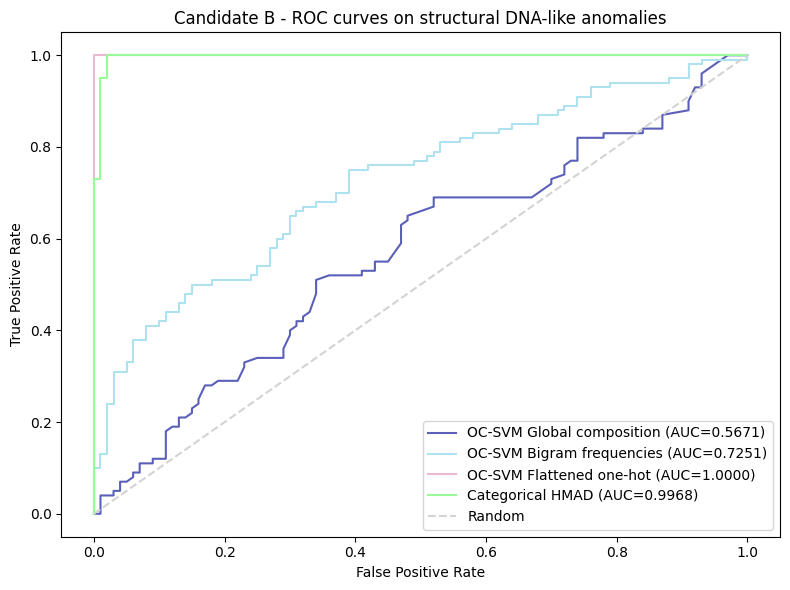

In [37]:

print('CANDIDATE B - FINAL TEST EVALUATION')

candidate_b_runs = {}
candidate_b_metric_rows = []

for name, feature_fn in CANDIDATE_B_REPRESENTATIONS.items():
    run = candidate_b_score_ocsvm(
        candidate_b_ocsvm_models[name],
        feature_fn(X_test_candidate_b),
        y_test_candidate_b,
    )
    candidate_b_runs[name] = run
    candidate_b_metric_rows.append({
        'Method': f'OC-SVM - {name}',
        'ROC-AUC': run['ROC-AUC'],
        'Precision': run['Precision'],
        'Recall': run['Recall'],
        'F1': run['F1'],
        'TN': run['TN'],
        'FP': run['FP'],
        'FN': run['FN'],
        'TP': run['TP'],
    })

candidate_b_hmad_run = candidate_b_score_hmad(
    candidate_b_hmad_model,
    X_test_candidate_b,
    y_test_candidate_b,
)

candidate_b_runs['Categorical HMAD'] = candidate_b_hmad_run
candidate_b_metric_rows.append({
    'Method': 'Categorical HMAD',
    'ROC-AUC': candidate_b_hmad_run['ROC-AUC'],
    'Precision': candidate_b_hmad_run['Precision'],
    'Recall': candidate_b_hmad_run['Recall'],
    'F1': candidate_b_hmad_run['F1'],
    'TN': candidate_b_hmad_run['TN'],
    'FP': candidate_b_hmad_run['FP'],
    'FN': candidate_b_hmad_run['FN'],
    'TP': candidate_b_hmad_run['TP'],
})

candidate_b_metrics = pd.DataFrame(candidate_b_metric_rows)
candidate_b_metrics.to_csv(
    CANDIDATE_B_DIR / 'candidate_b_final_metrics.csv',
    index=False,
)
display(candidate_b_metrics.round(6))

plt.figure(figsize=(8, 6))
colors = {
    'Global composition': "#5A60BA",
    'Bigram frequencies': "#AFE2EF",
    'Flattened one-hot': "#EBB9D3",
}
for name in ['Global composition', 'Bigram frequencies', 'Flattened one-hot']:
    run = candidate_b_runs[name]
    plt.plot(
        run['fpr'],
        run['tpr'],
        label=f"OC-SVM {name} (AUC={run['ROC-AUC']:.4f})",
        color=colors[name],
    )

plt.plot(
    candidate_b_hmad_run['fpr'],
    candidate_b_hmad_run['tpr'],
    label=f"Categorical HMAD (AUC={candidate_b_hmad_run['ROC-AUC']:.4f})",
    color='palegreen'
)
plt.plot([0, 1], [0, 1], linestyle='--', label='Random', color='lightgray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Candidate B - ROC curves on structural DNA-like anomalies')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(CANDIDATE_B_DIR / '03_candidate_b_roc_curves.png', dpi=180)
plt.show()


CANDIDATE B - STRUCTURAL DISRUPTION SENSITIVITY


,Shuffle chunk size,Method,ROC-AUC,Precision,Recall,F1
0,5,OC-SVM - Bigram frequencies,0.95550,0.840708,0.95,0.892019
1,5,OC-SVM - Flattened one-hot,1.00000,0.724638,1.00,0.840336
2,5,Categorical HMAD,1.00000,0.819672,1.00,0.900901
3,10,OC-SVM - Bigram frequencies,0.70050,0.729730,0.54,0.620690
4,10,OC-SVM - Flattened one-hot,1.00000,0.694444,1.00,0.819672
5,10,Categorical HMAD,0.99750,0.847458,1.00,0.917431
6,20,OC-SVM - Bigram frequencies,0.52805,0.611111,0.33,0.428571
7,20,OC-SVM - Flattened one-hot,1.00000,0.709220,1.00,0.829876
8,20,Categorical HMAD,0.89000,0.794393,0.85,0.821256
9,30,OC-SVM - Bigram frequencies,0.61425,0.610169,0.36,0.452830


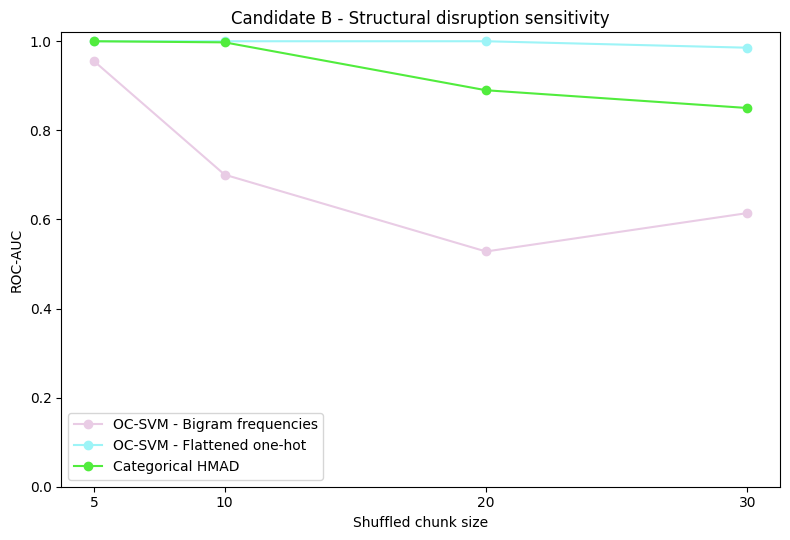

In [38]:

print('CANDIDATE B - STRUCTURAL DISRUPTION SENSITIVITY')

CANDIDATE_B_CHUNK_SIZES = [5, 10, 20, 30]
candidate_b_sensitivity_rows = []

for chunk_size in CANDIDATE_B_CHUNK_SIZES:
    X_chunk, y_chunk, _, _ = candidate_b_generate_dataset(
        num_sequences=CANDIDATE_B_N_TEST,
        anomaly_fraction=CANDIDATE_B_TEST_ANOMALY_FRACTION,
        random_state=CANDIDATE_B_TEST_RANDOM_STATE + chunk_size,
        chunk_size=chunk_size,
    )

    bigram_run = candidate_b_score_ocsvm(
        candidate_b_ocsvm_models['Bigram frequencies'],
        candidate_b_bigram_features(X_chunk),
        y_chunk,
    )
    flattened_run = candidate_b_score_ocsvm(
        candidate_b_ocsvm_models['Flattened one-hot'],
        candidate_b_flattened_onehot_features(X_chunk),
        y_chunk,
    )
    hmad_run = candidate_b_score_hmad(
        candidate_b_hmad_model,
        X_chunk,
        y_chunk,
    )

    for method, run in [
        ('OC-SVM - Bigram frequencies', bigram_run),
        ('OC-SVM - Flattened one-hot', flattened_run),
        ('Categorical HMAD', hmad_run),
    ]:
        candidate_b_sensitivity_rows.append({
            'Shuffle chunk size': chunk_size,
            'Method': method,
            'ROC-AUC': run['ROC-AUC'],
            'Precision': run['Precision'],
            'Recall': run['Recall'],
            'F1': run['F1'],
        })

candidate_b_sensitivity = pd.DataFrame(candidate_b_sensitivity_rows)
candidate_b_sensitivity.to_csv(
    CANDIDATE_B_DIR / 'structural_disruption_sensitivity.csv',
    index=False,
)
display(candidate_b_sensitivity.round(6))
colors = {
    'OC-SVM - Bigram frequencies': "#E9CCE5",
    'OC-SVM - Flattened one-hot': "#9DF4F7",
    'Categorical HMAD': "#51EC3D",
}
plt.figure(figsize=(8, 5.5))
for method in [
    'OC-SVM - Bigram frequencies',
    'OC-SVM - Flattened one-hot',
    'Categorical HMAD',
]:
    subset = candidate_b_sensitivity[
        candidate_b_sensitivity['Method'] == method
    ].sort_values('Shuffle chunk size')
    plt.plot(
        subset['Shuffle chunk size'],
        subset['ROC-AUC'],
        marker='o',
        label=method,
        color=colors[method],
    )

plt.xlabel('Shuffled chunk size')
plt.ylabel('ROC-AUC')
plt.title('Candidate B - Structural disruption sensitivity')
plt.xticks(CANDIDATE_B_CHUNK_SIZES)
plt.ylim(0.0, 1.02)
plt.legend()
plt.tight_layout()
plt.savefig(CANDIDATE_B_DIR / '04_candidate_b_structural_sensitivity.png', dpi=180)
plt.show()


CANDIDATE B - VITERBI PATH EXAMPLES


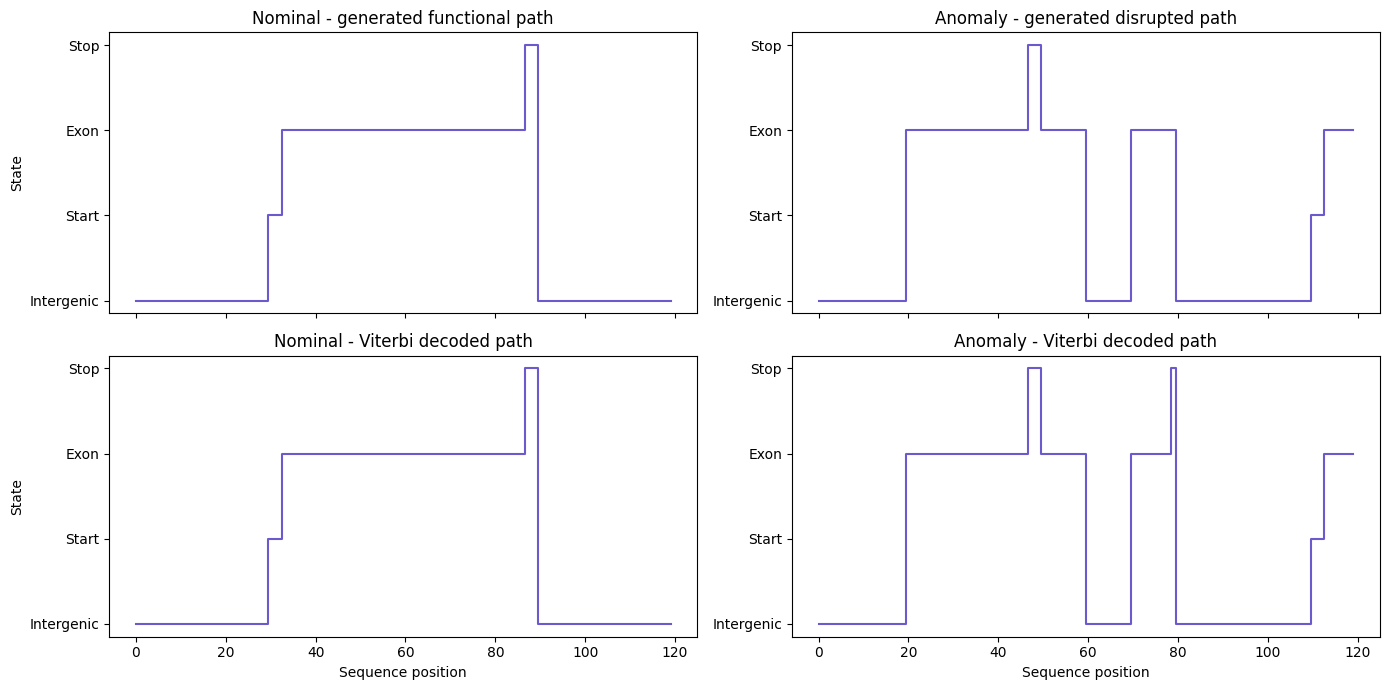

In [53]:

print('CANDIDATE B - VITERBI PATH EXAMPLES')

candidate_b_correct_normal = np.flatnonzero(
    (y_test_candidate_b == 0)
    & (candidate_b_hmad_run['y_pred'] == 0)
)
candidate_b_correct_anomaly = np.flatnonzero(
    (y_test_candidate_b == 1)
    & (candidate_b_hmad_run['y_pred'] == 1)
)

normal_path_index_candidate_b = int(
    candidate_b_correct_normal[0]
    if len(candidate_b_correct_normal) > 0
    else np.flatnonzero(y_test_candidate_b == 0)[0]
)
anomaly_path_index_candidate_b = int(
    candidate_b_correct_anomaly[0]
    if len(candidate_b_correct_anomaly) > 0
    else np.flatnonzero(y_test_candidate_b == 1)[0]
)

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)

axes[0, 0].step(
    np.arange(CANDIDATE_B_T),
    z_test_true_candidate_b[normal_path_index_candidate_b],
    where='mid',
    color='slateblue'
)
axes[0, 0].set_title('Nominal - generated functional path')
axes[0, 0].set_ylabel('State')
axes[0, 0].set_yticks(range(CANDIDATE_B_K), CANDIDATE_B_STATE_NAMES)

axes[1, 0].step(
    np.arange(CANDIDATE_B_T),
    candidate_b_hmad_run['states'][normal_path_index_candidate_b],
    where='mid',
    color='slateblue'
)
axes[1, 0].set_title('Nominal - Viterbi decoded path')
axes[1, 0].set_xlabel('Sequence position')
axes[1, 0].set_ylabel('State')
axes[1, 0].set_yticks(range(CANDIDATE_B_K), CANDIDATE_B_STATE_NAMES)

axes[0, 1].step(
    np.arange(CANDIDATE_B_T),
    z_test_true_candidate_b[anomaly_path_index_candidate_b],
    where='mid',
    color='slateblue'
)
axes[0, 1].set_title('Anomaly - generated disrupted path')
axes[0, 1].set_yticks(range(CANDIDATE_B_K), CANDIDATE_B_STATE_NAMES)

axes[1, 1].step(
    np.arange(CANDIDATE_B_T),
    candidate_b_hmad_run['states'][anomaly_path_index_candidate_b],
    where='mid',
    color='slateblue'
)
axes[1, 1].set_title('Anomaly - Viterbi decoded path')
axes[1, 1].set_xlabel('Sequence position')
axes[1, 1].set_yticks(range(CANDIDATE_B_K), CANDIDATE_B_STATE_NAMES)

plt.tight_layout()
plt.savefig(CANDIDATE_B_DIR / '05_candidate_b_viterbi_paths.png', dpi=180)
plt.show()


In [40]:

print('CANDIDATE B - FINAL CHECKS')

assert X_train_candidate_b.shape == (CANDIDATE_B_N_TRAIN, CANDIDATE_B_T)
assert X_test_candidate_b.shape == (CANDIDATE_B_N_TEST, CANDIDATE_B_T)
assert int(y_train_candidate_b.sum()) == 0
assert int(y_test_candidate_b.sum()) == 100

assert np.allclose(
    candidate_b_composition_features(X_train_candidate_b).sum(axis=1),
    1.0,
)

expected_joint_dimension = (
    CANDIDATE_B_K ** 2
    + CANDIDATE_B_K * CANDIDATE_B_V
)

assert candidate_b_hmad_model['joint_features'].shape == (
    CANDIDATE_B_N_TRAIN,
    expected_joint_dimension,
)
assert candidate_b_hmad_run['joint_features'].shape == (
    CANDIDATE_B_N_TEST,
    expected_joint_dimension,
)
assert np.allclose(candidate_b_hmad_model['A'].sum(axis=1), 1.0)
assert np.allclose(candidate_b_hmad_model['emissions'].sum(axis=1), 1.0)
assert np.isfinite(
    candidate_b_metrics[['ROC-AUC', 'Precision', 'Recall', 'F1']].to_numpy()
).all()

candidate_b_summary = pd.DataFrame([
    {'Item': 'Candidate', 'Value': 'B - Bioinformatics-Inspired Sequence Data'},
    {'Item': 'Training normal sequences', 'Value': CANDIDATE_B_N_TRAIN},
    {'Item': 'Test sequences', 'Value': CANDIDATE_B_N_TEST},
    {'Item': 'Test anomalies', 'Value': int(y_test_candidate_b.sum())},
    {'Item': 'Sequence length', 'Value': CANDIDATE_B_T},
    {'Item': 'Hidden functional states', 'Value': CANDIDATE_B_K},
    {'Item': 'Categorical HMAD joint dimension', 'Value': expected_joint_dimension},
    {
        'Item': 'OC-SVM composition ROC-AUC',
        'Value': candidate_b_runs['Global composition']['ROC-AUC'],
    },
    {
        'Item': 'OC-SVM flattened ROC-AUC',
        'Value': candidate_b_runs['Flattened one-hot']['ROC-AUC'],
    },
    {
        'Item': 'Categorical HMAD ROC-AUC',
        'Value': candidate_b_hmad_run['ROC-AUC'],
    },
])

candidate_b_summary.to_csv(
    CANDIDATE_B_DIR / 'candidate_b_summary.csv',
    index=False,
)
display(candidate_b_summary)
print('CANDIDATE B BONUS IMPLEMENTATION COMPLETED')


CANDIDATE B - FINAL CHECKS


,Item,Value
0,Candidate,B - Bioinformatics-Inspired Sequence Data
1,Training normal sequences,200
2,Test sequences,200
3,Test anomalies,100
4,Sequence length,120
5,Hidden functional states,4
6,Categorical HMAD joint dimension,32
7,OC-SVM composition ROC-AUC,0.5671
8,OC-SVM flattened ROC-AUC,1.0
9,Categorical HMAD ROC-AUC,0.9968


CANDIDATE B BONUS IMPLEMENTATION COMPLETED


In [41]:

print('SECTION 6 - CANDIDATE C BONUS: COMPUTATIONAL SUSTAINABILITY / WIND TURBINE DATA')

from pathlib import Path
from sklearn.cluster import KMeans

CANDIDATE_C_DIR = RESULTS_DIR / 'Section_6_Candidate_C_Bonus'
CANDIDATE_C_DIR.mkdir(parents=True, exist_ok=True)

CANDIDATE_C_RANDOM_STATE = 1405
CANDIDATE_C_TEST_RANDOM_STATE = 3405
CANDIDATE_C_N_TRAIN = 200
CANDIDATE_C_N_TEST = 200
CANDIDATE_C_TEST_ANOMALY_FRACTION = 0.50
CANDIDATE_C_T = 100
CANDIDATE_C_D = 3
CANDIDATE_C_K = 2
CANDIDATE_C_NU = 0.10
CANDIDATE_C_MAX_ITER = 10
CANDIDATE_C_BLOCK_LENGTH = 20
CANDIDATE_C_WINDOW_COUNT = 10

CANDIDATE_C_SENSOR_NAMES = [
    'Wind speed (m/s)',
    'Gearbox vibration (a.u.)',
    'Gearbox temperature (C)',
]
CANDIDATE_C_ANOMALY_TYPES = [
    'wind_shift',
    'high_turbulence',
    'mechanical_fault',
]

CANDIDATE_C_PI_TRUE = np.array([0.65, 0.35], dtype=float)
CANDIDATE_C_A_TRUE = np.array([[0.97, 0.03], [0.05, 0.95]], dtype=float)
CANDIDATE_C_STATE_TARGETS = np.array([
    [8.0, 0.80, 55.0],
    [12.0, 1.25, 65.0],
], dtype=float)


def candidate_c_generate_nominal_sequence(rng, T=CANDIDATE_C_T):
    states = np.zeros(T, dtype=int)
    states[0] = rng.choice(CANDIDATE_C_K, p=CANDIDATE_C_PI_TRUE)
    for t in range(1, T):
        states[t] = rng.choice(CANDIDATE_C_K, p=CANDIDATE_C_A_TRUE[states[t - 1]])

    X = np.zeros((T, CANDIDATE_C_D), dtype=float)
    target0 = CANDIDATE_C_STATE_TARGETS[states[0]]
    X[0, 0] = target0[0] + rng.normal(0.0, 0.35)
    X[0, 1] = target0[1] + rng.normal(0.0, 0.05)
    X[0, 2] = target0[2] + rng.normal(0.0, 0.35)

    for t in range(1, T):
        target = CANDIDATE_C_STATE_TARGETS[states[t]]
        X[t, 0] = 0.78 * X[t - 1, 0] + 0.22 * target[0] + rng.normal(0.0, 0.32)
        vibration_target = target[1] + 0.025 * (X[t, 0] - target[0])
        X[t, 1] = 0.60 * X[t - 1, 1] + 0.40 * vibration_target + rng.normal(0.0, 0.045)
        temperature_target = target[2] + 0.30 * (X[t, 0] - target[0])
        X[t, 2] = 0.93 * X[t - 1, 2] + 0.07 * temperature_target + rng.normal(0.0, 0.22)
    return X, states


def candidate_c_inject_anomaly(X, rng, anomaly_type, block_length):
    X = np.array(X, dtype=float, copy=True)
    T = len(X)
    block_length = int(min(max(1, block_length), T))
    start = int(rng.integers(0, T - block_length + 1))
    end = start + block_length

    if anomaly_type == 'wind_shift':
        X[start:end, 0] += 3.0
        X[start:end, 1] += 0.12
        X[start:end, 2] += 1.4
    elif anomaly_type == 'high_turbulence':
        X[start:end, 0] += rng.normal(0.0, 1.55, size=block_length)
        X[start:end, 1] += rng.normal(0.0, 0.25, size=block_length)
        X[start:end, 2] += rng.normal(0.0, 0.75, size=block_length)
    elif anomaly_type == 'mechanical_fault':
        X[start:end, 1] += 0.72 + rng.normal(0.0, 0.08, size=block_length)
        X[start:end, 2] += np.linspace(2.0, 7.0, block_length)
    else:
        raise ValueError(f'Unknown anomaly_type: {anomaly_type}')
    return X, start, end


def candidate_c_generate_dataset(num_sequences, anomaly_fraction, random_state, block_length=CANDIDATE_C_BLOCK_LENGTH):
    rng = np.random.default_rng(random_state)
    num_anomalies = int(round(num_sequences * anomaly_fraction))
    labels = np.array([0] * (num_sequences - num_anomalies) + [1] * num_anomalies, dtype=int)
    anomaly_types = np.array(['normal'] * num_sequences, dtype=object)
    balanced_types = [CANDIDATE_C_ANOMALY_TYPES[i % len(CANDIDATE_C_ANOMALY_TYPES)] for i in range(num_anomalies)]
    rng.shuffle(balanced_types)

    sequences, state_paths, block_bounds = [], [], []
    anomaly_counter = 0
    for i in range(num_sequences):
        X, states = candidate_c_generate_nominal_sequence(rng)
        if labels[i] == 1:
            anomaly_type = balanced_types[anomaly_counter]
            anomaly_counter += 1
            X, start, end = candidate_c_inject_anomaly(X, rng, anomaly_type, block_length)
            anomaly_types[i] = anomaly_type
            block_bounds.append((start, end))
        else:
            block_bounds.append((-1, -1))
        sequences.append(X)
        state_paths.append(states)

    permutation = rng.permutation(num_sequences)
    return (
        np.stack(sequences)[permutation],
        labels[permutation],
        np.stack(state_paths)[permutation],
        anomaly_types[permutation],
        [block_bounds[i] for i in permutation],
    )

X_train_candidate_c, y_train_candidate_c, z_train_true_candidate_c, type_train_candidate_c, bounds_train_candidate_c = candidate_c_generate_dataset(
    CANDIDATE_C_N_TRAIN, 0.0, CANDIDATE_C_RANDOM_STATE
)
X_test_candidate_c, y_test_candidate_c, z_test_true_candidate_c, type_test_candidate_c, bounds_test_candidate_c = candidate_c_generate_dataset(
    CANDIDATE_C_N_TEST, CANDIDATE_C_TEST_ANOMALY_FRACTION, CANDIDATE_C_TEST_RANDOM_STATE
)

candidate_c_dataset_summary = pd.DataFrame([
    {'Item': 'Training sequences', 'Value': len(X_train_candidate_c)},
    {'Item': 'Training anomalies', 'Value': int(y_train_candidate_c.sum())},
    {'Item': 'Test sequences', 'Value': len(X_test_candidate_c)},
    {'Item': 'Test normal sequences', 'Value': int(np.sum(y_test_candidate_c == 0))},
    {'Item': 'Test anomalous sequences', 'Value': int(np.sum(y_test_candidate_c == 1))},
    {'Item': 'Sequence length', 'Value': CANDIDATE_C_T},
    {'Item': 'Sensor channels', 'Value': CANDIDATE_C_D},
    {'Item': 'Latent workload states', 'Value': CANDIDATE_C_K},
    {'Item': 'Default anomaly block length', 'Value': CANDIDATE_C_BLOCK_LENGTH},
])
display(candidate_c_dataset_summary)

candidate_c_type_counts = pd.Series(type_test_candidate_c[y_test_candidate_c == 1]).value_counts().rename_axis('Anomaly type').reset_index(name='Count')
display(candidate_c_type_counts)


SECTION 6 - CANDIDATE C BONUS: COMPUTATIONAL SUSTAINABILITY / WIND TURBINE DATA


,Item,Value
0,Training sequences,200
1,Training anomalies,0
2,Test sequences,200
3,Test normal sequences,100
4,Test anomalous sequences,100
5,Sequence length,100
6,Sensor channels,3
7,Latent workload states,2
8,Default anomaly block length,20


,Anomaly type,Count
0,wind_shift,34
1,high_turbulence,33
2,mechanical_fault,33


In [42]:

def candidate_c_flattened_features(X):
    X = np.asarray(X, dtype=float)
    return X.reshape(len(X), -1)


def candidate_c_global_summary_features(X):
    X = np.asarray(X, dtype=float)
    return np.concatenate([
        X.mean(axis=1), X.std(axis=1), X.min(axis=1), X.max(axis=1), np.median(X, axis=1)
    ], axis=1)


def candidate_c_window_summary_features(X, window_count=CANDIDATE_C_WINDOW_COUNT):
    X = np.asarray(X, dtype=float)
    n, T, d = X.shape
    if T % window_count != 0:
        raise ValueError('Sequence length must be divisible by window_count.')
    L = T // window_count
    features=[]
    for w in range(window_count):
        block = X[:, w*L:(w+1)*L, :]
        features.extend([block.mean(axis=1), block.std(axis=1)])
    return np.concatenate(features, axis=1)


def candidate_c_fit_ocsvm(train_features, nu=CANDIDATE_C_NU):
    scaler = StandardScaler()
    Z = scaler.fit_transform(np.asarray(train_features, dtype=float))
    model = OneClassSVM(kernel='rbf', gamma='scale', nu=nu)
    model.fit(Z)
    return {'scaler': scaler, 'model': model}


def candidate_c_evaluate_scores(y_true, normality_scores):
    y_true = np.asarray(y_true, dtype=int)
    normality_scores = np.asarray(normality_scores, dtype=float).ravel()
    anomaly_scores = -normality_scores
    y_pred = (normality_scores < 0).astype(int)
    fpr, tpr, _ = roc_curve(y_true, anomaly_scores)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    return {
        'normality_scores': normality_scores,
        'anomaly_scores': anomaly_scores,
        'y_pred': y_pred,
        'fpr': fpr, 'tpr': tpr,
        'ROC-AUC': float(roc_auc_score(y_true, anomaly_scores)),
        'Precision': float(precision_score(y_true, y_pred, zero_division=0)),
        'Recall': float(recall_score(y_true, y_pred, zero_division=0)),
        'F1': float(f1_score(y_true, y_pred, zero_division=0)),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }


def candidate_c_score_ocsvm(bundle, test_features, y_true):
    Z = bundle['scaler'].transform(np.asarray(test_features, dtype=float))
    return candidate_c_evaluate_scores(y_true, bundle['model'].decision_function(Z).ravel())


def candidate_c_log_diag_gaussian(X, mean, variance):
    X = np.asarray(X, dtype=float)
    variance = np.maximum(np.asarray(variance, dtype=float), 1e-6)
    mean = np.asarray(mean, dtype=float)
    return -0.5 * (np.sum(np.log(2*np.pi*variance)) + np.sum(((X-mean)**2)/variance, axis=-1))


def candidate_c_viterbi(sequence, pi, A, means, variances):
    sequence = np.asarray(sequence, dtype=float)
    K, T = len(pi), len(sequence)
    tiny=1e-300
    log_pi=np.log(np.clip(pi,tiny,None)); log_A=np.log(np.clip(A,tiny,None))
    emit=np.column_stack([candidate_c_log_diag_gaussian(sequence, means[k], variances[k]) for k in range(K)])
    delta=np.full((T,K), -np.inf); bp=np.zeros((T,K), dtype=int)
    delta[0]=log_pi+emit[0]
    for t in range(1,T):
        scores=delta[t-1][:,None]+log_A
        bp[t]=np.argmax(scores,axis=0)
        delta[t]=scores[bp[t],np.arange(K)]+emit[t]
    path=np.zeros(T,dtype=int); path[-1]=int(np.argmax(delta[-1]))
    for t in range(T-2,-1,-1): path[t]=bp[t+1,path[t+1]]
    return path, float(delta[-1,path[-1]])


def candidate_c_joint_features(sequence, states, K=CANDIDATE_C_K):
    sequence=np.asarray(sequence,float); states=np.asarray(states,int)
    trans=np.zeros((K,K),float)
    np.add.at(trans,(states[:-1],states[1:]),1.0)
    trans/=max(len(states)-1,1)
    means=np.zeros((K,sequence.shape[1]),float)
    overall=sequence.mean(axis=0)
    for k in range(K):
        mask=states==k
        means[k]=sequence[mask].mean(axis=0) if np.any(mask) else overall
    return np.concatenate([trans.ravel(),means.ravel()])


def candidate_c_fit_hmad(X_train, nu=CANDIDATE_C_NU, max_iter=CANDIDATE_C_MAX_ITER, tol=0.01, smoothing=1e-3, variance_floor=1e-5, random_state=CANDIDATE_C_RANDOM_STATE):
    X_train=np.asarray(X_train,float); n,T,d=X_train.shape
    pooled=X_train.reshape(-1,d)
    obs_scaler=StandardScaler(); pooled_scaled=obs_scaler.fit_transform(pooled)
    km=KMeans(n_clusters=CANDIDATE_C_K,n_init=20,random_state=random_state)
    lab=km.fit_predict(pooled_scaled)
    means=np.vstack([pooled[lab==k].mean(axis=0) for k in range(CANDIDATE_C_K)])
    variances=np.vstack([np.maximum(pooled[lab==k].var(axis=0),variance_floor) for k in range(CANDIDATE_C_K)])
    order=np.argsort(means[:,0]); means=means[order]; variances=variances[order]
    pi=np.full(CANDIDATE_C_K,1/CANDIDATE_C_K)
    A=np.full((CANDIDATE_C_K,CANDIDATE_C_K),0.05/max(CANDIDATE_C_K-1,1)); np.fill_diagonal(A,0.95)
    prev=None; history=[]
    for it in range(1,max_iter+1):
        states=np.vstack([candidate_c_viterbi(x,pi,A,means,variances)[0] for x in X_train])
        changed=1.0 if prev is None else float(np.mean(states!=prev))
        ic=np.bincount(states[:,0],minlength=CANDIDATE_C_K).astype(float)+smoothing; pi=ic/ic.sum()
        tc=np.full((CANDIDATE_C_K,CANDIDATE_C_K),smoothing)
        for z in states: np.add.at(tc,(z[:-1],z[1:]),1.0)
        A=tc/tc.sum(axis=1,keepdims=True)
        for k in range(CANDIDATE_C_K):
            vals=X_train[states==k]
            if len(vals):
                means[k]=vals.mean(axis=0); variances[k]=np.maximum(vals.var(axis=0),variance_floor)
        psi=np.vstack([candidate_c_joint_features(x,z) for x,z in zip(X_train,states)])
        fs=StandardScaler(); Z=fs.fit_transform(psi)
        model=OneClassSVM(kernel='rbf',gamma='scale',nu=nu); model.fit(Z)
        history.append({'Iteration':it,'Changed-state fraction':changed,'Mean OC-SVM decision score':float(model.decision_function(Z).mean())})
        if prev is not None and changed<tol: break
        prev=states.copy()
    final_states=np.vstack([candidate_c_viterbi(x,pi,A,means,variances)[0] for x in X_train])
    psi=np.vstack([candidate_c_joint_features(x,z) for x,z in zip(X_train,final_states)])
    fs=StandardScaler(); Z=fs.fit_transform(psi)
    model=OneClassSVM(kernel='rbf',gamma='scale',nu=nu); model.fit(Z)
    return {'pi':pi,'A':A,'means':means,'variances':variances,'states':final_states,'joint_features':psi,'scaler':fs,'model':model,'history':pd.DataFrame(history)}


def candidate_c_score_hmad(bundle, X_test, y_true):
    X_test=np.asarray(X_test,float)
    states=np.vstack([candidate_c_viterbi(x,bundle['pi'],bundle['A'],bundle['means'],bundle['variances'])[0] for x in X_test])
    psi=np.vstack([candidate_c_joint_features(x,z) for x,z in zip(X_test,states)])
    Z=bundle['scaler'].transform(psi)
    out=candidate_c_evaluate_scores(y_true,bundle['model'].decision_function(Z).ravel())
    out['states']=states; out['joint_features']=psi
    return out


CANDIDATE C - DATA VISUALIZATION


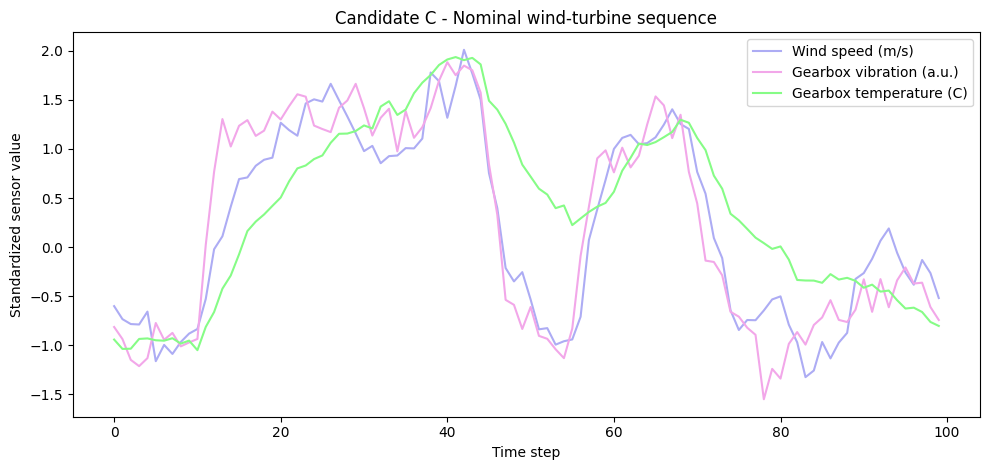

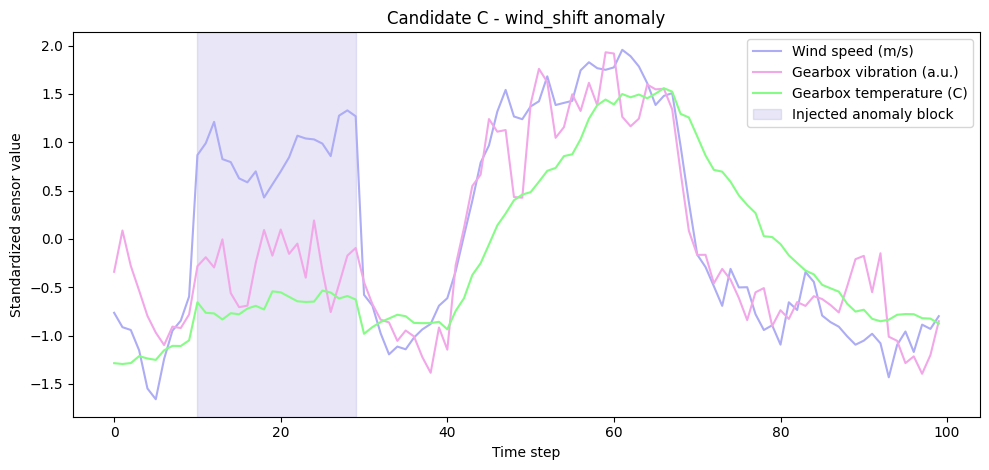

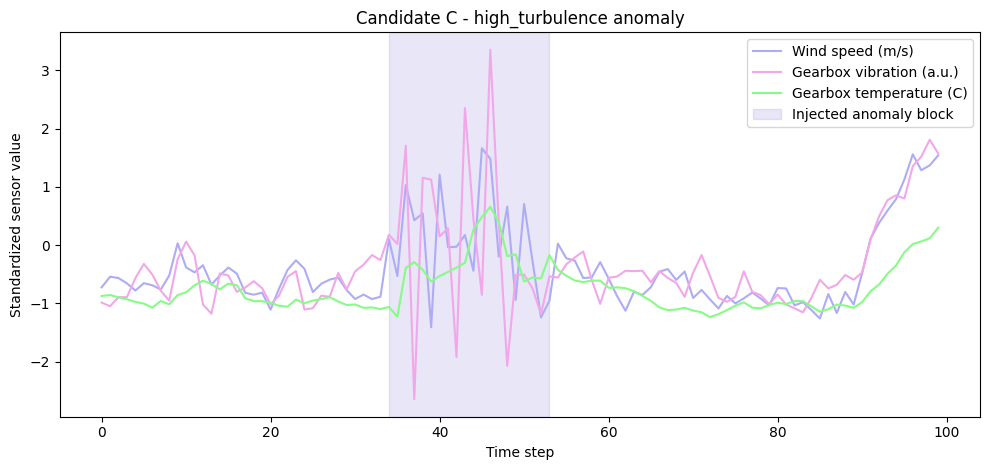

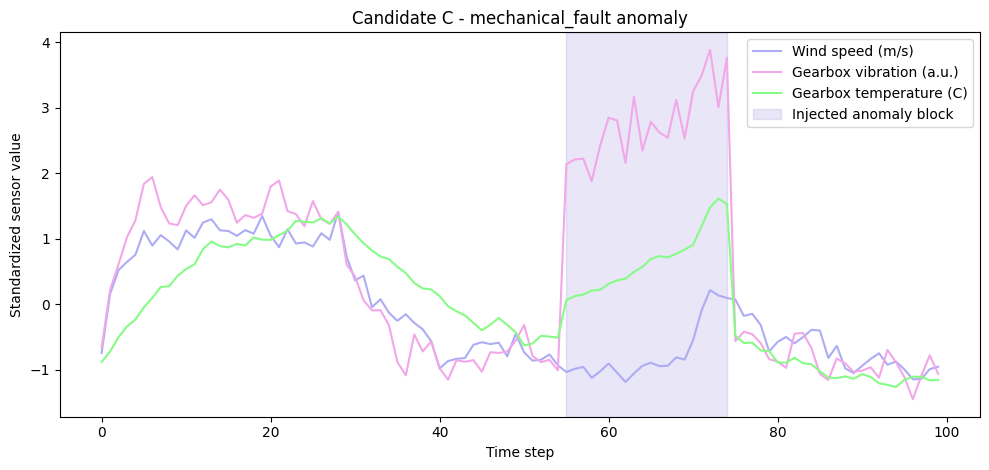

In [43]:

print('CANDIDATE C - DATA VISUALIZATION')
normal_index_candidate_c=int(np.flatnonzero(y_test_candidate_c==0)[0])
example_indices_candidate_c={a:int(np.flatnonzero(type_test_candidate_c==a)[0]) for a in CANDIDATE_C_ANOMALY_TYPES}

train_mean=X_train_candidate_c.mean(axis=(0,1)); train_std=X_train_candidate_c.std(axis=(0,1))

sensor_colors = [
        "#ADACF4",  # Blue
        "#F2A7E9",  # Orange
        "#86FC86",  # Green
]


def candidate_c_plot_sequence(index,title,filename):
    seq=(X_test_candidate_c[index]-train_mean)/train_std
    bounds=bounds_test_candidate_c[index]
    plt.figure(figsize=(10,4.8))
    for j,name in enumerate(CANDIDATE_C_SENSOR_NAMES): plt.plot(np.arange(CANDIDATE_C_T),seq[:,j],label=name, color=sensor_colors[j])
    if bounds[0]>=0: plt.axvspan(bounds[0],bounds[1]-1,alpha=0.15,label='Injected anomaly block', color='slateblue')
    plt.xlabel('Time step'); plt.ylabel('Standardized sensor value'); plt.title(title); plt.legend(); plt.tight_layout()
    plt.savefig(CANDIDATE_C_DIR/filename,dpi=180); plt.show()

candidate_c_plot_sequence(normal_index_candidate_c,'Candidate C - Nominal wind-turbine sequence','01_candidate_c_nominal_sequence.png')
for a in CANDIDATE_C_ANOMALY_TYPES:
    candidate_c_plot_sequence(example_indices_candidate_c[a],f'Candidate C - {a} anomaly',f'02_candidate_c_{a}_sequence.png')


CANDIDATE C - MODEL TRAINING


,Iteration,Changed-state fraction,Mean OC-SVM decision score
0,1,1.0000,0.427146
1,2,0.0058,0.436846


,Hidden state,Wind speed (m/s),Gearbox vibration (a.u.),Gearbox temperature (C)
0,0,8.192789,0.816877,56.401566
1,1,11.480399,1.201523,61.988210


,State 0,State 1
State 0,0.973946,0.026054
State 1,0.037731,0.962269


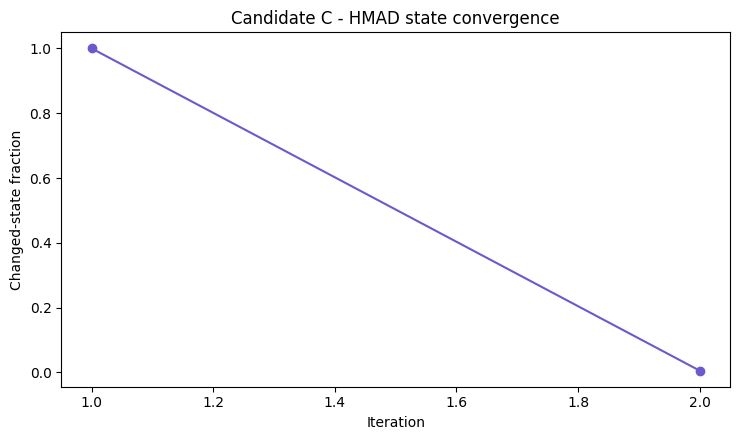

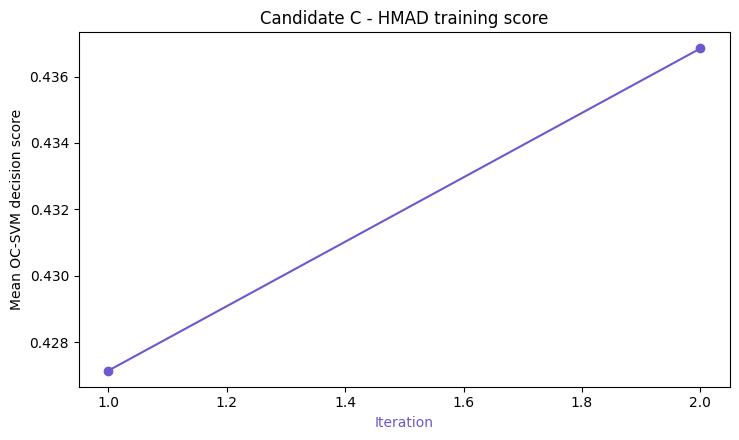

In [44]:

print('CANDIDATE C - MODEL TRAINING')
CANDIDATE_C_REPRESENTATIONS={'Flattened':candidate_c_flattened_features,'Global summary':candidate_c_global_summary_features,'Window summary':candidate_c_window_summary_features}
candidate_c_ocsvm_models={name:candidate_c_fit_ocsvm(fn(X_train_candidate_c),nu=CANDIDATE_C_NU) for name,fn in CANDIDATE_C_REPRESENTATIONS.items()}
candidate_c_hmad_model=candidate_c_fit_hmad(X_train_candidate_c,nu=CANDIDATE_C_NU,max_iter=CANDIDATE_C_MAX_ITER,tol=0.01)
candidate_c_hmad_history=candidate_c_hmad_model['history']
candidate_c_hmad_parameters=pd.DataFrame(candidate_c_hmad_model['means'],columns=CANDIDATE_C_SENSOR_NAMES); candidate_c_hmad_parameters.insert(0,'Hidden state',np.arange(CANDIDATE_C_K))
candidate_c_transition_table=pd.DataFrame(candidate_c_hmad_model['A'],index=[f'State {i}' for i in range(CANDIDATE_C_K)],columns=[f'State {i}' for i in range(CANDIDATE_C_K)])
candidate_c_hmad_history.to_csv(CANDIDATE_C_DIR/'hmad_training_history.csv',index=False)
candidate_c_hmad_parameters.to_csv(CANDIDATE_C_DIR/'hmad_state_means.csv',index=False)
candidate_c_transition_table.to_csv(CANDIDATE_C_DIR/'hmad_transition_matrix.csv')
display(candidate_c_hmad_history.round(6)); display(candidate_c_hmad_parameters.round(6)); display(candidate_c_transition_table.round(6))
plt.figure(figsize=(7.5,4.5)); plt.plot(candidate_c_hmad_history['Iteration'],candidate_c_hmad_history['Changed-state fraction'],marker='o', color='slateblue'); plt.xlabel('Iteration'); plt.ylabel('Changed-state fraction'); plt.title('Candidate C - HMAD state convergence'); plt.tight_layout(); plt.savefig(CANDIDATE_C_DIR/'03_candidate_c_hmad_state_convergence.png',dpi=180); plt.show()
plt.figure(figsize=(7.5,4.5)); plt.plot(candidate_c_hmad_history['Iteration'],candidate_c_hmad_history['Mean OC-SVM decision score'],marker='o', color='slateblue'); plt.xlabel('Iteration', color='slateblue'); plt.ylabel('Mean OC-SVM decision score'); plt.title('Candidate C - HMAD training score'); plt.tight_layout(); plt.savefig(CANDIDATE_C_DIR/'04_candidate_c_hmad_training_score.png',dpi=180); plt.show()


CANDIDATE C - FINAL TEST EVALUATION


,Method,ROC-AUC,Precision,Recall,F1,TN,FP,FN,TP
0,OC-SVM - Flattened,0.8806,0.692913,0.88,0.775330,61,39,12,88
1,OC-SVM - Global summary,0.9484,0.784483,0.91,0.842593,75,25,9,91
2,OC-SVM - Window summary,0.9150,0.741667,0.89,0.809091,69,31,11,89
3,Multivariate HMAD,0.8723,0.813187,0.74,0.774869,83,17,26,74


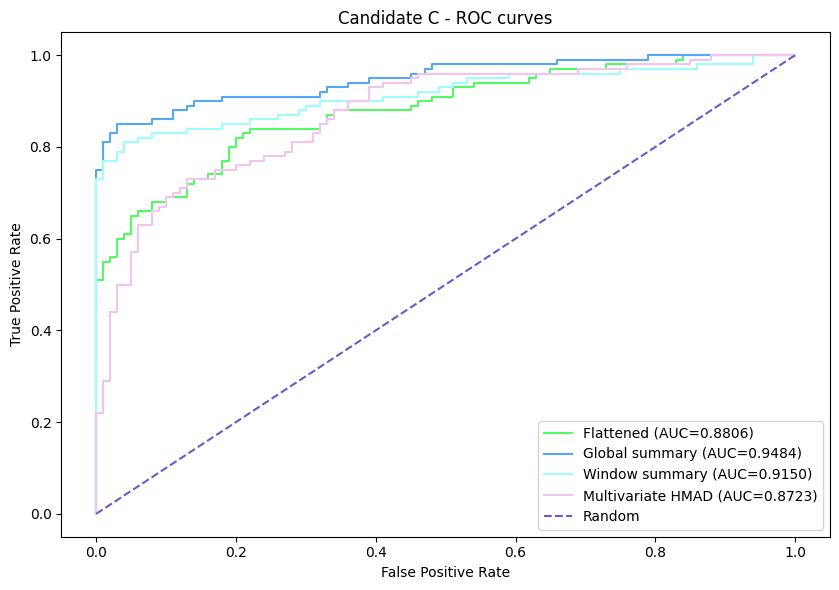

In [45]:

print('CANDIDATE C - FINAL TEST EVALUATION')
colors = {
    'Flattened': '#54FA64',
    'Global summary': '#54A8FA',
    'Window summary': '#9EFDFD',
    'Multivariate HMAD': '#F2C4EF',
}
candidate_c_runs={}; rows=[]
for name,fn in CANDIDATE_C_REPRESENTATIONS.items():
    run=candidate_c_score_ocsvm(candidate_c_ocsvm_models[name],fn(X_test_candidate_c),y_test_candidate_c); candidate_c_runs[name]=run
    rows.append({'Method':f'OC-SVM - {name}','ROC-AUC':run['ROC-AUC'],'Precision':run['Precision'],'Recall':run['Recall'],'F1':run['F1'],'TN':run['TN'],'FP':run['FP'],'FN':run['FN'],'TP':run['TP']})
candidate_c_hmad_run=candidate_c_score_hmad(candidate_c_hmad_model,X_test_candidate_c,y_test_candidate_c); candidate_c_runs['Multivariate HMAD']=candidate_c_hmad_run
run=candidate_c_hmad_run; rows.append({'Method':'Multivariate HMAD','ROC-AUC':run['ROC-AUC'],'Precision':run['Precision'],'Recall':run['Recall'],'F1':run['F1'],'TN':run['TN'],'FP':run['FP'],'FN':run['FN'],'TP':run['TP']})
candidate_c_metrics=pd.DataFrame(rows); candidate_c_metrics.to_csv(CANDIDATE_C_DIR/'candidate_c_final_metrics.csv',index=False); display(candidate_c_metrics.round(6))
plt.figure(figsize=(8.5,6))
for name,run in candidate_c_runs.items(): plt.plot(run['fpr'],run['tpr'],label=f"{name} (AUC={run['ROC-AUC']:.4f})", color=colors[name])
plt.plot([0,1],[0,1],linestyle='--',label='Random', color='slateblue'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('Candidate C - ROC curves'); plt.legend(loc='lower right'); plt.tight_layout(); plt.savefig(CANDIDATE_C_DIR/'05_candidate_c_roc_curves.png',dpi=180); plt.show()


CANDIDATE C - ANOMALY-TYPE BREAKDOWN


,Anomaly type,Method,ROC-AUC,Precision,Recall,F1
0,wind_shift,Flattened,0.769118,0.380952,0.705882,0.494845
1,wind_shift,Global summary,0.854412,0.500000,0.735294,0.595238
2,wind_shift,Window summary,0.755000,0.425926,0.676471,0.522727
3,wind_shift,Multivariate HMAD,0.843235,0.575000,0.676471,0.621622
4,high_turbulence,Flattened,0.876061,0.442857,0.939394,0.601942
5,high_turbulence,Global summary,0.993636,0.568966,1.000000,0.725275
6,high_turbulence,Window summary,0.997273,0.515625,1.000000,0.680412
7,high_turbulence,Multivariate HMAD,0.785455,0.514286,0.545455,0.529412
8,mechanical_fault,Flattened,1.000000,0.458333,1.000000,0.628571
9,mechanical_fault,Global summary,1.000000,0.568966,1.000000,0.725275


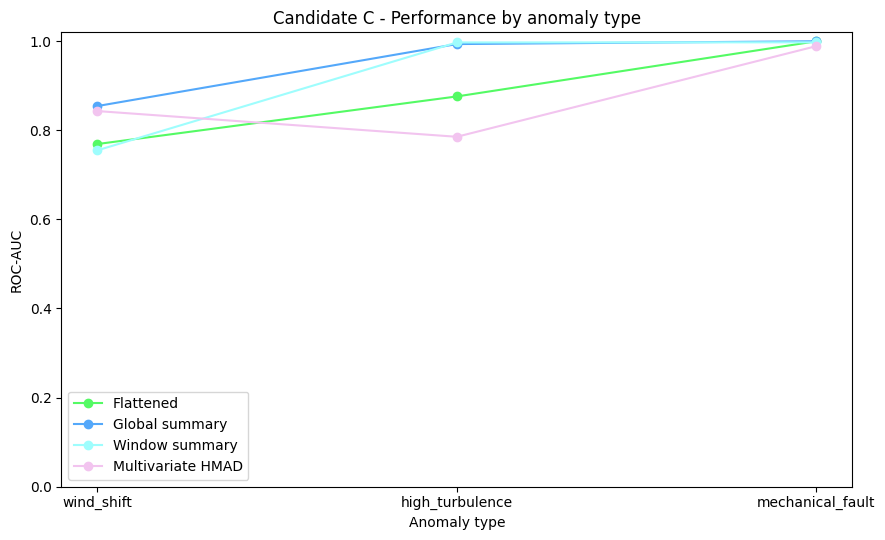

In [46]:

print('CANDIDATE C - ANOMALY-TYPE BREAKDOWN')
rows=[]
colors = {
    'Flattened': '#54FA64',
    'Global summary': '#54A8FA',
    'Window summary': '#9EFDFD',
    'Multivariate HMAD': '#F2C4EF',
}
for a in CANDIDATE_C_ANOMALY_TYPES:
    mask=(y_test_candidate_c==0)|(type_test_candidate_c==a); y=y_test_candidate_c[mask]
    for name,run in candidate_c_runs.items():
        r=candidate_c_evaluate_scores(y,run['normality_scores'][mask])
        rows.append({'Anomaly type':a,'Method':name,'ROC-AUC':r['ROC-AUC'],'Precision':r['Precision'],'Recall':r['Recall'],'F1':r['F1']})
candidate_c_type_metrics=pd.DataFrame(rows); candidate_c_type_metrics.to_csv(CANDIDATE_C_DIR/'candidate_c_anomaly_type_metrics.csv',index=False); display(candidate_c_type_metrics.round(6))
plt.figure(figsize=(9,5.5))
for name in candidate_c_runs:
    s=candidate_c_type_metrics[candidate_c_type_metrics['Method']==name]
    plt.plot(s['Anomaly type'],s['ROC-AUC'],marker='o',label=name,color=colors[name])
plt.xlabel('Anomaly type'); plt.ylabel('ROC-AUC'); plt.title('Candidate C - Performance by anomaly type'); plt.ylim(0,1.02); plt.legend(); plt.tight_layout(); plt.savefig(CANDIDATE_C_DIR/'06_candidate_c_anomaly_type_auc.png',dpi=180); plt.show()


CANDIDATE C - ANOMALY BLOCK-LENGTH SENSITIVITY


,Anomaly block length,Method,ROC-AUC,Precision,Recall,F1
0,5,OC-SVM - Flattened,0.74690,0.699029,0.72,0.709360
1,5,OC-SVM - Window summary,0.85180,0.722772,0.73,0.726368
2,5,Multivariate HMAD,0.61610,0.575000,0.23,0.328571
3,10,OC-SVM - Flattened,0.82740,0.693694,0.77,0.729858
4,10,OC-SVM - Window summary,0.90580,0.731707,0.90,0.807175
5,10,Multivariate HMAD,0.75870,0.773585,0.41,0.535948
6,20,OC-SVM - Flattened,0.89010,0.737288,0.87,0.798165
7,20,OC-SVM - Window summary,0.90900,0.747899,0.89,0.812785
8,20,Multivariate HMAD,0.82040,0.809524,0.68,0.739130
9,40,OC-SVM - Flattened,0.95070,0.730769,0.95,0.826087


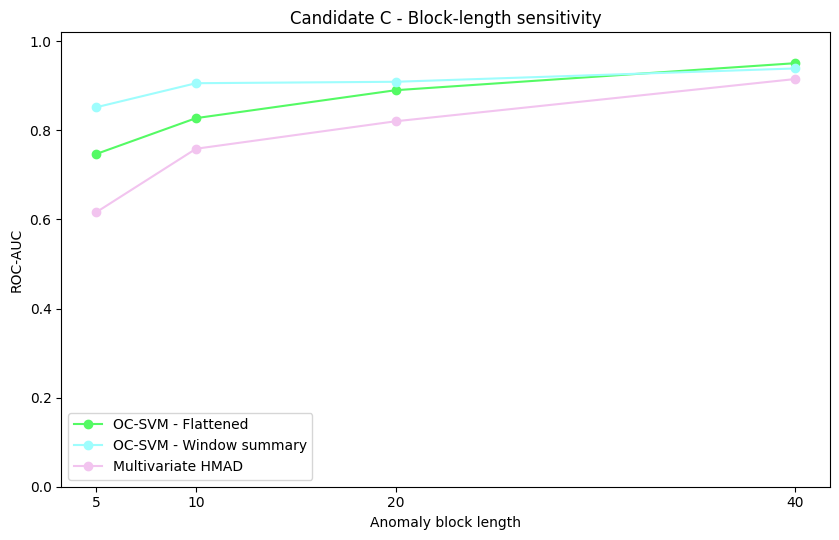

In [47]:

print('CANDIDATE C - ANOMALY BLOCK-LENGTH SENSITIVITY')
CANDIDATE_C_BLOCK_LENGTHS=[5,10,20,40]; rows=[]
colors = {
    'OC-SVM - Flattened': "#54FA64",
    'OC-SVM - Window summary': "#9EFDFD",
    'Multivariate HMAD': "#F2C4EF",
}
for L in CANDIDATE_C_BLOCK_LENGTHS:
    Xb,yb,_,tb,_=candidate_c_generate_dataset(CANDIDATE_C_N_TEST,CANDIDATE_C_TEST_ANOMALY_FRACTION,CANDIDATE_C_TEST_RANDOM_STATE+L,block_length=L)
    tests=[('OC-SVM - Flattened',candidate_c_score_ocsvm(candidate_c_ocsvm_models['Flattened'],candidate_c_flattened_features(Xb),yb)),('OC-SVM - Window summary',candidate_c_score_ocsvm(candidate_c_ocsvm_models['Window summary'],candidate_c_window_summary_features(Xb),yb)),('Multivariate HMAD',candidate_c_score_hmad(candidate_c_hmad_model,Xb,yb))]
    for name,r in tests: rows.append({'Anomaly block length':L,'Method':name,'ROC-AUC':r['ROC-AUC'],'Precision':r['Precision'],'Recall':r['Recall'],'F1':r['F1']})
candidate_c_sensitivity=pd.DataFrame(rows); candidate_c_sensitivity.to_csv(CANDIDATE_C_DIR/'candidate_c_block_length_sensitivity.csv',index=False); display(candidate_c_sensitivity.round(6))
plt.figure(figsize=(8.5,5.5))
for name in ['OC-SVM - Flattened','OC-SVM - Window summary','Multivariate HMAD']:
    s=candidate_c_sensitivity[candidate_c_sensitivity['Method']==name].sort_values('Anomaly block length'); plt.plot(s['Anomaly block length'],s['ROC-AUC'],marker='o',label=name, color=colors[name],)
plt.xlabel('Anomaly block length'); plt.ylabel('ROC-AUC'); plt.title('Candidate C - Block-length sensitivity'); plt.xticks(CANDIDATE_C_BLOCK_LENGTHS); plt.ylim(0,1.02); plt.legend(); plt.tight_layout(); plt.savefig(CANDIDATE_C_DIR/'07_candidate_c_block_length_sensitivity.png',dpi=180); plt.show()


CANDIDATE C - VITERBI PATH EXAMPLES


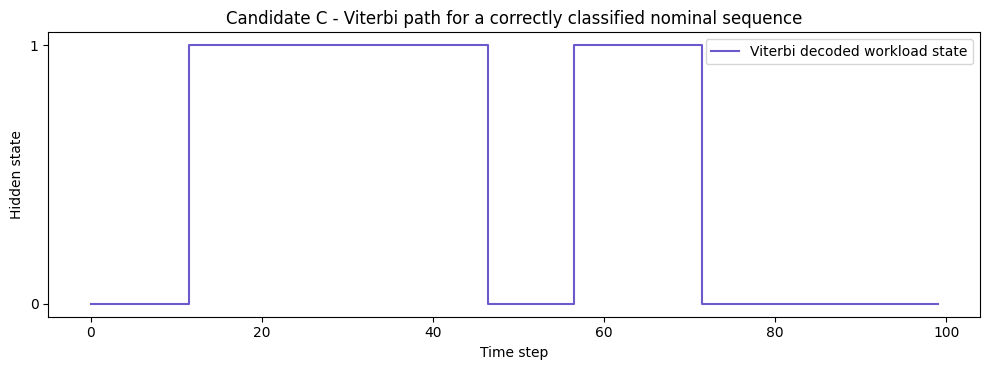

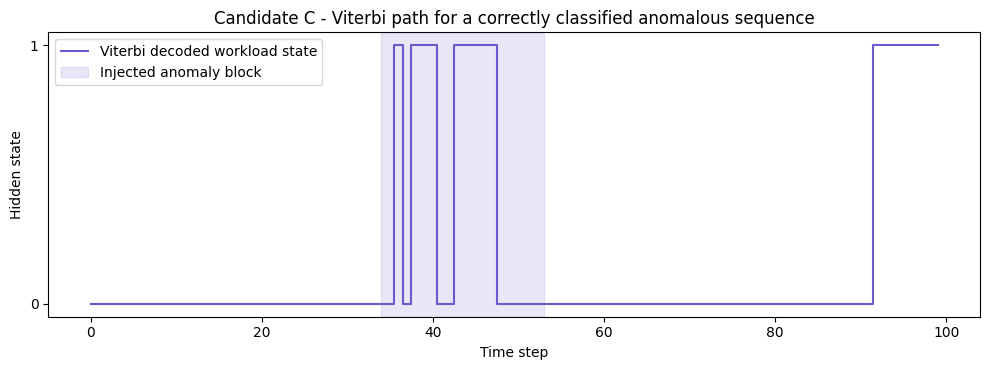

In [48]:

print('CANDIDATE C - VITERBI PATH EXAMPLES')
normal_good=np.flatnonzero((y_test_candidate_c==0)&(candidate_c_hmad_run['y_pred']==0)); normal_idx=int(normal_good[0] if len(normal_good) else np.flatnonzero(y_test_candidate_c==0)[0])
anom_good=np.flatnonzero((y_test_candidate_c==1)&(candidate_c_hmad_run['y_pred']==1)); anom_idx=int(anom_good[0] if len(anom_good) else np.flatnonzero(y_test_candidate_c==1)[0])

def plot_path(idx,title,filename):
    plt.figure(figsize=(10,3.8)); plt.step(np.arange(CANDIDATE_C_T),candidate_c_hmad_run['states'][idx],where='mid',label='Viterbi decoded workload state', color='slateblue')
    b=bounds_test_candidate_c[idx]
    if b[0]>=0: plt.axvspan(b[0],b[1]-1,alpha=0.15,label='Injected anomaly block', color='slateblue')
    plt.xlabel('Time step'); plt.ylabel('Hidden state'); plt.yticks(range(CANDIDATE_C_K)); plt.title(title); plt.legend(); plt.tight_layout(); plt.savefig(CANDIDATE_C_DIR/filename,dpi=180); plt.show()
plot_path(normal_idx,'Candidate C - Viterbi path for a correctly classified nominal sequence','08_candidate_c_viterbi_normal.png')
plot_path(anom_idx,'Candidate C - Viterbi path for a correctly classified anomalous sequence','09_candidate_c_viterbi_anomaly.png')


In [49]:

print('CANDIDATE C - FINAL CHECKS')
assert X_train_candidate_c.shape==(CANDIDATE_C_N_TRAIN,CANDIDATE_C_T,CANDIDATE_C_D)
assert X_test_candidate_c.shape==(CANDIDATE_C_N_TEST,CANDIDATE_C_T,CANDIDATE_C_D)
assert int(y_train_candidate_c.sum())==0 and int(y_test_candidate_c.sum())==100
assert set(np.unique(type_test_candidate_c[y_test_candidate_c==1]))==set(CANDIDATE_C_ANOMALY_TYPES)
expected_candidate_c_joint_dim=CANDIDATE_C_K**2+CANDIDATE_C_K*CANDIDATE_C_D
assert candidate_c_hmad_model['joint_features'].shape==(CANDIDATE_C_N_TRAIN,expected_candidate_c_joint_dim)
assert candidate_c_hmad_run['joint_features'].shape==(CANDIDATE_C_N_TEST,expected_candidate_c_joint_dim)
assert np.allclose(candidate_c_hmad_model['A'].sum(axis=1),1.0)
assert np.isfinite(candidate_c_hmad_model['means']).all() and np.all(candidate_c_hmad_model['variances']>0)
assert np.isfinite(candidate_c_metrics[['ROC-AUC','Precision','Recall','F1']].to_numpy()).all()
assert set(candidate_c_sensitivity['Anomaly block length'].unique())==set(CANDIDATE_C_BLOCK_LENGTHS)
summary=pd.DataFrame([
 {'Item':'Candidate','Value':'C - Computational Sustainability / Wind Turbine Data'},
 {'Item':'Training normal sequences','Value':CANDIDATE_C_N_TRAIN},
 {'Item':'Test sequences','Value':CANDIDATE_C_N_TEST},
 {'Item':'Test anomalies','Value':int(y_test_candidate_c.sum())},
 {'Item':'Sequence length','Value':CANDIDATE_C_T},
 {'Item':'Sensor channels','Value':CANDIDATE_C_D},
 {'Item':'Latent workload states','Value':CANDIDATE_C_K},
 {'Item':'HMAD joint feature dimension','Value':expected_candidate_c_joint_dim},
 {'Item':'OC-SVM Flattened ROC-AUC','Value':candidate_c_runs['Flattened']['ROC-AUC']},
 {'Item':'OC-SVM Global summary ROC-AUC','Value':candidate_c_runs['Global summary']['ROC-AUC']},
 {'Item':'OC-SVM Window summary ROC-AUC','Value':candidate_c_runs['Window summary']['ROC-AUC']},
 {'Item':'Multivariate HMAD ROC-AUC','Value':candidate_c_hmad_run['ROC-AUC']},
])
summary.to_csv(CANDIDATE_C_DIR/'candidate_c_summary.csv',index=False); display(summary)
print('CANDIDATE C BONUS IMPLEMENTATION COMPLETED')


CANDIDATE C - FINAL CHECKS


,Item,Value
0,Candidate,C - Computational Sustainability / Wind Turbin...
1,Training normal sequences,200
2,Test sequences,200
3,Test anomalies,100
4,Sequence length,100
5,Sensor channels,3
6,Latent workload states,2
7,HMAD joint feature dimension,10
8,OC-SVM Flattened ROC-AUC,0.8806
9,OC-SVM Global summary ROC-AUC,0.9484


CANDIDATE C BONUS IMPLEMENTATION COMPLETED
